# Denoising algorithm evaluation

## 1. Import libraries

In [1]:
from itertools import combinations
import random

import soundfile as sf
import numpy as np
import pandas as pd
from scipy.signal import detrend
from scipy.signal.windows import tukey
import scipy.ndimage as ndi
from scipy.ndimage import uniform_filter1d
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
import seaborn as sns

from src.summary_plots import summary_plots
from src.evaluation import ATEN_DB, FS, RMS_WIN, artifact_zones, hp15, insert_artifact, insert_artifacts, metrics, metrics_multi, process_mixture_multi, read_results, run_experiment
from src import remove_noise as rn
from src.remove_noise import MAX_EVENT, remove_noise

pd.set_option('display.max_columns', 500)

## 2. Algorithm

In [2]:
# Algorithm constants used by the figures (see summary_plots)
PARAMS = dict(G_FAC=rn.G_FAC, K=rn.K, Z_CLICK=rn.Z_CLICK, Z_TOLERANCE=rn.Z_TOLERANCE, AR_ORDER=rn.AR_ORDER,
              ISO_WIN=rn.ISO_WIN, ISOLATION=rn.ISOLATION, ISOLATION_IMPULSIVE=rn.ISOLATION_IMPULSIVE,
              ISOLATION_ALIGNED=rn.ISOLATION_ALIGNED, MAX_MISALIGN=rn.MAX_MISALIGN)

## 3. Example

In [15]:
file = "9728"
wav_file = fr"..\dataset\dataset\audio\{file}.wav"

signal, fs = sf.read(wav_file)
clean_signal, details = remove_noise(signal, fs, return_details=True)

summary_plots(signal, fs, details, PARAMS)

## 4. Selection of signals

### 4.1. Selection of clean signals

**Selection criteria:**
- 10 signals per each label ("Normal", "Wheeze", "Rhonchi", "Stridor")
- Only 1 fragment per patient
- No clicks, scrapes, or impacts audible or visible in the spectrogram.
- Go through the candidates in the order in which they appear

In [3]:
clean_signals = {
    "Normal": [19,42,86,113,129,278,334,348,382,403],
    "Wheeze": [192,309,859,1109,1339,1729,1964,2233,2601,2654],
    "Rhonchi": [2,4272,4622,4855,5372,7392,7830,8094,8499,9828],
    "Stridor": [4108,9423,9735,14033,14505,17812,23218,15817],
}

In [4]:
clean_dict = {}
count = 0
for label, ids in clean_signals.items():
    for id in ids:
        wav_file = fr"audio\{id}.wav"

        clean_dict[count] = {}
        clean_dict[count]["signal"], _ = sf.read(wav_file)
        clean_dict[count]["id"] = id
        clean_dict[count]["label"] = label
        
        count += 1

### 4.2. Selection of artifacts

**Selection criteria (artifacts):**

- 40 artifacts in total
- At most 1 artifact per patient
- Patients not used in the clean signal set
- The artifact must be clearly visible
- Fully contained in the fragment: not touching the beginning or the end
- Go through the fragments in a fixed pseudo-random order (seed = 42)
- If there are a lot of artifacts of the same type, discard them

In [5]:
artifacts = [
    {"id": 22260, "t_ini": 1.15, "t_fin": 1.19},
    {"id": 22115, "t_ini": 1.01, "t_fin": 1.08},
    {"id": 5085,  "t_ini": 0.18, "t_fin": 0.24},
    {"id": 4999,  "t_ini": 1.53, "t_fin": 1.58},
    {"id": 16489, "t_ini": 0.54, "t_fin": 0.57},
    {"id": 2183,  "t_ini": 0.95, "t_fin": 1.00},
    {"id": 4303,  "t_ini": 0.51, "t_fin": 0.61},
    {"id": 15159, "t_ini": 1.27, "t_fin": 1.34},
    {"id": 13234, "t_ini": 0.30, "t_fin": 0.33},
    {"id": 984,   "t_ini": 0.96, "t_fin": 0.99},
    {"id": 22005, "t_ini": 0.38, "t_fin": 0.45},
    {"id": 924,   "t_ini": 0.74, "t_fin": 0.80},
    {"id": 16375, "t_ini": 1.48, "t_fin": 1.55},
    {"id": 7882,  "t_ini": 0.39, "t_fin": 0.44},
    {"id": 1673,  "t_ini": 0.11, "t_fin": 0.16},
    {"id": 22951, "t_ini": 0.15, "t_fin": 0.19},
    {"id": 21671, "t_ini": 1.65, "t_fin": 1.75},
    {"id": 20260, "t_ini": 1.60, "t_fin": 1.65},
    {"id": 5132,  "t_ini": 1.22, "t_fin": 1.38},
    {"id": 852,   "t_ini": 0.75, "t_fin": 0.86},
    {"id": 16814, "t_ini": 0.06, "t_fin": 0.11},
    {"id": 9135,  "t_ini": 1.05, "t_fin": 1.09},
    {"id": 17690, "t_ini": 1.24, "t_fin": 1.29},
    {"id": 23533, "t_ini": 1.35, "t_fin": 1.47},
    {"id": 2512,  "t_ini": 1.67, "t_fin": 1.74},
    {"id": 22895, "t_ini": 1.01, "t_fin": 1.08},
    {"id": 5963,  "t_ini": 0.06, "t_fin": 0.40},
    {"id": 9009,  "t_ini": 0.26, "t_fin": 0.32},
    {"id": 7577,  "t_ini": 0.50, "t_fin": 0.56},
    {"id": 14131, "t_ini": 0.36, "t_fin": 0.44},
    {"id": 23570, "t_ini": 0.80, "t_fin": 0.87},
    {"id": 20493, "t_ini": 1.04, "t_fin": 1.22},
    {"id": 15420, "t_ini": 0.10, "t_fin": 0.15},
    {"id": 7458,  "t_ini": 1.44, "t_fin": 1.48},
    {"id": 9793,  "t_ini": 0.79, "t_fin": 0.87},
    {"id": 22175, "t_ini": 1.33, "t_fin": 1.36},
    {"id": 22497, "t_ini": 0.66, "t_fin": 0.76},
    {"id": 14269, "t_ini": 0.24, "t_fin": 0.31},
    {"id": 14166, "t_ini": 0.76, "t_fin": 0.79},
    {"id": 22699, "t_ini": 1.00, "t_fin": 1.10},
]

In [6]:
artifact_dict = {}
for i, artifact in enumerate(artifacts):
    wav_file = fr"audio\{artifact["id"]}.wav"

    full_signal, fs = sf.read(wav_file)
    j_ini = int(round((artifact["t_ini"]-0.005) * fs))
    j_fin = int(round((artifact["t_fin"]+0.005) * fs))

    artifact_x = full_signal[j_ini:j_fin]
    artifact_pre = detrend(artifact_x, type="constant")

    alpha_tukey = 0.01*fs / len(artifact_pre)
    win = tukey(len(artifact_pre), alpha=alpha_tukey)
    artifact_pre = artifact_pre * win

    artifact_dict[i] = artifact_pre
    

## 5. Experiment 1: Insertion of a single artifact

### 5.1. Generation of mixtures

- Each clean signal is mixed with each artifact (that fits in it) at `N_REPS` random positions and at each SNR of `SNR_LIST`.
- **Control:** each clean signal is also processed without any artifact (`art_id` and `snr_db` = `"Control"`, no position or mixture information). It measures what the algorithm does to a signal without artifacts (false clicks, signal changed).

In [27]:
SNR_LIST = [-30, -20, -10, -5, 0, 5, 10, 20]  # SNR list to test (locals, in dB)
N_REPS = 5                       # Number of random positions per pair
EDGE_DIST = int(0.1 * FS)        # Minimum distance of the artifact to the edges (samples)
SEED = 42                        # Random seed for reproducibility

In [28]:
def get_mixes():
    random.seed(SEED)

    mixes_info = []
    count = 0
    for i, clean in clean_dict.items():
        clean_signal = clean["signal"]
        for j, artifact in artifact_dict.items():
            fit_margin = len(clean_signal) - len(artifact) - 2*EDGE_DIST
            if fit_margin > 0:
                for k in range(N_REPS):
                    k0 = EDGE_DIST + random.randint(0, fit_margin)
                    for snr in SNR_LIST:
                        _, info = insert_artifact(clean_signal, artifact, k0, snr)
                        mixes_info.append({
                            "id": count,
                            "clean_id": i,
                            "clean_file": clean["id"],
                            "label": clean["label"],
                            "art_id": j,
                            "rep": k,
                            "snr_db": snr,
                            **info
                        })
                        count += 1

    # Control: each clean signal without any artifact (no position, no mixture information)
    for i, clean in clean_dict.items():
        mixes_info.append({
            "id": count,
            "clean_id": i,
            "clean_file": clean["id"],
            "label": clean["label"],
            "art_id": "Control",
            "snr_db": "Control",
        })
        count += 1

    exp_df = pd.DataFrame(mixes_info)
    exp_df = exp_df.astype({"rep": "Int64", "k0": "Int64", "k1": "Int64"})  # NaN in the control rows
    exp_df = exp_df.drop_duplicates(["clean_id", "art_id", "k0", "snr_db"])  # Same position drawn twice -> same mixture

    return exp_df

exp_df = get_mixes()
exp_df

,id,clean_id,clean_file,label,art_id,rep,snr_db,k0,k1,t0_s,art_duration_ms,g,p_local_rel_db,snr_global_db
0,0,0,19,Normal,0,0,-30,2224,2424,0.556,50.0,13.788755,1.361787,-14.563421
1,1,0,19,Normal,0,0,-20,2224,2424,0.556,50.0,4.360387,1.361787,-4.563421
2,2,0,19,Normal,0,0,-10,2224,2424,0.556,50.0,1.378875,1.361787,5.436579
3,3,0,19,Normal,0,0,-5,2224,2424,0.556,50.0,0.775399,1.361787,10.436579
4,4,0,19,Normal,0,0,0,2224,2424,0.556,50.0,0.436039,1.361787,15.436579
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60713,60713,33,14033,Stridor,Control,<NA>,Control,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
60714,60714,34,14505,Stridor,Control,<NA>,Control,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
60715,60715,35,17812,Stridor,Control,<NA>,Control,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
60716,60716,36,23218,Stridor,Control,<NA>,Control,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN


In [29]:
ej = exp_df[exp_df.art_id != "Control"].sample(1, random_state=SEED).iloc[0]
filas_ej = exp_df[(exp_df.clean_id == ej.clean_id) & (exp_df.art_id == ej.art_id) & (exp_df.rep == ej.rep)]

clean = clean_dict[ej.clean_id]["signal"]
artifact = artifact_dict[ej.art_id]
k0 = ej.k0
t = np.arange(len(clean)) / FS

fig = make_subplots(
    rows=len(filas_ej),
    cols=1,
    shared_xaxes=True,
    subplot_titles=[f"{f.snr_db} dB" for _, f in filas_ej.iterrows()],
    vertical_spacing=0.03,
)

for i, (_, f) in enumerate(filas_ej.iterrows(), start=1):
    snr = f.snr_db
    mixed, _ = insert_artifact(clean, artifact, k0, snr)

    fig.add_trace(
        go.Scatter(
            x=t, y=mixed,
            mode="lines",
            name="Signal with artifact",
            line=dict(color="darkorange", width=0.8),
            legendgroup="mixed",
            showlegend=(i == 1),
        ),
        row=i, col=1,
    )

    fig.add_trace(
        go.Scatter(
            x=t, y=clean,
            mode="lines",
            name="Clean signal",
            line=dict(color="black", width=0.8),
            legendgroup="clean",
            showlegend=(i == 1),
        ),
        row=i, col=1,
    )

    fig.add_vrect(
        x0=f.k0 / FS,
        x1=f.k1 / FS,
        fillcolor="blue",
        opacity=0.15,
        line_width=0,
        row=i, col=1,
    )


fig.update_layout(
    title=(
        f"{ej.label} {ej.clean_id} ({ej.clean_file}) + "
        f"Artifact {ej.art_id} "
        f"(Relative Local Power = {ej.p_local_rel_db:.1f} dB)"
    ),
    height=1000,
    width=1200,
    template="plotly_white",
    hovermode="x unified",
)

fig.update_xaxes(title_text="Time (s)", row=len(filas_ej), title_font=dict(size=14))
fig.add_annotation(
    text="Amplitude (A.U.)",
    xref="paper", yref="paper",
    x=-0.08, y=0.5,
    showarrow=False,
    textangle=-90,
    font=dict(size=14),
)

fig.show()

### 5.2. Processing & Metrics

In [30]:
f = exp_df[(exp_df.snr_db == -20)].sample(5, random_state=SEED).iloc[0] 

clean = clean_dict[f["clean_id"]]["signal"]
art = artifact_dict[f["art_id"]]
k0 = int(f["k0"])
k1 = k0 + len(art)

mixed, _ = insert_artifact(clean, art, k0, f["snr_db"])     # reconstruir la mezcla
out, det = remove_noise(mixed, FS, return_details=True)  # aplicar el algoritmo

ref = hp15(clean)       # limpia > 15 Hz
mix = hp15(mixed)       # mezcla > 15 Hz

m = metrics(ref, mix, out, k0, k1, det["click_span"])
print(pd.Series(m))

t = np.arange(len(ref)) / FS
z = slice(None)   # señal completa

fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.06,
)

# Subplot 1: señales
for y, name, color in [
    (mix[z], "Mezcla", "darkorange"),
    (out[z], "Salida", "royalblue"),
    (ref[z], "Limpia", "black"),
]:
    fig.add_trace(
        go.Scatter(
            x=t[z],
            y=y,
            mode="lines",
            name=name,
            line=dict(color=color, width=1),
        ),
        row=1, col=1,
    )

# Subplot 2: RMS
rms = lambda x: np.sqrt(uniform_filter1d(x**2, RMS_WIN))

for y, name, color in [
    (rms(mix)[z], "RMS mezcla", "darkorange"),
    (rms(out)[z], "RMS salida", "royalblue"),
    (rms(ref)[z], "RMS limpia", "black"),
]:
    fig.add_trace(
        go.Scatter(
            x=t[z],
            y=y,
            mode="lines",
            name=name,
            line=dict(color=color, width=1),
        ),
        row=2, col=1,
    )

# Zona del artefacto en ambos subplots
for row in (1, 2):
    fig.add_vrect(
        x0=k0 / FS,
        x1=k1 / FS,
        fillcolor="gray",
        opacity=0.2,
        line_width=0,
        layer="below",
        row=row, col=1,
    )

# Título y ejes
fig.update_layout(
    title=(
        f"{f['label']} {f['clean_file']} + artefacto {f['art_id']} "
        f"a {f['snr_db']} dB | "
        f"ΔSNR = {m['dsnr_db']:.1f} dB, "
        f"NMSE fuera = {m['nmse_out_zone_db']:.1f} dB"
    ),
    template="plotly_white",
    height=650,
    width=1200,
    hovermode="x unified",
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1,
    ),
)

fig.update_yaxes(title_text="Amplitud (U.A.)", row=1, col=1)
fig.update_yaxes(title_text="RMS (U.A.)", row=2, col=1)
fig.update_xaxes(title_text="Tiempo (s)", row=2, col=1)

fig.show()
summary_plots(mixed, FS, det, PARAMS)

detected                       True
n_false                           0
snr_in_db                -20.000512
snr_out_db                -1.766513
dsnr_db                   18.233999
attenuated                     True
nmse_out_zone_db         -51.946226
err_rms_max_loc_mix      836.874349
err_rms_max_loc_out       -0.138532
err_rms_mean_loc_mix       557.7749
err_rms_mean_loc_out       4.436892
err_rms_max_glob_mix     558.134041
err_rms_max_glob_out      -0.000158
err_rms_mean_glob_mix      57.37872
err_rms_mean_glob_out      0.450337
dtype: object


### 5.3. Execution of the experiment

`run_experiment` (see [`evaluation.py`](evaluation.py)) processes every mixture (and every control) in parallel with `multiprocessing` (one worker process per CPU core; `processes` to change it) and saves the metrics in `results/<csv_file>`.

In [24]:
results_df = run_experiment(exp_df, "experiment_1.csv", clean_dict, artifact_dict)

Mixtures:   0%|          | 0/60718 [00:00<?, ?it/s]

### 5.4. Results

In [3]:
results_df = read_results("experiment_1.csv")
results_df

,id,clean_id,clean_file,label,art_id,rep,snr_db,k0,k1,t0_s,art_duration_ms,g,p_local_rel_db,snr_global_db,detected,n_false,snr_in_db,snr_out_db,dsnr_db,attenuated,nmse_out_zone_db,err_rms_max_loc_mix,err_rms_max_loc_out,err_rms_mean_loc_mix,err_rms_mean_loc_out,err_rms_max_glob_mix,err_rms_max_glob_out,err_rms_mean_glob_mix,err_rms_mean_glob_out
0,0,0,19,Normal,0,0.0,-30,2224.0,2424.0,0.556,50.0,13.788755,1.361787,-14.563421,True,0,-29.999853,-3.474966,2.652489e+01,True,-44.686910,2756.579849,-24.610090,1527.199337,-16.929827,1786.905489,-6.105390e-04,84.378343,-9.271108e-01
1,1,0,19,Normal,0,0.0,-20,2224.0,2424.0,0.556,50.0,4.360387,1.361787,-4.563421,True,0,-19.999853,-2.705278,1.729457e+01,True,-49.119718,816.187136,-1.837039,441.242426,0.795917,505.184741,-1.934770e-04,24.378152,3.834876e-02
2,2,0,19,Normal,0,0.0,-10,2224.0,2424.0,0.556,50.0,1.378875,1.361787,5.436579,False,0,-9.999853,-9.999853,1.776357e-15,False,-49.956480,211.260109,211.260109,111.007645,111.007645,105.601958,1.056020e+02,6.132999,6.126937e+00
3,3,0,19,Normal,0,0.0,-5,2224.0,2424.0,0.556,50.0,0.775399,1.361787,10.436579,False,0,-4.999853,-4.999853,2.664535e-15,False,-50.027162,96.734328,96.734328,51.054306,51.054306,29.952287,2.995229e+01,2.820668,2.814606e+00
4,4,0,19,Normal,0,0.0,0,2224.0,2424.0,0.556,50.0,0.436039,1.361787,15.436579,False,0,0.000147,0.000147,1.928606e-15,False,-50.049755,40.754988,40.754988,21.911893,21.911893,-0.000019,-1.936467e-05,1.210597,1.204535e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60713,60713,33,14033,Stridor,Control,NaN,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,-312.346967,NaN,NaN,NaN,NaN,0.000000,-2.146893e-14,0.000000,-1.693728e-12
60714,60714,34,14505,Stridor,Control,NaN,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,-54.991803,NaN,NaN,NaN,NaN,0.000000,-1.539049e-14,0.000000,-4.303864e-03
60715,60715,35,17812,Stridor,Control,NaN,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,-74.983649,NaN,NaN,NaN,NaN,0.000000,-2.616836e-14,0.000000,4.221891e-05
60716,60716,36,23218,Stridor,Control,NaN,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,-312.018659,NaN,NaN,NaN,NaN,0.000000,-1.293224e-14,0.000000,-1.884035e-13


#### 5.4.1. Detection

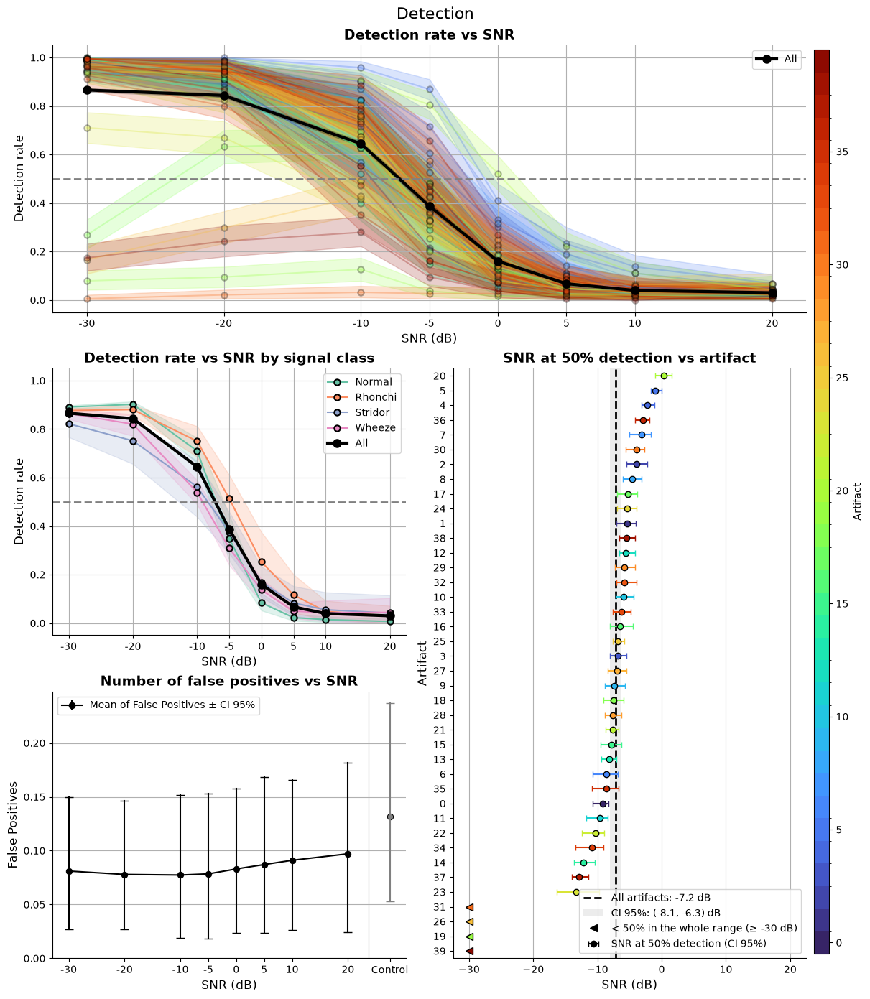

In [ ]:
from matplotlib.colors import ListedColormap, BoundaryNorm

def plot_detection(results_df):

    # ============================================================================ datos
    results_df = results_df.assign(snr_db=pd.to_numeric(results_df["snr_db"], errors="coerce"))   # copia (no modifica el original); ANTES de filtrar: controles -> NaN

    mix = results_df["art_id"] != "Control"
    mix_df = results_df[mix]

    art_order = sorted(mix_df["art_id"].unique(), key=lambda a: int(a))           # orden numérico: 0, 1, 2, …, 39
    art_colors = dict(zip(art_order, sns.color_palette("turbo", len(art_order))))  # mismo color en A, D y la barra
    snr_levels = np.sort(mix_df["snr_db"].unique())


    # ---------------------------------------------------------------- SNR al 50 % (D)
    def snr_at_50(rate, levels):
        """
        SNR al que la tasa de detección cruza 0,5 (interpolación lineal entre niveles). La detección baja al subir el
        SNR: se toma el último nivel con tasa >= 0,5 y se interpola hasta el siguiente.
        +inf: >= 0,5 hasta el último nivel (cruce por encima del rango); -inf: < 0,5 en todos (por debajo del rango).
        """
        above = rate >= 0.5
        if not above.any():
            return -np.inf
        i = np.where(above)[0].max()
        if i == len(rate) - 1:
            return np.inf
        r0, r1 = rate[i], rate[i + 1]
        return levels[i] + (0.5 - r0) * (levels[i + 1] - levels[i]) / (r1 - r0)


    # Aciertos y mezclas por (artefacto, señal limpia, SNR): arrays [art, clean, snr]
    clean_ids = sorted(mix_df["clean_id"].unique())
    g = mix_df.groupby(["art_id", "clean_id", "snr_db"])["detected"].agg(["sum", "count"])
    idx = pd.MultiIndex.from_product([art_order, clean_ids, snr_levels])
    S = g["sum"].reindex(idx, fill_value=0).to_numpy().reshape(len(art_order), len(clean_ids), len(snr_levels))
    Nn = g["count"].reindex(idx, fill_value=0).to_numpy().reshape(S.shape)

    # Bootstrap sobre las señales limpias (unidad independiente): pesos multinomiales
    N_BOOT = 1000
    rng = np.random.default_rng(0)
    W = rng.multinomial(len(clean_ids), np.full(len(clean_ids), 1 / len(clean_ids)), size=N_BOOT)   # (boot, clean)

    with np.errstate(invalid="ignore", divide="ignore"):
        rate_art = S.sum(1) / Nn.sum(1)                                            # (art, snr), estimación puntual
        rate_art_b = np.einsum("bc,acs->bas", W, S) / np.einsum("bc,acs->bas", W, Nn)   # (boot, art, snr)
        rate_all = S.sum((0, 1)) / Nn.sum((0, 1))                                  # global (como la curva negra de A)
        rate_all_b = np.einsum("bc,acs->bs", W, S) / np.einsum("bc,acs->bs", W, Nn)

    snr50 = np.array([snr_at_50(r, snr_levels) for r in rate_art])
    snr50_b = np.array([[snr_at_50(r, snr_levels) for r in rb] for rb in rate_art_b])   # (boot, art)
    snr50_all = snr_at_50(rate_all, snr_levels)
    snr50_all_b = np.array([snr_at_50(r, snr_levels) for r in rate_all_b])

    # IC 95 %: los cruces fuera de rango se acotan a los bordes del rango para calcular los percentiles
    lo_edge, hi_edge = snr_levels.min(), snr_levels.max()
    snr50_b_clip = np.clip(snr50_b, lo_edge, hi_edge)
    ci_lo, ci_hi = np.percentile(snr50_b_clip, [2.5, 97.5], axis=0)
    ci_all = np.percentile(np.clip(snr50_all_b, lo_edge, hi_edge), [2.5, 97.5])


    # ============================================================================ figura
    n_art = len(art_order)
    fig = plt.figure(figsize=(12, 9 + 0.12 * n_art), layout="constrained")
    gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1], width_ratios=[1, 1])

    ax_det = fig.add_subplot(gs[0, :])       # A: tasa de detección vs SNR (por artefacto + global)
    ax_lab = fig.add_subplot(gs[1, 0], sharey=ax_det)       # B: tasa de detección vs SNR por clase de la señal limpia
    ax_fp = fig.add_subplot(gs[2, 0])        # C: falsos positivos vs SNR
    ax_snr50 = fig.add_subplot(gs[1:, 1])    # D: SNR al 50 % por artefacto (dos filas)

    ax_det.set_xlabel("SNR (dB)", fontsize=12)
    ax_det.set_ylabel("Detection rate", fontsize=12)
    ax_det.set_title("Detection rate vs SNR", fontsize=14, fontweight="bold")

    ax_lab.set_xlabel("SNR (dB)", fontsize=12)
    ax_lab.set_ylabel("Detection rate", fontsize=12)
    ax_lab.set_title("Detection rate vs SNR by signal class", fontsize=14, fontweight="bold")

    ax_fp.set_xlabel("SNR (dB)", fontsize=12)
    ax_fp.set_ylabel("False Positives", fontsize=12)
    ax_fp.set_title("Number of false positives vs SNR", fontsize=14, fontweight="bold")

    ax_snr50.set_xlabel("SNR (dB)", fontsize=12)
    ax_snr50.set_ylabel("Artifact", fontsize=12)
    ax_snr50.set_title(r"SNR at 50% detection vs artifact", fontsize=14, fontweight="bold")

    fig.suptitle("Detection", fontsize=16)
    sns.despine(fig)

    # ---------------------------------------------------------------- A: tasa de detección
    sns.lineplot(data=mix_df, x="snr_db", y="detected", hue="art_id", hue_order=art_order, palette=art_colors,
                marker="o", markeredgecolor="black", markeredgewidth=1.5, linewidth=1.5, errorbar=("ci", 95),
                alpha=0.3, legend=False, ax=ax_det)
    sns.lineplot(data=mix_df, x="snr_db", y="detected", color="black", marker="o", markeredgecolor="black",
                markeredgewidth=3, linewidth=3, errorbar=("ci", 95), ax=ax_det, label="All")
    ax_det.axhline(0.5, linewidth=2, ls="--", color="gray")
    ax_det.set_xticks(snr_levels, labels=[f"{v:g}" for v in snr_levels])
    ax_det.legend(fontsize=10)
    ax_det.grid()

    # ---------------------------------------------------------------- B: tasa de detección por clase de la señal
    # Una fila por señal limpia y SNR (media sobre artefactos y posiciones): el IC refleja la variación entre señales
    per_clean_lab = mix_df.groupby(["clean_id", "label", "snr_db"], as_index=False)["detected"].mean()
    label_order = sorted(per_clean_lab["label"].unique())

    sns.lineplot(data=per_clean_lab, x="snr_db", y="detected", hue="label", hue_order=label_order, palette="Set2",
                marker="o", markeredgecolor="black", markeredgewidth=1.5, linewidth=1.5, errorbar=("ci", 95),
                err_style="band", ax=ax_lab)
    sns.lineplot(data=mix_df, x="snr_db", y="detected", color="black", marker="o", markeredgecolor="black",
                linewidth=3, markeredgewidth=3, errorbar=None, label="All", ax=ax_lab)
    ax_lab.axhline(0.5, linewidth=2, ls="--", color="gray")
    ax_lab.set_xticks(snr_levels, labels=[f"{v:g}" for v in snr_levels])
    ax_lab.legend(fontsize=10)
    ax_lab.grid()

    # ---------------------------------------------------------------- C: falsos positivos
    # Una fila por señal limpia y nivel de SNR (media sobre artefactos y posiciones)
    per_clean = (mix_df.groupby(["clean_id", "snr_db"], as_index=False)["n_false"].mean().assign(is_control=False))
    ctrl = results_df.loc[~mix, ["clean_id", "n_false"]].assign(is_control=True)   # una fila por señal limpia
    df_fp = pd.concat([per_clean, ctrl], ignore_index=True)

    step = np.min(np.diff(snr_levels)) if len(snr_levels) > 1 else 5
    x_ctrl = snr_levels.max() + 1.5 * step                                         # posición del control
    df_fp["x"] = np.where(df_fp["is_control"], x_ctrl, df_fp["snr_db"])

    sns.lineplot(data=df_fp, x="x", y="n_false", hue="is_control", palette={False: "black", True: "gray"},
                legend=False, errorbar=("ci", 95), err_style="bars", err_kws={"capsize": 4},
                marker="o", markeredgecolor="black", linewidth=1.5, ax=ax_fp)

    ax_fp.errorbar(x=[np.nan], y=[np.nan], yerr=[np.nan], color="black", linewidth=1.5, marker="o", markeredgecolor="black", label=r"Mean of False Positives $\pm$ CI 95%")
    ax_fp.set_xticks(list(snr_levels) + [x_ctrl], labels=[f"{v:g}" for v in snr_levels] + ["Control"])
    ax_fp.axvline((snr_levels.max() + x_ctrl) / 2, color="lightgray", lw=1, zorder=0)
    ax_fp.set_ylim(bottom=0)
    ax_fp.legend(fontsize=10)
    ax_fp.grid(axis="y")

    # ---------------------------------------------------------------- D: SNR al 50 % por artefacto
    order_c = np.argsort(-np.nan_to_num(snr50, posinf=1e9, neginf=-1e9))           # más sensible arriba
    for row, a in enumerate(order_c):
        col = art_colors[art_order[a]]
        est = snr50[a]
        if np.isposinf(est):                                                       # >= 50 % en todo el rango
            ax_snr50.plot(hi_edge, row, ">", color=col, mec="black", ms=7, zorder=3)
        elif np.isneginf(est):                                                     # < 50 % en todo el rango
            ax_snr50.plot(lo_edge, row, "<", color=col, mec="black", ms=7, zorder=3)
        else:
            ax_snr50.errorbar(est, row, xerr=[[max(est - ci_lo[a], 0)], [max(ci_hi[a] - est, 0)]],
                            fmt="o", color=col, mec="black", ms=6, capsize=3, elinewidth=1.5, zorder=3)

    if np.isfinite(snr50_all):
        ax_snr50.axvline(snr50_all, color="black", ls="--", lw=2, zorder=2, label=f"All artifacts: {snr50_all:.1f} dB")
        ax_snr50.axvspan(*ci_all, color="gray", alpha=0.15, lw=0, zorder=1,
                        label=f"CI 95%: ({ci_all[0]:.1f}, {ci_all[1]:.1f}) dB")

    # Entradas de leyenda en negro para los marcadores
    ax_snr50.errorbar([np.nan], [np.nan], xerr=[1], fmt="o", color="black", mec="black", ms=6, capsize=3,
                    elinewidth=1.5, label="SNR at 50% detection (CI 95%)")
    if np.isneginf(snr50).any():
        ax_snr50.plot([], [], "<", color="black", ms=7, ls="none",
                    label=f"< 50% in the whole range (≥ {lo_edge:g} dB)")
    if np.isposinf(snr50).any():
        ax_snr50.plot([], [], ">", color="black", ms=7, ls="none",
                    label=f"≥ 50% in the whole range (≤ {hi_edge:g} dB)")

    ax_snr50.set_yticks(range(n_art), labels=[art_order[a] for a in order_c])
    ax_snr50.set_ylim(n_art - 0.5, -0.5)
    ax_snr50.set_xlim(lo_edge - 0.5 * step, hi_edge + 0.5 * step)
    ax_snr50.legend(fontsize=10)
    ax_snr50.grid(axis="x")

    # ---------------------------------------------------------------- barra de colores: artifact_id
    cmap_art = ListedColormap([art_colors[a] for a in art_order])
    norm_art = BoundaryNorm(np.arange(-0.5, n_art), n_art)                        # un color discreto por artefacto
    sm = plt.cm.ScalarMappable(cmap=cmap_art, norm=norm_art)

    cb = fig.colorbar(sm, ax=[ax_det, ax_lab, ax_fp, ax_snr50], location="right",
                    fraction=0.02, pad=0.01, aspect=60)
    tick_idx = np.arange(0, n_art, 5)
    cb.set_ticks(tick_idx, labels=[art_order[i] for i in tick_idx])
    cb.set_label("Artifact", fontsize=10)

    plt.show()

plot_detection(results_df)

In [27]:
from matplotlib import colormaps
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.cm import ScalarMappable
from matplotlib.colors import BoundaryNorm, ListedColormap, to_hex
from matplotlib.figure import Figure
from matplotlib.lines import Line2D

from src.summary_plots import FONT, MPL_TICKFORMAT, mpl_nticks, mpl_range, rgba, rounded_rect


def _detection_geometry(fig_w, fig_h, dpi, spec):
    """
    Geometría de la figura de plot_detection tal como la calcula matplotlib (layout="constrained"): crea la misma
    figura SIN datos (títulos, etiquetas, límites, ticks, leyendas y barra de colores) y devuelve las cajas (px desde
    la esquina superior izquierda de la imagen recortada como bbox_inches="tight") de los ejes, textos y leyendas.
    spec: {"A"|"B"|"C"|"D": dict(title, xlabel, ylabel, xlim, ylim, xticks, yticks, legend, loc), "cb": dict(...)}
    """
    fig = Figure(figsize=(fig_w, fig_h), dpi=dpi, layout="constrained")
    canvas = FigureCanvasAgg(fig)
    gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1], width_ratios=[1, 1])
    axs = {"A": fig.add_subplot(gs[0, :])}
    axs["B"] = fig.add_subplot(gs[1, 0], sharey=axs["A"])
    axs["C"] = fig.add_subplot(gs[2, 0])
    axs["D"] = fig.add_subplot(gs[1:, 1])

    for k, ax in axs.items():
        s = spec[k]
        ax.set_title(s["title"], fontsize=14, fontweight="bold")
        ax.set_xlabel(s["xlabel"], fontsize=12)
        ax.set_ylabel(s["ylabel"], fontsize=12)
        if s.get("xticks"):
            ax.set_xticks(*s["xticks"])
        if s.get("yticks"):
            ax.set_yticks(*s["yticks"])
        ax.set_xlim(*s["xlim"])
        ax.set_ylim(*s["ylim"])
        ax.legend([Line2D([], [], marker="o") for _ in s["legend"]], s["legend"], loc=s["loc"], fontsize=10)
    fig.suptitle(spec["suptitle"], fontsize=16)

    c = spec["cb"]
    sm = ScalarMappable(cmap=ListedColormap(c["colors"]), norm=BoundaryNorm(np.arange(-0.5, len(c["colors"])),
                                                                           len(c["colors"])))
    cb = fig.colorbar(sm, ax=list(axs.values()), location="right", fraction=0.02, pad=0.01, aspect=60)
    cb.set_ticks(c["ticks"][0], labels=c["ticks"][1])
    cb.set_label(c["label"], fontsize=10)

    canvas.draw()
    r = canvas.get_renderer()
    tight = fig.get_tightbbox(r)
    pad = 0.1*dpi                                                                # pad_inches de bbox_inches="tight"
    x0, y_top = tight.x0*dpi - pad, tight.y1*dpi + pad

    def box(artist):
        bb = artist.get_window_extent(r)
        return dict(x0=bb.x0 - x0, x1=bb.x1 - x0, top=y_top - bb.y1, bottom=y_top - bb.y0)

    out = dict(size=(int(tight.width*dpi + 2*pad), int(tight.height*dpi + 2*pad)), suptitle=box(fig._suptitle))
    for k, ax in {**axs, "cb": cb.ax}.items():
        out[k] = dict(ax=box(ax), xlabel=box(ax.xaxis.label), ylabel=box(ax.yaxis.label), title=box(ax.title))
        if ax.get_legend():
            out[k]["legend"] = box(ax.get_legend())
            out[k]["legend_texts"] = [box(t) for t in ax.get_legend().get_texts()]
    return out


def plot_detection(results_df, width: int = None, dpi: float = 100) -> go.Figure:
    """
    Versión interactiva (plotly) de plot_detection (matplotlib/seaborn): mismo diseño (layout="constrained",
    figsize 12 x (9 + 0,12·n_art) in), tamaños, fuentes, colores y posiciones. La figura se recorta como el backend
    inline (bbox_inches="tight"), así que su tamaño coincide con el de la imagen de matplotlib.
    - A: tasa de detección vs SNR por artefacto (+ global "All"), con su IC 95 % (bootstrap, como seaborn)
    - B: tasa de detección vs SNR por clase de la señal limpia (+ global)
    - C: falsos positivos vs SNR (+ controles)
    - D: SNR al 50 % de detección por artefacto, con su IC 95 % (bootstrap sobre las señales limpias)
    - Barra de colores: color de cada artefacto (A, D)
    Interactividad: hover con los valores (artefacto, SNR, tasa, IC...) en A, B, C, D y en la barra de colores;
    clic en la leyenda para ocultar/mostrar cada categoría (en B, línea y banda a la vez); zoom en cada panel (A y B
    comparten el eje y, como sharey).
    - width: ancho de la figura (px). Solo cambia el ancho de los ejes (fuentes y márgenes no cambian). None -> como
      matplotlib
    - dpi: px por pulgada (matplotlib inline: 100). Todos los tamaños (fuentes, líneas, márgenes) escalan con él
    Las posiciones de los ejes y textos se toman del constrained layout de matplotlib aplicado a la misma figura sin
    datos (_detection_geometry). Limitaciones: las leyendas se colocan donde las pone loc="best" con estos datos
    (A, B: arriba a la derecha; C: arriba a la izquierda; D: abajo a la derecha); los símbolos de la leyenda de
    plotly no dibujan barras de error; la rejilla de plotly queda siempre debajo de las bandas; los IC por bootstrap
    usan una semilla fija (seaborn no), así que pueden diferir ligeramente de la versión matplotlib.
    """

    # ============================================================================ datos
    results_df = results_df.assign(snr_db=pd.to_numeric(results_df["snr_db"], errors="coerce"))   # copia (no modifica el original); ANTES de filtrar: controles -> NaN

    mix = results_df["art_id"] != "Control"
    mix_df = results_df[mix]

    art_order = sorted(mix_df["art_id"].unique(), key=lambda a: int(a))           # orden numérico: 0, 1, 2, …, 39
    n_art = len(art_order)
    turbo = colormaps["turbo"](np.linspace(0, 1, n_art + 2)[1:-1])                 # = sns.color_palette("turbo", n)
    art_colors = {a: to_hex(c) for a, c in zip(art_order, turbo)}                  # mismo color en A, D y la barra
    snr_levels = np.sort(mix_df["snr_db"].unique())


    # ---------------------------------------------------------------- SNR al 50 % (D)
    def snr_at_50(rate, levels):
        """
        SNR al que la tasa de detección cruza 0,5 (interpolación lineal entre niveles). La detección baja al subir el
        SNR: se toma el último nivel con tasa >= 0,5 y se interpola hasta el siguiente.
        +inf: >= 0,5 hasta el último nivel (cruce por encima del rango); -inf: < 0,5 en todos (por debajo del rango).
        """
        above = rate >= 0.5
        if not above.any():
            return -np.inf
        i = np.where(above)[0].max()
        if i == len(rate) - 1:
            return np.inf
        r0, r1 = rate[i], rate[i + 1]
        return levels[i] + (0.5 - r0) * (levels[i + 1] - levels[i]) / (r1 - r0)


    # Aciertos y mezclas por (artefacto, señal limpia, SNR): arrays [art, clean, snr]
    clean_ids = sorted(mix_df["clean_id"].unique())
    g = mix_df.groupby(["art_id", "clean_id", "snr_db"])["detected"].agg(["sum", "count"])
    idx = pd.MultiIndex.from_product([art_order, clean_ids, snr_levels])
    S = g["sum"].reindex(idx, fill_value=0).to_numpy().reshape(len(art_order), len(clean_ids), len(snr_levels))
    Nn = g["count"].reindex(idx, fill_value=0).to_numpy().reshape(S.shape)

    # Bootstrap sobre las señales limpias (unidad independiente): pesos multinomiales
    N_BOOT = 1000
    rng = np.random.default_rng(0)
    W = rng.multinomial(len(clean_ids), np.full(len(clean_ids), 1 / len(clean_ids)), size=N_BOOT)   # (boot, clean)

    with np.errstate(invalid="ignore", divide="ignore"):
        rate_art = S.sum(1) / Nn.sum(1)                                            # (art, snr), estimación puntual
        rate_art_b = np.einsum("bc,acs->bas", W, S) / np.einsum("bc,acs->bas", W, Nn)   # (boot, art, snr)
        rate_all = S.sum((0, 1)) / Nn.sum((0, 1))                                  # global (como la curva negra de A)
        rate_all_b = np.einsum("bc,acs->bs", W, S) / np.einsum("bc,acs->bs", W, Nn)

    snr50 = np.array([snr_at_50(r, snr_levels) for r in rate_art])
    snr50_b = np.array([[snr_at_50(r, snr_levels) for r in rb] for rb in rate_art_b])   # (boot, art)
    snr50_all = snr_at_50(rate_all, snr_levels)
    snr50_all_b = np.array([snr_at_50(r, snr_levels) for r in rate_all_b])

    # IC 95 %: los cruces fuera de rango se acotan a los bordes del rango para calcular los percentiles
    lo_edge, hi_edge = snr_levels.min(), snr_levels.max()
    snr50_b_clip = np.clip(snr50_b, lo_edge, hi_edge)
    ci_lo, ci_hi = np.percentile(snr50_b_clip, [2.5, 97.5], axis=0)
    ci_all = np.percentile(np.clip(snr50_all_b, lo_edge, hi_edge), [2.5, 97.5])


    # ---------------------------------------------------------------- media e IC 95 % (como seaborn)
    rng_ci = np.random.default_rng(1)

    def mean_ci(v):
        """Media e IC 95 % por bootstrap de las observaciones (errorbar=("ci", 95), n_boot=1000 de seaborn)"""
        v = np.asarray(v, float)
        v = v[~np.isnan(v)]
        n = len(v)
        if np.isin(v, (0, 1)).all():                                               # binaria: la media remuestreada
            boots = rng_ci.binomial(n, v.mean(), N_BOOT) / n                       # sigue una binomial (= bootstrap)
        else:
            boots = v[rng_ci.integers(0, n, (N_BOOT, n))].mean(1)
        return (v.mean(), *np.percentile(boots, [2.5, 97.5]))

    def ci_table(df, by, col):
        """Media, IC inferior e IC superior de col por grupo (índice: by)"""
        gb = df.groupby(by)
        return pd.DataFrame([mean_ci(gr[col]) for _, gr in gb], index=pd.Index(gb.groups.keys()) if isinstance(by, str)
                            else pd.MultiIndex.from_tuples(gb.groups.keys()), columns=["mean", "lo", "hi"])

    # A: por artefacto y global
    det_art = ci_table(mix_df, ["art_id", "snr_db"], "detected")
    det_all = ci_table(mix_df, "snr_db", "detected")

    # B: una fila por señal limpia y SNR (media sobre artefactos y posiciones): el IC refleja la variación entre señales
    per_clean_lab = mix_df.groupby(["clean_id", "label", "snr_db"], as_index=False)["detected"].mean()
    label_order = sorted(per_clean_lab["label"].unique())
    label_colors = dict(zip(label_order, [to_hex(c) for c in colormaps["Set2"].colors]))   # = palette="Set2"
    det_lab = ci_table(per_clean_lab, ["label", "snr_db"], "detected")

    # C: una fila por señal limpia y nivel de SNR (media sobre artefactos y posiciones); controles: una por señal
    per_clean = mix_df.groupby(["clean_id", "snr_db"], as_index=False)["n_false"].mean()
    fp_mix = ci_table(per_clean, "snr_db", "n_false")
    fp_ctrl = mean_ci(results_df.loc[~mix, "n_false"])
    step = np.min(np.diff(snr_levels)) if len(snr_levels) > 1 else 5
    x_ctrl = snr_levels.max() + 1.5 * step                                         # posición del control

    # D: orden de las filas
    order_c = np.argsort(-np.nan_to_num(snr50, posinf=1e9, neginf=-1e9))           # más sensible arriba


    # ============================================================================ geometría (como matplotlib)
    PT = dpi / 72                                                                  # px por punto
    pt = lambda v: v * PT
    em = pt(10)                                                                    # fuente de ticks y leyendas (px)
    dash = lambda lw: f"{pt(3.7*lw):.1f}px,{pt(1.6*lw):.1f}px"                    # línea "--" de ancho lw (pt)
    snr_labels = [f"{v:g}" for v in snr_levels]

    # Límites (autoscale de matplotlib: datos + 5 %)
    x_range = mpl_range(snr_levels)
    y_range = mpl_range(det_art.to_numpy(), det_all.to_numpy(), det_lab.to_numpy(), [0.5])   # A y B (sharey)
    fp_vals = np.r_[fp_mix.to_numpy().ravel(), fp_ctrl]
    x_range_fp = mpl_range(np.r_[snr_levels, x_ctrl])
    y_range_fp = [0, mpl_range(fp_vals)[1]]                                        # set_ylim(bottom=0)
    x_range_d = [lo_edge - 0.5 * step, hi_edge + 0.5 * step]
    y_range_d = [n_art - 0.5, -0.5]

    legend_d = []
    if np.isfinite(snr50_all):
        legend_d += [f"All artifacts: {snr50_all:.1f} dB", f"CI 95%: ({ci_all[0]:.1f}, {ci_all[1]:.1f}) dB"]
    if np.isneginf(snr50).any():
        legend_d.append(f"< 50% in the whole range (≥ {lo_edge:g} dB)")
    if np.isposinf(snr50).any():
        legend_d.append(f"≥ 50% in the whole range (≤ {hi_edge:g} dB)")
    legend_d.append("SNR at 50% detection (CI 95%)")
    fp_name = "Mean of False Positives ± CI 95%"

    tick_idx = np.arange(0, n_art, 5)
    spec = dict(
        suptitle="Detection",
        A=dict(title="Detection rate vs SNR", xlabel="SNR (dB)", ylabel="Detection rate", xlim=x_range,
               ylim=y_range, xticks=(snr_levels, snr_labels), legend=["All"], loc="upper right"),
        B=dict(title="Detection rate vs SNR by signal class", xlabel="SNR (dB)", ylabel="Detection rate",
               xlim=x_range, ylim=y_range, xticks=(snr_levels, snr_labels), legend=label_order + ["All"],
               loc="upper right"),
        C=dict(title="Number of false positives vs SNR", xlabel="SNR (dB)", ylabel="False Positives",
               xlim=x_range_fp, ylim=y_range_fp, xticks=(list(snr_levels) + [x_ctrl], snr_labels + ["Control"]),
               legend=[r"Mean of False Positives $\pm$ CI 95%"], loc="upper left"),
        D=dict(title=r"SNR at 50% detection vs artifact", xlabel="SNR (dB)", ylabel="Artifact", xlim=x_range_d,
               ylim=y_range_d, yticks=(range(n_art), [art_order[a] for a in order_c]), legend=legend_d,
               loc="lower right"),
        cb=dict(colors=[art_colors[a] for a in art_order], ticks=(tick_idx, [art_order[i] for i in tick_idx]),
                label="Artifact"),
    )

    fig_w, fig_h = 12, 9 + 0.12 * n_art
    geo = _detection_geometry(fig_w, fig_h, dpi, spec)
    for _ in range(3 if width else 0):                                             # ancho pedido: solo cambian los ejes
        if geo["size"][0] == width:
            break
        fig_w += (width - geo["size"][0]) / dpi
        geo = _detection_geometry(fig_w, fig_h, dpi, spec)
    W, H = geo["size"]
    X = lambda v: v / W                                                            # px -> papel
    Y = lambda v: 1 - v / H
    dom_x = lambda b: [X(b["x0"]), X(b["x1"])]
    dom_y = lambda b: [Y(b["bottom"]), Y(b["top"])]
    ax_len_pt = lambda b, k: (b["x1"] - b["x0"] if k == "x" else b["bottom"] - b["top"]) / PT

    def nticks(axis_range, b, k):
        """
        nticks de plotly que da los ticks de matplotlib (mpl_nticks). plotly redondea rango/nticks al paso 1-2-5
        SIGUIENTE cuando cae justo en uno (30/6 = 5 -> 10), así que en ese caso se pide un tick más
        """
        n = mpl_nticks(axis_range, ax_len_pt(b, k), 3 if k == "x" else 2)
        rough = (axis_range[1] - axis_range[0]) / n
        return n + 1 if np.isclose(rough / 10**np.floor(np.log10(rough)), [1, 2, 5]).any() else n

    axis_style = dict(showline=True, mirror=False, linecolor="black", linewidth=pt(0.8), ticks="outside",
                      ticklen=pt(3.5), tickwidth=pt(0.8), tickcolor="black", tickfont=dict(size=em),
                      showgrid=False, gridcolor="#b0b0b0", gridwidth=pt(0.8), zeroline=False, automargin=False,
                      tickformatstops=MPL_TICKFORMAT, exponentformat="none")      # sns.despine: sin ejes arriba/derecha
    x_style = dict(**axis_style, ticklabelstandoff=round(-2.2 * PT))
    gA, gB, gC, gD, gcb = (geo[k]["ax"] for k in ("A", "B", "C", "D", "cb"))
    layout = dict(
        # A
        xaxis=dict(domain=dom_x(gA), anchor="y", range=x_range, tickvals=snr_levels, ticktext=snr_labels,
                   **{**x_style, "showgrid": True}),
        yaxis=dict(domain=dom_y(gA), anchor="x", range=y_range, nticks=nticks(y_range, gA, "y"),
                   **{**axis_style, "showgrid": True}),
        # B
        xaxis2=dict(domain=dom_x(gB), anchor="y2", range=x_range, tickvals=snr_levels, ticktext=snr_labels,
                    **{**x_style, "showgrid": True}),
        yaxis2=dict(domain=dom_y(gB), anchor="x2", matches="y", range=y_range,
                    nticks=nticks(y_range, gB, "y"), **{**axis_style, "showgrid": True}),
        # C
        xaxis3=dict(domain=dom_x(gC), anchor="y3", range=x_range_fp, tickvals=list(snr_levels) + [x_ctrl],
                    ticktext=snr_labels + ["Control"], **x_style),
        yaxis3=dict(domain=dom_y(gC), anchor="x3", range=y_range_fp,
                    nticks=nticks(y_range_fp, gC, "y"), **{**axis_style, "showgrid": True}),
        # D
        xaxis4=dict(domain=dom_x(gD), anchor="y4", range=x_range_d,
                    nticks=nticks(x_range_d, gD, "x"), **{**x_style, "showgrid": True}),
        yaxis4=dict(domain=dom_y(gD), anchor="x4", range=y_range_d, tickvals=np.arange(n_art),
                    ticktext=[art_order[a] for a in order_c], **axis_style),
        # Barra de colores (ejes propios: un color discreto por artefacto)
        xaxis5=dict(domain=dom_x(gcb), anchor="y5", range=[0, 1], fixedrange=True, showline=True, mirror=True,
                    linecolor="black", linewidth=pt(0.8), showticklabels=False, ticks="", showgrid=False,
                    zeroline=False),
        yaxis5=dict(domain=dom_y(gcb), anchor="x5", side="right", range=[-0.5, n_art - 0.5], fixedrange=True,
                    tickvals=tick_idx, ticktext=[art_order[i] for i in tick_idx],
                    minor=dict(tickvals=np.arange(-0.5, n_art), ticks="outside", ticklen=pt(2), tickwidth=pt(0.6),
                               tickcolor="black", showgrid=False),
                    **{**axis_style, "mirror": True}),
    )

    # Leyendas: una leyenda de plotly por elemento, en la posición del texto de matplotlib (el texto de un elemento
    # de plotly empieza 40 px a la derecha de la x de la leyenda), y un marco común con esquinas redondeadas
    legends, shapes, n_leg = {}, [], 0

    def legend_items(key, names):
        nonlocal n_leg
        ids = []
        for name, t in zip(names, geo[key]["legend_texts"]):
            n_leg += 1
            lid = "legend" if n_leg == 1 else f"legend{n_leg}"
            legends[lid] = dict(x=X(t["x0"] - 40), y=Y((t["top"] + t["bottom"]) / 2 - 0.1 * em), xanchor="left",
                                yanchor="middle", orientation="h", bgcolor="rgba(0, 0, 0, 0)", borderwidth=0,
                                font=dict(size=em), groupclick="togglegroup", itemwidth=30)
            ids.append(lid)
        b = geo[key]["legend"]
        shapes.append(dict(type="path", xref="paper", yref="paper", layer="above", fillcolor="rgba(255, 255, 255, 0.8)",
                           line=dict(color="#cccccc", width=pt(1)),
                           path=rounded_rect(X(b["x0"]), X(b["x1"]), Y(b["bottom"]), Y(b["top"]), 0.2 * em, W, H)))
        return dict(zip(names, ids))

    leg_A = legend_items("A", ["All"])
    leg_B = legend_items("B", label_order + ["All"])
    leg_C = legend_items("C", [fp_name])
    leg_D = legend_items("D", legend_d)

    fig = go.Figure()

    def line_trace(x, y, color, lw, mew, alpha=1.0, ms=6, mec="#000000", **kw):
        """Línea con marcadores "o" (sns.lineplot(marker="o")); alpha en línea y marcadores como Line2D"""
        return go.Scatter(x=x, y=y, mode="lines+markers", line=dict(color=rgba(color, alpha), width=pt(lw)),
                          marker=dict(size=pt(ms), color=rgba(color, alpha),
                                      line=dict(color=rgba(mec, alpha), width=pt(mew))), **kw)

    def band_trace(x, lo, hi, color, **kw):
        """Banda del IC 95 % (fill_between, alpha 0.2 de seaborn)"""
        return go.Scatter(x=np.r_[x, x[::-1]], y=np.r_[hi, lo[::-1]], mode="lines", fill="toself",
                          fillcolor=rgba(color, 0.2), line=dict(width=0), hoverinfo="skip", showlegend=False, **kw)

    hover_rate = ("%{fullData.name}<br>SNR: %{x:g} dB<br>Detection rate: %{y:.3f}<br>"
                  "CI 95%: (%{customdata[0]:.3f}, %{customdata[1]:.3f})<extra></extra>")

    # ---------------------------------------------------------------- A: tasa de detección
    # Bandas debajo de todas las líneas (zorder 1 < 2 en matplotlib)
    for a in art_order:
        d = det_art.loc[a]
        fig.add_trace(band_trace(snr_levels, d["lo"].to_numpy(), d["hi"].to_numpy(), art_colors[a],
                                 xaxis="x", yaxis="y", legendgroup=f"art{a}"))
    fig.add_trace(band_trace(snr_levels, det_all["lo"].to_numpy(), det_all["hi"].to_numpy(), "#000000",
                             xaxis="x", yaxis="y", legendgroup="all_A", legend=leg_A["All"]))
    for a in art_order:
        d = det_art.loc[a]
        fig.add_trace(line_trace(snr_levels, d["mean"], art_colors[a], 1.5, 1.5, alpha=0.3, name=f"Artifact {a}",
                                 customdata=d[["lo", "hi"]].to_numpy(), hovertemplate=hover_rate, xaxis="x",
                                 yaxis="y", showlegend=False, legendgroup=f"art{a}"))
    fig.add_trace(line_trace(snr_levels, det_all["mean"], "#000000", 3, 3, name="All",
                             customdata=det_all[["lo", "hi"]].to_numpy(), hovertemplate=hover_rate, xaxis="x",
                             yaxis="y", legend=leg_A["All"], legendgroup="all_A"))

    # ---------------------------------------------------------------- B: tasa de detección por clase de la señal
    for lab in label_order:
        d = det_lab.loc[lab]
        fig.add_trace(band_trace(snr_levels, d["lo"].to_numpy(), d["hi"].to_numpy(), label_colors[lab],
                                 xaxis="x2", yaxis="y2", legend=leg_B[lab], legendgroup=f"lab_{lab}"))
    for lab in label_order:
        d = det_lab.loc[lab]
        fig.add_trace(line_trace(snr_levels, d["mean"], label_colors[lab], 1.5, 1.5, name=lab,
                                 customdata=d[["lo", "hi"]].to_numpy(), hovertemplate=hover_rate, xaxis="x2",
                                 yaxis="y2", legend=leg_B[lab], legendgroup=f"lab_{lab}"))
    fig.add_trace(line_trace(snr_levels, det_all["mean"], "#000000", 3, 3, name="All",
                             hovertemplate="All<br>SNR: %{x:g} dB<br>Detection rate: %{y:.3f}<extra></extra>",
                             xaxis="x2", yaxis="y2", legend=leg_B["All"], legendgroup="all_B"))

    # ---------------------------------------------------------------- C: falsos positivos
    hover_fp = ("%{customdata[2]}<br>False positives (mean): %{y:.3f}<br>"
                "CI 95%: (%{customdata[0]:.3f}, %{customdata[1]:.3f})<extra></extra>")
    error_fp = lambda m, lo, hi, color: dict(type="data", symmetric=False, array=np.asarray(hi) - m,
                                             arrayminus=m - np.asarray(lo), color=color, thickness=pt(1.5),
                                             width=pt(4))
    m = fp_mix["mean"].to_numpy()
    fig.add_trace(line_trace(snr_levels, m, "#000000", 1.5, 0.75, name=fp_name,
                             error_y=error_fp(m, fp_mix["lo"], fp_mix["hi"], "#000000"),
                             customdata=np.c_[fp_mix[["lo", "hi"]].to_numpy(), [f"SNR: {v} dB" for v in snr_labels]],
                             hovertemplate=hover_fp, xaxis="x3", yaxis="y3", legend=leg_C[fp_name],
                             legendgroup="fp"))
    fig.add_trace(line_trace([x_ctrl], [fp_ctrl[0]], "#808080", 1.5, 0.75, name="Control",
                             error_y=error_fp(np.array([fp_ctrl[0]]), [fp_ctrl[1]], [fp_ctrl[2]], "#808080"),
                             customdata=[[fp_ctrl[1], fp_ctrl[2], "Control (no artifact)"]], hovertemplate=hover_fp,
                             xaxis="x3", yaxis="y3", showlegend=False, legend=leg_C[fp_name], legendgroup="fp"))
    shapes.append(dict(type="line", xref="x3", yref="y3 domain", x0=(snr_levels.max() + x_ctrl) / 2,
                       x1=(snr_levels.max() + x_ctrl) / 2, y0=0, y1=1, layer="below",
                       line=dict(color="#d3d3d3", width=pt(1))))

    # ---------------------------------------------------------------- D: SNR al 50 % por artefacto
    if np.isfinite(snr50_all):
        shapes.append(dict(type="rect", xref="x4", yref="y4 domain", x0=ci_all[0], x1=ci_all[1], y0=0, y1=1,
                           layer="below", fillcolor=rgba("#808080", 0.15), line=dict(width=0),
                           name=legend_d[1], showlegend=True, legend=leg_D[legend_d[1]]))
        shapes.append(dict(type="line", xref="x4", yref="y4 domain", x0=snr50_all, x1=snr50_all, y0=0, y1=1,
                           layer="below", line=dict(color="#000000", width=pt(2), dash=dash(2)),
                           name=legend_d[0], showlegend=True, legend=leg_D[legend_d[0]]))

    name_lo, name_hi, name_50 = (f"< 50% in the whole range (≥ {lo_edge:g} dB)",
                                 f"≥ 50% in the whole range (≤ {hi_edge:g} dB)", "SNR at 50% detection (CI 95%)")
    for row, a in enumerate(order_c):
        col, est, art = art_colors[art_order[a]], snr50[a], art_order[a]
        if np.isinf(est):                                                          # cruce fuera del rango
            name = name_hi if est > 0 else name_lo
            fig.add_trace(go.Scatter(x=[hi_edge if est > 0 else lo_edge], y=[row], mode="markers", name=name,
                                     marker=dict(symbol="triangle-right" if est > 0 else "triangle-left", size=pt(7),
                                                 color=col, line=dict(color="black", width=pt(1))),
                                     hovertemplate=f"Artifact {art}<br>{name}<extra></extra>", xaxis="x4",
                                     yaxis="y4", showlegend=False, legend=leg_D[name], legendgroup=name))
        else:
            fig.add_trace(go.Scatter(x=[est], y=[row], mode="markers", name=name_50,
                                     marker=dict(size=pt(6), color=col, line=dict(color="black", width=pt(1))),
                                     error_x=dict(type="data", symmetric=False, array=[max(ci_hi[a] - est, 0)],
                                                  arrayminus=[max(est - ci_lo[a], 0)], color=col,
                                                  thickness=pt(1.5), width=pt(3)),
                                     hovertemplate=(f"Artifact {art}<br>SNR at 50% detection: {est:.1f} dB<br>"
                                                    f"CI 95%: ({ci_lo[a]:.1f}, {ci_hi[a]:.1f}) dB<extra></extra>"),
                                     xaxis="x4", yaxis="y4", showlegend=False, legend=leg_D[name_50],
                                     legendgroup=name_50))
    # Entradas de leyenda en negro para los marcadores
    for name, symbol, size in [(name_lo, "triangle-left", 7), (name_hi, "triangle-right", 7), (name_50, "circle", 6)]:
        if name in leg_D:
            fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", name=name, xaxis="x4", yaxis="y4",
                                     marker=dict(symbol=symbol, size=pt(size), color="black",
                                                 line=dict(color="black", width=pt(1))),
                                     legend=leg_D[name], legendgroup=name))

    # ---------------------------------------------------------------- barra de colores: artifact_id
    colorscale = [[(k + e) / n_art, art_colors[a]] for k, a in enumerate(art_order) for e in (0, 1)]
    fig.add_trace(go.Heatmap(x=[0, 1], y=np.arange(-0.5, n_art), z=np.arange(n_art)[:, None], zmin=-0.5,
                             zmax=n_art - 0.5, colorscale=colorscale, showscale=False, xaxis="x5", yaxis="y5",
                             text=np.array(art_order)[:, None], hovertemplate="Artifact %{text}<extra></extra>"))

    # ---------------------------------------------------------------- líneas y = 0,5 (A, B)
    for ax in ("", "2"):
        shapes.append(dict(type="line", xref=f"x{ax} domain", yref=f"y{ax}", x0=0, x1=1, y0=0.5, y1=0.5,
                           layer="above", line=dict(color="#808080", width=pt(2), dash=dash(2))))

    # ---------------------------------------------------------------- títulos y etiquetas
    def ann(s, b, size, rotate=False):
        """Texto centrado en la caja b de matplotlib (subido 0,1 em: Arial queda más baja que DejaVu Sans)"""
        cx, cy = (b["x0"] + b["x1"]) / 2, (b["top"] + b["bottom"]) / 2
        if rotate:
            cx -= 0.1 * pt(size)
        else:
            cy -= 0.1 * pt(size)
        return dict(text=s, x=X(cx), y=Y(cy), xref="paper", yref="paper", xanchor="center", yanchor="middle",
                    showarrow=False, font=dict(size=pt(size)), textangle=-90 if rotate else 0)

    annotations = [ann("Detection", geo["suptitle"], 16)]
    for k in ("A", "B", "C", "D"):
        s = spec[k]
        annotations += [ann(f"<b>{s['title']}</b>", geo[k]["title"], 14), ann(s["xlabel"], geo[k]["xlabel"], 12),
                        ann(s["ylabel"], geo[k]["ylabel"], 12, rotate=True)]
    annotations.append(ann("Artifact", geo["cb"]["ylabel"], 10, rotate=True))

    fig.update_layout(
        **layout, **legends, width=W, height=H, margin=dict(l=0, r=0, t=0, b=0, autoexpand=False),
        annotations=annotations, shapes=shapes, font=dict(family=FONT, size=em, color="black"),
        paper_bgcolor="white", plot_bgcolor="white", hovermode="closest", template="none"
    )
    return fig

plot_detection(results_df).show()

#### 5.4.2. Elimination

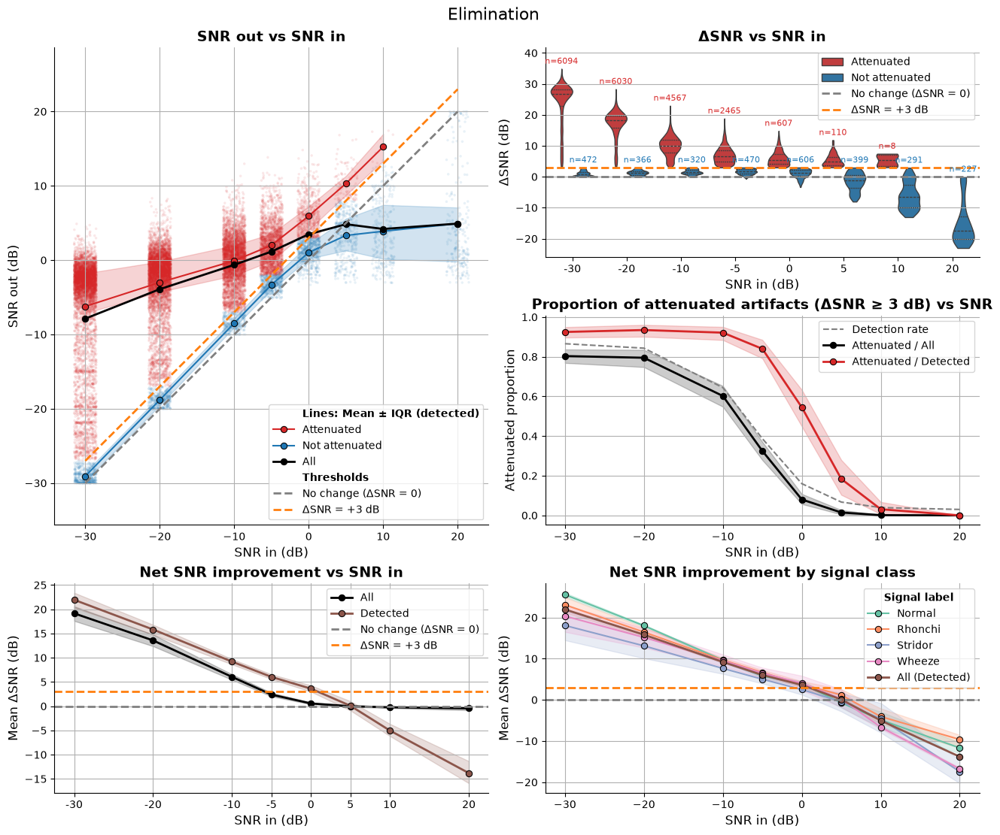

In [5]:
from matplotlib.pyplot import Line2D

def plot_elimination(results_df):

    # ============================================================================ constantes de estilo
    GROUPS = ["Attenuated", "Not attenuated"]
    PALETTE = {"Attenuated": "tab:red", "Not attenuated": "tab:blue"}   # mismos colores en A y B
    C_DETECTED = "tab:brown"                                            # "Detected" en D y E
    LBL_NOCHANGE = "No change (ΔSNR = 0)"
    LBL_ATEN = f"ΔSNR = +{ATEN_DB} dB"
    LINE_KW = dict(marker="o", markeredgecolor="black")                 # estilo común de las curvas


    def add_references(ax, labels=True):
        """Líneas horizontales de referencia: ΔSNR = 0 y ΔSNR = +ATEN_DB."""
        ax.axhline(0, color="gray", ls="--", lw=2, label=LBL_NOCHANGE if labels else None)
        ax.axhline(ATEN_DB, color="tab:orange", ls="--", lw=2, label=LBL_ATEN if labels else None)


    # ============================================================================ datos
    mix_df = results_df[results_df["art_id"] != "Control"].astype({"snr_db": float})   # copia: results_df no se modifica

    # Detectados, separados en atenuados (ΔSNR >= ATEN_DB) y no atenuados
    det = mix_df[mix_df["detected"] == 1].copy()
    det["group"] = np.where(det["dsnr_db"] >= ATEN_DB, "Attenuated", "Not attenuated")
    lv = np.sort(det["snr_db"].unique())                                # niveles de SNR

    # C: proporciones (una fila por señal limpia y SNR)
    pc_all = (mix_df.assign(att=(mix_df["detected"] == 1) & (mix_df["dsnr_db"] >= ATEN_DB))
            .groupby(["clean_id", "snr_db"], as_index=False)
            .agg(att=("att", "mean"), det=("detected", "mean")))
    pc_det = (det.assign(att=det["group"] == "Attenuated")
            .groupby(["clean_id", "snr_db"], as_index=False)["att"].mean())

    # D y E: ΔSNR medio (una fila por señal limpia y SNR); no detectados -> ΔSNR = 0
    net_all = (mix_df.assign(dsnr=mix_df["dsnr_db"].where(mix_df["detected"] == 1, 0.0))
            .groupby(["clean_id", "snr_db"], as_index=False)["dsnr"].mean())
    net_det = det.groupby(["clean_id", "snr_db"], as_index=False)["dsnr_db"].mean()
    net_lab = det.groupby(["clean_id", "label", "snr_db"], as_index=False)["dsnr_db"].mean()
    label_order = sorted(net_lab["label"].unique())


    # ============================================================================ figura
    fig = plt.figure(figsize=(13, 11), layout="constrained")
    gs = fig.add_gridspec(3, 2, width_ratios=[1, 1], height_ratios=[1, 1, 1])

    ax_io = fig.add_subplot(gs[0:2, 0])    # A: SNR out vs SNR in (detectados), dos filas
    ax_ds = fig.add_subplot(gs[0, 1])      # B: ΔSNR por nivel, atenuados / no atenuados
    ax_att = fig.add_subplot(gs[1, 1])     # C: proporción de atenuados vs SNR
    ax_net = fig.add_subplot(gs[2, 0])     # D: mejora neta de SNR
    ax_lab = fig.add_subplot(gs[2, 1])     # E: mejora de los detectados por clase de la señal limpia

    fig.suptitle("Elimination", fontsize=16)


    # ---------------------------------------------------------------- A: SNR out vs SNR in
    sns.stripplot(data=det, x="snr_db", y="snr_out_db", hue="group", hue_order=GROUPS, palette=PALETTE,
                native_scale=True, jitter=0.3, size=2.5, alpha=0.1, legend=False, zorder=1, ax=ax_io)
    sns.lineplot(data=det, x="snr_db", y="snr_out_db", hue="group", hue_order=GROUPS, palette=PALETTE,
                lw=1.5, estimator="mean", errorbar=("pi", 50), **LINE_KW, ax=ax_io)
    sns.lineplot(data=det, x="snr_db", y="snr_out_db", color="black", lw=2, estimator="mean", errorbar=None,
                **LINE_KW, label="All", ax=ax_io)

    ax_io.plot(lv, lv, ls="--", color="gray", lw=2, label=LBL_NOCHANGE)
    ax_io.plot(lv, lv + ATEN_DB, ls="--", color="tab:orange", lw=2, label=LBL_ATEN)

    # Leyenda con subtítulos
    hd = dict(zip(*reversed(ax_io.get_legend_handles_labels())))       # etiqueta -> objeto dibujado
    HDR_LINES, HDR_THR = "Lines: Mean ± IQR (detected)", "Thresholds"
    handles = [Line2D([], [], ls="none", label=HDR_LINES), hd["Attenuated"], hd["Not attenuated"], hd["All"],
            Line2D([], [], ls="none", label=HDR_THR), hd[LBL_NOCHANGE], hd[LBL_ATEN]]
    leg = ax_io.legend(handles=handles, fontsize=10)
    for t in leg.get_texts():
        if t.get_text() in (HDR_LINES, HDR_THR):
            t.set_fontweight("bold")

    ax_io.set_aspect("equal", adjustable="datalim")
    ax_io.set_xlabel("SNR in (dB)", fontsize=12)
    ax_io.set_ylabel("SNR out (dB)", fontsize=12)
    ax_io.set_title("SNR out vs SNR in", fontsize=14, fontweight="bold")
    ax_io.grid()


    # ---------------------------------------------------------------- B: ΔSNR por nivel (violines)
    sns.violinplot(data=det, x="snr_db", y="dsnr_db", hue="group", hue_order=GROUPS, order=lv, palette=PALETTE,
                dodge=True, width=0.8, cut=0, density_norm="width", inner="quart", linewidth=1, ax=ax_ds)
    add_references(ax_ds)

    # Número de mezclas encima de cada violín (dodge con width=0.8 y dos grupos -> desplazamientos ±0.2)
    counts = det.groupby(["snr_db", "group"]).size()
    tops = det.groupby(["snr_db", "group"])["dsnr_db"].max()
    offsets = dict(zip(GROUPS, (-0.2, 0.2)))
    for i, lvl in enumerate(lv):
        for grp in GROUPS:
            if (lvl, grp) in counts.index:
                ax_ds.text(i + offsets[grp], tops[(lvl, grp)] + 1, f"n={counts[(lvl, grp)]}",
                        ha="center", va="bottom", fontsize=8, color=PALETTE[grp])
    ax_ds.set_ylim(top=ax_ds.get_ylim()[1] + 4)                         # hueco para los textos de arriba

    ax_ds.set_xticks(range(len(lv)), labels=[f"{v:g}" for v in lv])   # -30 en vez de -30.0
    ax_ds.set_xlabel("SNR in (dB)", fontsize=12)
    ax_ds.set_ylabel("ΔSNR (dB)", fontsize=12)
    ax_ds.set_title("ΔSNR vs SNR in", fontsize=14, fontweight="bold")
    ax_ds.legend(fontsize=10)
    ax_ds.grid(axis="y")


    # ---------------------------------------------------------------- C: proporción de atenuados
    sns.lineplot(data=pc_all, x="snr_db", y="det", color="gray", ls="--", lw=1.5, errorbar=None,
                label="Detection rate", ax=ax_att)
    sns.lineplot(data=pc_all, x="snr_db", y="att", color="black", lw=2, **LINE_KW,
                errorbar=("ci", 95), label="Attenuated / All", ax=ax_att)
    sns.lineplot(data=pc_det, x="snr_db", y="att", color="tab:red", lw=2, **LINE_KW,
                errorbar=("ci", 95), label="Attenuated / Detected", ax=ax_att)

    ax_att.set_xlabel("SNR in (dB)", fontsize=12)
    ax_att.set_ylabel("Attenuated proportion", fontsize=12)
    ax_att.set_title("Proportion of attenuated artifacts (ΔSNR ≥ 3 dB) vs SNR", fontsize=14, fontweight="bold")
    ax_att.legend(fontsize=10)
    ax_att.grid()


    # ---------------------------------------------------------------- D: mejora neta de SNR
    sns.lineplot(data=net_all, x="snr_db", y="dsnr", color="black", lw=2, **LINE_KW,
                errorbar=("ci", 95), label="All", ax=ax_net)
    sns.lineplot(data=net_det, x="snr_db", y="dsnr_db", color=C_DETECTED, lw=2, **LINE_KW,
                errorbar=("ci", 95), label="Detected", ax=ax_net)
    add_references(ax_net)

    ax_net.set_xticks(lv, labels=[f"{v:g}" for v in lv])
    ax_net.set_xlabel("SNR in (dB)", fontsize=12)
    ax_net.set_ylabel("Mean ΔSNR (dB)", fontsize=12)
    ax_net.set_title("Net SNR improvement vs SNR in", fontsize=14, fontweight="bold")
    ax_net.legend(fontsize=10)
    ax_net.grid()


    # ---------------------------------------------------------------- E: mejora de los detectados por clase
    sns.lineplot(data=net_lab, x="snr_db", y="dsnr_db", hue="label", hue_order=label_order, palette="Set2",
                lw=1.5, **LINE_KW, errorbar=("ci", 95), ax=ax_lab)
    sns.lineplot(data=net_det, x="snr_db", y="dsnr_db", color=C_DETECTED, lw=2, **LINE_KW,
                errorbar=None, label="All (Detected)", ax=ax_lab)
    add_references(ax_lab, labels=False)

    ax_lab.set_xlabel("SNR in (dB)", fontsize=12)
    ax_lab.set_ylabel("Mean ΔSNR (dB)", fontsize=12)
    ax_lab.set_title("Net SNR improvement by signal class", fontsize=14, fontweight="bold")
    ax_lab.legend(fontsize=10, title="Signal label", title_fontproperties=dict(weight="bold"))
    ax_lab.grid()


    sns.despine(fig)
    plt.show()
    
plot_elimination(results_df)

In [7]:
import colorsys

from matplotlib import colormaps
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.colors import to_hex, to_rgb
from matplotlib.figure import Figure
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde

from src.summary_plots import FONT, MPL_TICKFORMAT, mpl_nticks, mpl_range, rgba, rounded_rect


def _elimination_geometry(fig_w, fig_h, dpi, spec):
    """
    Geometría de la figura de plot_elimination tal como la calcula matplotlib (layout="constrained"): crea la misma
    figura SIN datos (títulos, etiquetas, límites, ticks, leyendas) y devuelve las cajas (px desde la esquina superior
    izquierda de la imagen recortada como bbox_inches="tight") de los ejes, textos y leyendas, y los límites finales de
    cada panel (A: set_aspect("equal", adjustable="datalim") cambia los límites según el tamaño de los ejes).
    spec: {"A"|"B"|"C"|"D"|"E": dict(title, xlabel, ylabel, xlim, ylim, xticks, legend, bold, loc, legend_title,
    aspect), "suptitle": str}. Con aspect, xlim/ylim son los límites de los DATOS (sin márgenes)
    """
    fig = Figure(figsize=(fig_w, fig_h), dpi=dpi, layout="constrained")
    canvas = FigureCanvasAgg(fig)
    gs = fig.add_gridspec(3, 2, width_ratios=[1, 1], height_ratios=[1, 1, 1])
    axs = {"A": fig.add_subplot(gs[0:2, 0]), "B": fig.add_subplot(gs[0, 1]), "C": fig.add_subplot(gs[1, 1]),
           "D": fig.add_subplot(gs[2, 0]), "E": fig.add_subplot(gs[2, 1])}

    for k, ax in axs.items():
        s = spec[k]
        ax.set_title(s["title"], fontsize=14, fontweight="bold")
        ax.set_xlabel(s["xlabel"], fontsize=12)
        ax.set_ylabel(s["ylabel"], fontsize=12)
        if s.get("xticks"):
            ax.set_xticks(*s["xticks"])
        if s.get("aspect"):                                                       # límites de los datos + 5 % y
            ax.update_datalim(np.c_[s["xlim"], s["ylim"]])                         # aspecto (ajusta los límites)
            ax.autoscale_view()
            ax.set_aspect(s["aspect"], adjustable="datalim")
        else:
            ax.set_xlim(*s["xlim"])
            ax.set_ylim(*s["ylim"])
        leg = ax.legend([Line2D([], [], marker="o") for _ in s["legend"]], s["legend"], loc=s["loc"], fontsize=10,
                        title=s.get("legend_title"), title_fontproperties=dict(weight="bold"))
        for t in leg.get_texts():
            if t.get_text() in s.get("bold", ()):
                t.set_fontweight("bold")
    fig.suptitle(spec["suptitle"], fontsize=16)

    canvas.draw()
    r = canvas.get_renderer()
    tight = fig.get_tightbbox(r)
    pad = 0.1*dpi                                                                # pad_inches de bbox_inches="tight"
    x0, y_top = tight.x0*dpi - pad, tight.y1*dpi + pad

    def box(artist):
        bb = artist.get_window_extent(r)
        return dict(x0=bb.x0 - x0, x1=bb.x1 - x0, top=y_top - bb.y1, bottom=y_top - bb.y0)

    out = dict(size=(int(tight.width*dpi + 2*pad), int(tight.height*dpi + 2*pad)), suptitle=box(fig._suptitle))
    for k, ax in axs.items():
        leg = ax.get_legend()
        out[k] = dict(ax=box(ax), xlabel=box(ax.xaxis.label), ylabel=box(ax.yaxis.label), title=box(ax.title),
                      legend=box(leg), legend_texts=[box(t) for t in leg.get_texts()],
                      legend_title=box(leg.get_title()), xlim=list(ax.get_xlim()), ylim=list(ax.get_ylim()))
    return out


def plot_elimination(results_df, width: int = None, dpi: float = 100) -> go.Figure:
    """
    Versión interactiva (plotly) de plot_elimination (matplotlib/seaborn): mismo diseño (layout="constrained",
    figsize 13 x 11 in), tamaños, fuentes, colores y posiciones. La figura se recorta como el backend inline
    (bbox_inches="tight"), así que su tamaño coincide con el de la imagen de matplotlib.
    - A: SNR out vs SNR in de los detectados (puntos con jitter, media ± IQR de atenuados / no atenuados y media global)
      con aspecto 1:1 (también al hacer zoom)
    - B: violines de ΔSNR por nivel de SNR (KDE de Scott, cut=0, density_norm="width", cuartiles), con el número de
      mezclas encima de cada violín
    - C: proporción de atenuados (sobre todas las mezclas y sobre los detectados) y tasa de detección vs SNR
    - D: mejora neta de SNR (todas las mezclas, no detectadas -> ΔSNR = 0; y solo los detectados)
    - E: mejora de los detectados por clase de la señal limpia
    Interactividad: hover con los valores (media, IQR o IC 95 %, n, cuartiles de cada violín; en A, señal limpia,
    artefacto y ΔSNR de cada mezcla); clic en la leyenda para ocultar/mostrar cada categoría (línea, banda, puntos,
    violines y sus n a la vez); zoom en cada panel.
    - width: ancho de la figura (px). Solo cambia el ancho de los ejes (fuentes y márgenes no cambian). None -> como
      matplotlib
    - dpi: px por pulgada (matplotlib inline: 100). Todos los tamaños (fuentes, líneas, márgenes) escalan con él
    Las posiciones de los ejes y textos se toman del constrained layout de matplotlib aplicado a la misma figura sin
    datos (_elimination_geometry). Limitaciones: las leyendas se colocan donde las pone loc="best" con estos datos
    (A: abajo a la derecha; B-E: arriba a la derecha); los símbolos de la leyenda de plotly no son los de matplotlib
    (violines: cuadrado con borde; marcadores a 5-35 px en vez del segmento de 2 em); la rejilla de plotly queda
    siempre debajo de los puntos y las bandas (en matplotlib, encima); el jitter de A y los IC por bootstrap usan una
    semilla fija (seaborn no), así que pueden diferir ligeramente de la versión matplotlib; los textos n= de B se
    ocultan con sus violines, pero las líneas de referencia de B no se extienden si se aleja el zoom.
    """

    # ============================================================================ constantes de estilo
    GROUPS = ["Attenuated", "Not attenuated"]
    PALETTE = {"Attenuated": to_hex("tab:red"), "Not attenuated": to_hex("tab:blue")}   # mismos colores en A y B
    C_DETECTED = to_hex("tab:brown")                                                     # "Detected" en D y E
    C_GRAY, C_ORANGE, C_BLACK = to_hex("gray"), to_hex("tab:orange"), "#000000"
    LBL_NOCHANGE = "No change (ΔSNR = 0)"
    LBL_ATEN = f"ΔSNR = +{ATEN_DB} dB"
    HDR_LINES, HDR_THR = "Lines: Mean ± IQR (detected)", "Thresholds"
    N_BOOT = 1000

    def desaturate(color, prop):
        """Color con la saturación (HLS) multiplicada por prop (seaborn.utils.desaturate: saturation=0.75 de los violines)"""
        h, l, s = colorsys.rgb_to_hls(*to_rgb(color))
        return to_hex(colorsys.hls_to_rgb(h, l, s*prop))

    VIOLIN = {grp: desaturate(c, 0.75) for grp, c in PALETTE.items()}
    lum = 0.6*min(colorsys.rgb_to_hls(*to_rgb(c))[1] for c in VIOLIN.values())   # linecolor="auto" de seaborn
    C_VIOLIN_LINE = to_hex((lum, lum, lum))


    # ============================================================================ datos
    mix_df = results_df[results_df["art_id"] != "Control"].astype({"snr_db": float})   # copia: results_df no se modifica

    # Detectados, separados en atenuados (ΔSNR >= ATEN_DB) y no atenuados
    det = mix_df[mix_df["detected"] == 1].copy()
    det["group"] = np.where(det["dsnr_db"] >= ATEN_DB, "Attenuated", "Not attenuated")
    lv = np.sort(det["snr_db"].unique())                                # niveles de SNR
    lv_labels = [f"{v:g}" for v in lv]                                  # -30 en vez de -30.0 (guion, como matplotlib)

    # C: proporciones (una fila por señal limpia y SNR)
    pc_all = (mix_df.assign(att=(mix_df["detected"] == 1) & (mix_df["dsnr_db"] >= ATEN_DB))
              .groupby(["clean_id", "snr_db"], as_index=False)
              .agg(att=("att", "mean"), det=("detected", "mean")))
    pc_det = (det.assign(att=det["group"] == "Attenuated")
              .groupby(["clean_id", "snr_db"], as_index=False)["att"].mean())

    # D y E: ΔSNR medio (una fila por señal limpia y SNR); no detectados -> ΔSNR = 0
    net_all = (mix_df.assign(dsnr=mix_df["dsnr_db"].where(mix_df["detected"] == 1, 0.0))
               .groupby(["clean_id", "snr_db"], as_index=False)["dsnr"].mean())
    net_det = det.groupby(["clean_id", "snr_db"], as_index=False)["dsnr_db"].mean()
    net_lab = det.groupby(["clean_id", "label", "snr_db"], as_index=False)["dsnr_db"].mean()
    label_order = sorted(net_lab["label"].unique())
    label_colors = dict(zip(label_order, [to_hex(c) for c in colormaps["Set2"].colors]))   # = palette="Set2"


    # ---------------------------------------------------------------- media e intervalos (como seaborn)
    rng_ci = np.random.default_rng(1)

    def mean_ci(v):
        """Media e IC 95 % por bootstrap de las observaciones (errorbar=("ci", 95), n_boot=1000 de seaborn)"""
        v = np.asarray(v, float)
        v = v[~np.isnan(v)]
        boots = v[rng_ci.integers(0, len(v), (N_BOOT, len(v)))].mean(1)
        return (v.mean(), *np.percentile(boots, [2.5, 97.5]), len(v))

    def mean_iqr(v):
        """Media e intervalo de percentiles 25-75 (errorbar=("pi", 50) de seaborn)"""
        v = np.asarray(v, float)
        return (v.mean(), *np.percentile(v, [25, 75]), len(v))

    def stat_table(df, by, col, fn=mean_ci):
        """Media, límite inferior y superior y n de col por grupo (índice: by)"""
        gb = df.groupby(by)
        index = (pd.Index(list(gb.groups.keys())) if isinstance(by, str)
                 else pd.MultiIndex.from_tuples(list(gb.groups.keys())))
        return pd.DataFrame([fn(gr[col]) for _, gr in gb], index=index, columns=["mean", "lo", "hi", "n"])

    # A: media ± IQR de SNR out por grupo y global; puntos con jitter (jitter=0.3 x separación de los niveles)
    io_grp = stat_table(det, ["group", "snr_db"], "snr_out_db", mean_iqr)
    io_all = stat_table(det, "snr_db", "snr_out_db", mean_iqr)
    jlim = 0.3*(np.min(np.diff(lv)) if len(lv) > 1 else 1)
    det["x_jitter"] = det["snr_db"] + np.random.default_rng(0).uniform(-jlim, jlim, len(det))

    # B: violines (KDE de cada nivel y grupo, como sns.violinplot(cut=0, density_norm="width", inner="quart"))
    hw = 0.8 / len(GROUPS) / 2                                          # semiancho máximo de cada violín
    offsets = dict(zip(GROUPS, (-0.2, 0.2)))                            # dodge (width=0.8, dos grupos)
    violins = []
    for i, lvl in enumerate(lv):
        for grp in GROUPS:
            obs = det.loc[(det["snr_db"] == lvl) & (det["group"] == grp), "dsnr_db"].to_numpy()
            if len(obs) == 0:
                continue
            pos = i + offsets[grp]
            q = np.percentile(obs, [25, 50, 75])
            if len(obs) > 1 and np.ptp(obs) > 0:
                support = np.linspace(obs.min(), obs.max(), 100)
                density = gaussian_kde(obs, bw_method="scott")(support)
                span = density / density.max() * hw
                q_span = np.interp(q, support, span)
            else:                                                       # sin varianza: una línea horizontal
                support, span, q_span = np.full(2, obs.mean()), np.full(2, hw), np.zeros(3)
            violins.append(dict(level=lvl, group=grp, pos=pos, support=support, span=span, q=q, q_span=q_span,
                                n=len(obs), mean=obs.mean(), top=obs.max()))

    # C, D, E: media e IC 95 %
    det_rate = pc_all.groupby("snr_db")["det"].mean().astype(float)
    att_all = stat_table(pc_all, "snr_db", "att")
    att_det = stat_table(pc_det, "snr_db", "att")
    net_all_t = stat_table(net_all, "snr_db", "dsnr")
    net_det_t = stat_table(net_det, "snr_db", "dsnr_db")
    net_lab_t = stat_table(net_lab, ["label", "snr_db"], "dsnr_db")


    # ============================================================================ geometría (como matplotlib)
    PT = dpi / 72                                                                  # px por punto
    pt = lambda v: v * PT
    em = pt(10)                                                                    # fuente de ticks y leyendas (px)
    dash = lambda lw: f"{pt(3.7*lw):.1f}px,{pt(1.6*lw):.1f}px"                    # línea "--" de ancho lw (pt)
    vals = lambda t: t[["mean", "lo", "hi"]].to_numpy()

    # Límites (autoscale de matplotlib: datos + 5 %)
    x_lim_a = mpl_range(det["x_jitter"], lv, margin=0)                            # A: límites de los datos (el
    y_lim_a = mpl_range(det["snr_out_db"], vals(io_grp), vals(io_all), lv + ATEN_DB, margin=0)   # aspecto los cambia)
    x_range_b = [-0.5, len(lv) - 0.5]                                              # eje categórico
    y_range_b = mpl_range(*[v["support"] for v in violins], [0, ATEN_DB])
    y_range_b[1] += 4                                                              # hueco para los textos n=
    x_range = mpl_range(lv)
    y_range_c = mpl_range(det_rate, vals(att_all), vals(att_det))
    y_range_d = mpl_range(vals(net_all_t), vals(net_det_t), [0, ATEN_DB])
    y_range_e = mpl_range(vals(net_lab_t), net_det_t["mean"], [0, ATEN_DB])

    legend_a = [HDR_LINES, *GROUPS, "All", HDR_THR, LBL_NOCHANGE, LBL_ATEN]
    legend_b = [*GROUPS, LBL_NOCHANGE, LBL_ATEN]
    legend_c = ["Detection rate", "Attenuated / All", "Attenuated / Detected"]
    legend_d = ["All", "Detected", LBL_NOCHANGE, LBL_ATEN]
    legend_e = [*label_order, "All (Detected)"]
    spec = dict(
        suptitle="Elimination",
        A=dict(title="SNR out vs SNR in", xlabel="SNR in (dB)", ylabel="SNR out (dB)", xlim=x_lim_a,
               ylim=y_lim_a, legend=legend_a, bold=(HDR_LINES, HDR_THR), loc="lower right", aspect="equal"),
        B=dict(title="ΔSNR vs SNR in", xlabel="SNR in (dB)", ylabel="ΔSNR (dB)", xlim=x_range_b, ylim=y_range_b,
               xticks=(range(len(lv)), lv_labels), legend=legend_b, loc="upper right"),
        C=dict(title="Proportion of attenuated artifacts (ΔSNR ≥ 3 dB) vs SNR", xlabel="SNR in (dB)",
               ylabel="Attenuated proportion", xlim=x_range, ylim=y_range_c, legend=legend_c, loc="upper right"),
        D=dict(title="Net SNR improvement vs SNR in", xlabel="SNR in (dB)", ylabel="Mean ΔSNR (dB)", xlim=x_range,
               ylim=y_range_d, xticks=(lv, lv_labels), legend=legend_d, loc="upper right"),
        E=dict(title="Net SNR improvement by signal class", xlabel="SNR in (dB)", ylabel="Mean ΔSNR (dB)",
               xlim=x_range, ylim=y_range_e, legend=legend_e, loc="upper right", legend_title="Signal label"),
    )

    fig_w, fig_h = 13, 11
    geo = _elimination_geometry(fig_w, fig_h, dpi, spec)
    for _ in range(6 if width else 0):                                             # ancho pedido: solo cambian los ejes
        if geo["size"][0] == width:
            break
        fig_w += (width - geo["size"][0]) / dpi
        geo = _elimination_geometry(fig_w, fig_h, dpi, spec)
    x_range_a, y_range_a = geo["A"]["xlim"], geo["A"]["ylim"]                      # tras el aspecto 1:1
    W, H = geo["size"]
    X = lambda v: v / W                                                            # px -> papel
    Y = lambda v: 1 - v / H
    dom_x = lambda b: [X(b["x0"]), X(b["x1"])]
    dom_y = lambda b: [Y(b["bottom"]), Y(b["top"])]
    ax_len_pt = lambda b, k: (b["x1"] - b["x0"] if k == "x" else b["bottom"] - b["top"]) / PT

    def nticks(axis_range, b, k):
        """
        nticks de plotly que da los ticks de matplotlib (mpl_nticks). plotly redondea rango/nticks al paso 1-2-5
        SIGUIENTE cuando cae justo en uno (30/6 = 5 -> 10), así que en ese caso se pide un tick más
        """
        n = mpl_nticks(axis_range, ax_len_pt(b, k), 3 if k == "x" else 2)
        rough = (axis_range[1] - axis_range[0]) / n
        return n + 1 if np.isclose(rough / 10**np.floor(np.log10(rough)), [1, 2, 5]).any() else n

    axis_style = dict(showline=True, mirror=False, linecolor="black", linewidth=pt(0.8), ticks="outside",
                      ticklen=pt(3.5), tickwidth=pt(0.8), tickcolor="black", tickfont=dict(size=em),
                      showgrid=True, gridcolor="#b0b0b0", gridwidth=pt(0.8), zeroline=False, automargin=False,
                      tickformatstops=MPL_TICKFORMAT, exponentformat="none")      # sns.despine: sin ejes arriba/derecha
    x_style = dict(**axis_style, ticklabelstandoff=round(-2.2 * PT))
    g = {k: geo[k]["ax"] for k in "ABCDE"}
    layout = dict(
        # A (aspecto 1:1 también al hacer zoom)
        xaxis=dict(domain=dom_x(g["A"]), anchor="y", range=x_range_a, nticks=nticks(x_range_a, g["A"], "x"),
                   **x_style),
        yaxis=dict(domain=dom_y(g["A"]), anchor="x", range=y_range_a, nticks=nticks(y_range_a, g["A"], "y"),
                   scaleanchor="x", scaleratio=1, **axis_style),
        # B (eje x categórico: un nivel de SNR por posición)
        xaxis2=dict(domain=dom_x(g["B"]), anchor="y2", range=x_range_b, tickvals=np.arange(len(lv)),
                    ticktext=lv_labels, **{**x_style, "showgrid": False}),
        yaxis2=dict(domain=dom_y(g["B"]), anchor="x2", range=y_range_b, nticks=nticks(y_range_b, g["B"], "y"),
                    **axis_style),
        # C
        xaxis3=dict(domain=dom_x(g["C"]), anchor="y3", range=x_range, nticks=nticks(x_range, g["C"], "x"),
                    **x_style),
        yaxis3=dict(domain=dom_y(g["C"]), anchor="x3", range=y_range_c, nticks=nticks(y_range_c, g["C"], "y"),
                    **axis_style),
        # D
        xaxis4=dict(domain=dom_x(g["D"]), anchor="y4", range=x_range, tickvals=lv, ticktext=lv_labels, **x_style),
        yaxis4=dict(domain=dom_y(g["D"]), anchor="x4", range=y_range_d, nticks=nticks(y_range_d, g["D"], "y"),
                    **axis_style),
        # E
        xaxis5=dict(domain=dom_x(g["E"]), anchor="y5", range=x_range, nticks=nticks(x_range, g["E"], "x"),
                    **x_style),
        yaxis5=dict(domain=dom_y(g["E"]), anchor="x5", range=y_range_e, nticks=nticks(y_range_e, g["E"], "y"),
                    **axis_style),
    )

    # Leyendas: una leyenda de plotly por elemento, en la posición del texto de matplotlib (el texto de un elemento
    # de plotly empieza 40 px a la derecha de la x de la leyenda), y un marco común con esquinas redondeadas. Los
    # subtítulos de A y el título de E son anotaciones en negrita
    legends, frames, n_leg = {}, [], 0
    annotations = []

    def legend_items(key, names, headers=()):
        nonlocal n_leg
        ids = {}
        for name, t in zip(names, geo[key]["legend_texts"]):
            if name in headers:
                annotations.append(dict(text=f"<b>{name}</b>", x=X(t["x0"] - 2), y=Y((t["top"] + t["bottom"]) / 2 - 0.1*em),
                                        xref="paper", yref="paper", xanchor="left", yanchor="middle",
                                        showarrow=False, font=dict(size=em)))
                continue
            n_leg += 1
            lid = "legend" if n_leg == 1 else f"legend{n_leg}"
            legends[lid] = dict(x=X(t["x0"] - 40), y=Y((t["top"] + t["bottom"]) / 2 - 0.1 * em), xanchor="left",
                                yanchor="middle", orientation="h", bgcolor="rgba(0, 0, 0, 0)", borderwidth=0,
                                font=dict(size=em), groupclick="togglegroup", itemwidth=30)
            ids[name] = lid
        b = geo[key]["legend"]
        frames.append(dict(type="path", xref="paper", yref="paper", layer="above", fillcolor="rgba(255, 255, 255, 0.8)",
                           line=dict(color="#cccccc", width=pt(1)),
                           path=rounded_rect(X(b["x0"]), X(b["x1"]), Y(b["bottom"]), Y(b["top"]), 0.2 * em, W, H)))
        return ids

    leg_A = legend_items("A", legend_a, headers=(HDR_LINES, HDR_THR))
    leg_B = legend_items("B", legend_b)
    leg_C = legend_items("C", legend_c)
    leg_D = legend_items("D", legend_d)
    leg_E = legend_items("E", legend_e)
    t = geo["E"]["legend_title"]
    annotations.append(dict(text="<b>Signal label</b>", x=X((t["x0"] + t["x1"]) / 2),
                            y=Y((t["top"] + t["bottom"]) / 2 - 0.1*em), xref="paper", yref="paper", xanchor="center",
                            yanchor="middle", showarrow=False, font=dict(size=em)))

    fig = go.Figure()
    shapes = []

    def line_trace(x, y, color, lw, ms=6, mew=0.75, marker=True, dashed=False, **kw):
        """Línea (con marcadores "o", como sns.lineplot(marker="o", markeredgecolor="black")); dashed: "--" """
        return go.Scatter(x=x, y=y, mode="lines+markers" if marker else "lines",
                          line=dict(color=color, width=pt(lw), dash=dash(lw) if dashed else None),
                          marker=dict(size=pt(ms), color=color, line=dict(color=C_BLACK, width=pt(mew))), **kw)

    def band_trace(x, lo, hi, color, **kw):
        """Banda del intervalo (fill_between de seaborn: alpha 0.2, con borde del mismo color de 1 pt)"""
        x, lo, hi = np.asarray(x), np.asarray(lo), np.asarray(hi)
        return go.Scatter(x=np.r_[x, x[::-1]], y=np.r_[hi, lo[::-1]], mode="lines", fill="toself",
                          fillcolor=rgba(color, 0.2), line=dict(color=rgba(color, 0.2), width=pt(1)),
                          hoverinfo="skip", showlegend=False, **kw)

    def stat_line(tab, name, color, lw, hover, axis, legend, group, band=True, **kw):
        """Banda + línea con la media de tab (índice: SNR); hover con la media, el intervalo y n"""
        x = tab.index.to_numpy(float)
        traces = []
        if band:
            traces.append(band_trace(x, tab["lo"], tab["hi"], color, xaxis=f"x{axis}", yaxis=f"y{axis}",
                                     legend=legend, legendgroup=group))
        traces.append(line_trace(x, tab["mean"], color, lw, name=name, customdata=tab[["lo", "hi", "n"]].to_numpy(),
                                 hovertemplate=hover, xaxis=f"x{axis}", yaxis=f"y{axis}", legend=legend,
                                 legendgroup=group, **kw))
        return traces

    def hline(y, color, axis, name=None, legend=None):
        """Línea horizontal discontinua de todo el ancho del panel (axhline, lw 2)"""
        return dict(type="line", xref=f"x{axis} domain", yref=f"y{axis}", x0=0, x1=1, y0=y, y1=y, layer="above",
                    line=dict(color=color, width=pt(2), dash=dash(2)), name=name, showlegend=legend is not None,
                    **({"legend": legend} if legend else {}))

    hover_iqr = ("%{fullData.name}<br>SNR in: %{x:g} dB<br>Mean SNR out: %{y:.2f} dB<br>"
                 "IQR: (%{customdata[0]:.2f}, %{customdata[1]:.2f}) dB<br>n = %{customdata[2]}<extra></extra>")
    hover_ci = lambda what, unit, f: (f"%{{fullData.name}}<br>SNR in: %{{x:g}} dB<br>{what}: %{{y:{f}}}{unit}<br>"
                                      f"CI 95%: (%{{customdata[0]:{f}}}, %{{customdata[1]:{f}}}){unit}<br>"
                                      "n = %{customdata[2]} clean signals<extra></extra>")

    # ---------------------------------------------------------------- A: SNR out vs SNR in
    # Puntos (zorder 1) debajo de las bandas y las líneas
    for grp in GROUPS:
        d = det[det["group"] == grp]
        fig.add_trace(go.Scattergl(
            x=d["x_jitter"], y=d["snr_out_db"], mode="markers", name=grp, xaxis="x", yaxis="y",
            marker=dict(size=pt(2.5), color=rgba(PALETTE[grp], 0.1), line=dict(width=0)),
            customdata=d[["snr_db", "dsnr_db", "clean_file", "art_id"]].to_numpy(float),
            hovertemplate=(f"{grp}<br>SNR in: %{{customdata[0]:g}} dB<br>SNR out: %{{y:.2f}} dB<br>"
                           "ΔSNR: %{customdata[1]:.2f} dB<br>Clean signal: %{customdata[2]:.0f}<br>"
                           "Artifact: %{customdata[3]:.0f}<extra></extra>"),
            showlegend=False, legend=leg_A[grp], legendgroup=f"A_{grp}"))
    for grp in GROUPS:
        fig.add_traces(stat_line(io_grp.loc[grp], grp, PALETTE[grp], 1.5, hover_iqr, "", leg_A[grp], f"A_{grp}"))
    fig.add_traces(stat_line(io_all, "All", C_BLACK, 2, hover_iqr, "", leg_A["All"], "A_all", band=False))
    fig.add_trace(line_trace(lv, lv, C_GRAY, 2, marker=False, name=LBL_NOCHANGE, xaxis="x", yaxis="y",
                             dashed=True, hoverinfo="skip", legend=leg_A[LBL_NOCHANGE]))
    fig.add_trace(line_trace(lv, lv + ATEN_DB, C_ORANGE, 2, marker=False, name=LBL_ATEN, xaxis="x", yaxis="y",
                             dashed=True, hoverinfo="skip", legend=leg_A[LBL_ATEN]))

    # ---------------------------------------------------------------- B: ΔSNR por nivel (violines)
    for v in violins:
        grp = v["group"]
        stats = (f"{grp}<br>SNR in: {v['level']:g} dB<br>n = {v['n']}<br>Mean ΔSNR: {v['mean']:.2f} dB<br>"
                 f"Q1 / median / Q3: {v['q'][0]:.2f} / {v['q'][1]:.2f} / {v['q'][2]:.2f} dB")
        fig.add_trace(go.Scatter(x=np.r_[v["pos"] - v["span"], v["pos"] + v["span"][::-1]],
                                 y=np.r_[v["support"], v["support"][::-1]], mode="lines", fill="toself",
                                 fillcolor=VIOLIN[grp], line=dict(color=C_VIOLIN_LINE, width=pt(1)), name=grp,
                                 hoveron="fills", text=stats, hoverinfo="text", xaxis="x2", yaxis="y2",
                                 showlegend=bool(v is next(w for w in violins if w["group"] == grp)),
                                 legend=leg_B[grp], legendgroup=f"B_{grp}"))
        for qv, qs, dq in zip(v["q"], v["q_span"], [(1.25, 0.75), (2.5, 1), (1.25, 0.75)]):   # Q1, mediana, Q3
            fig.add_trace(go.Scatter(x=[v["pos"] - qs, v["pos"] + qs], y=[qv, qv], mode="lines", hoverinfo="skip",
                                     line=dict(color=C_VIOLIN_LINE, width=pt(1), dash=f"{pt(dq[0]):.2f}px,{pt(dq[1]):.2f}px"),
                                     xaxis="x2", yaxis="y2", showlegend=False, legend=leg_B[grp],
                                     legendgroup=f"B_{grp}"))
    # Líneas de referencia (después de los violines, debajo de los textos n=)
    for y, color, name in [(0, C_GRAY, LBL_NOCHANGE), (ATEN_DB, C_ORANGE, LBL_ATEN)]:
        fig.add_trace(line_trace(x_range_b, [y, y], color, 2, marker=False, name=name, xaxis="x2", yaxis="y2",
                                 dashed=True, hoverinfo="skip", legend=leg_B[name]))
    # Número de mezclas encima de cada violín
    for grp in GROUPS:
        vs = [v for v in violins if v["group"] == grp]
        fig.add_trace(go.Scatter(x=[v["pos"] for v in vs], y=[v["top"] + 1 for v in vs], mode="text",
                                 text=[f"n={v['n']}" for v in vs], textposition="top center",
                                 textfont=dict(size=pt(8), color=PALETTE[grp]), hoverinfo="skip", xaxis="x2",
                                 yaxis="y2", showlegend=False, legend=leg_B[grp], legendgroup=f"B_{grp}"))

    # ---------------------------------------------------------------- C: proporción de atenuados
    fig.add_trace(line_trace(det_rate.index, det_rate.to_numpy(), C_GRAY, 1.5, marker=False, name="Detection rate",
                             dashed=True, xaxis="x3", yaxis="y3", legend=leg_C["Detection rate"],
                             hovertemplate="Detection rate<br>SNR in: %{x:g} dB<br>Rate: %{y:.3f}<extra></extra>"))
    for name, tab, color in [("Attenuated / All", att_all, C_BLACK), ("Attenuated / Detected", att_det,
                                                                                 PALETTE["Attenuated"])]:
        fig.add_traces(stat_line(tab, name, color, 2, hover_ci("Proportion", "", ".3f"), "3", leg_C[name], f"C_{name}"))

    # ---------------------------------------------------------------- D: mejora neta de SNR
    hover_net = hover_ci("Mean ΔSNR", " dB", ".2f")
    fig.add_traces(stat_line(net_all_t, "All", C_BLACK, 2, hover_net, "4", leg_D["All"], "D_all"))
    fig.add_traces(stat_line(net_det_t, "Detected", C_DETECTED, 2, hover_net, "4", leg_D["Detected"], "D_det"))
    shapes += [hline(0, C_GRAY, "4", LBL_NOCHANGE, leg_D[LBL_NOCHANGE]),
               hline(ATEN_DB, C_ORANGE, "4", LBL_ATEN, leg_D[LBL_ATEN])]

    # ---------------------------------------------------------------- E: mejora de los detectados por clase
    for lab in label_order:                                             # bandas debajo de todas las líneas
        tab = net_lab_t.loc[lab]
        fig.add_trace(band_trace(tab.index.to_numpy(float), tab["lo"], tab["hi"], label_colors[lab], xaxis="x5",
                                 yaxis="y5", legend=leg_E[lab], legendgroup=f"E_{lab}"))
    for lab in label_order:
        fig.add_traces(stat_line(net_lab_t.loc[lab], lab, label_colors[lab], 1.5, hover_net, "5", leg_E[lab],
                                 f"E_{lab}", band=False))
    fig.add_trace(line_trace(net_det_t.index, net_det_t["mean"], C_DETECTED, 2, name="All (Detected)", xaxis="x5",
                             yaxis="y5", legend=leg_E["All (Detected)"], legendgroup="E_all",
                             hovertemplate="All (Detected)<br>SNR in: %{x:g} dB<br>Mean ΔSNR: %{y:.2f} dB<extra></extra>"))
    shapes += [hline(0, C_GRAY, "5"), hline(ATEN_DB, C_ORANGE, "5")]

    # ---------------------------------------------------------------- títulos y etiquetas
    def ann(s, b, size, rotate=False):
        """Texto centrado en la caja b de matplotlib (subido 0,1 em: Arial queda más baja que DejaVu Sans)"""
        cx, cy = (b["x0"] + b["x1"]) / 2, (b["top"] + b["bottom"]) / 2
        if rotate:
            cx -= 0.1 * pt(size)
        else:
            cy -= 0.1 * pt(size)
        return dict(text=s, x=X(cx), y=Y(cy), xref="paper", yref="paper", xanchor="center", yanchor="middle",
                    showarrow=False, font=dict(size=pt(size)), textangle=-90 if rotate else 0)

    annotations.append(ann("Elimination", geo["suptitle"], 16))
    for k in "ABCDE":
        s = spec[k]
        annotations += [ann(f"<b>{s['title']}</b>", geo[k]["title"], 14), ann(s["xlabel"], geo[k]["xlabel"], 12),
                        ann(s["ylabel"], geo[k]["ylabel"], 12, rotate=True)]

    fig.update_layout(
        **layout, **legends, width=W, height=H, margin=dict(l=0, r=0, t=0, b=0, autoexpand=False),
        annotations=annotations, shapes=shapes + frames, font=dict(family=FONT, size=em, color="black"),
        paper_bgcolor="white", plot_bgcolor="white", hovermode="closest", template="none"
    )
    return fig

plot_elimination(results_df).show()

#### 5.4.3. Conservation

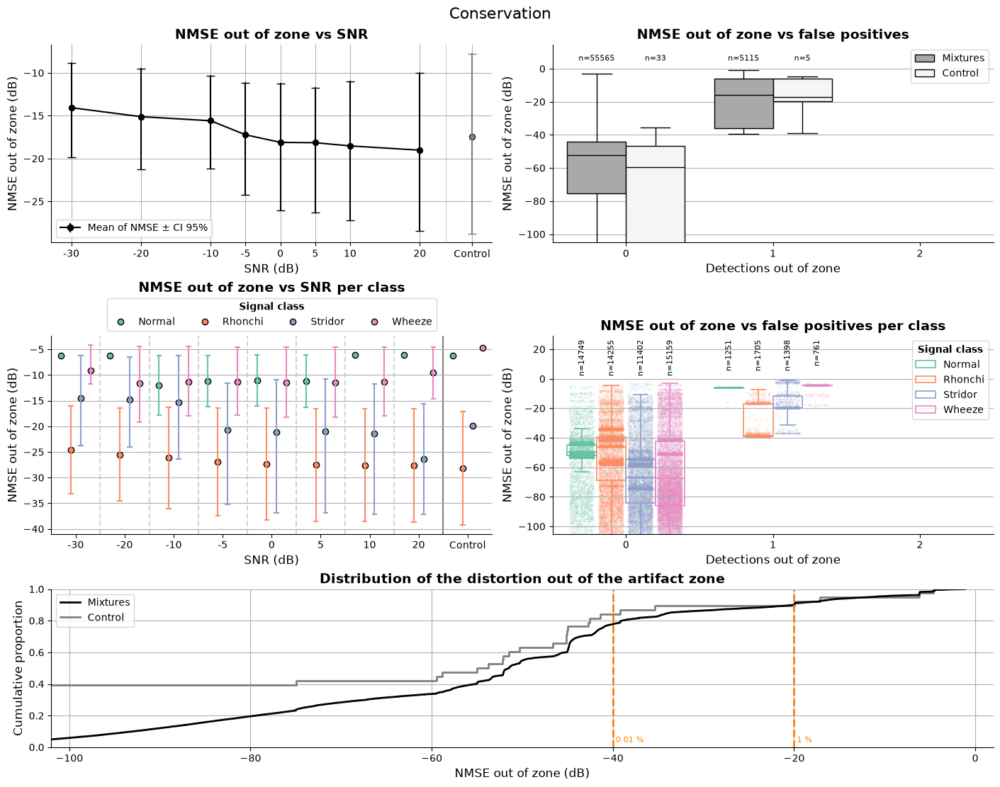

In [120]:
def plot_conservation(results_df):

    # ============================================================================ constantes de estilo
    CAP = 3                                                             # n_false: a partir de aquí se agrupa en "≥ CAP"
    NMSE_FLOOR = -100                                                   # dB: por debajo se considera "sin cambios"
    SOURCES = ["Mixtures", "Control"]
    C_MIX, C_CTRL = "black", "gray"                                     # curvas de A y E
    PAL_BOX = {"Mixtures": "darkgray", "Control": "whitesmoke"}         # cajas de B


    # ============================================================================ datos
    df = results_df.assign(snr_db=pd.to_numeric(results_df["snr_db"], errors="coerce"),    # copia: results_df no se modifica; controles -> NaN
                           source=np.where(results_df["art_id"] == "Control", "Control", "Mixtures"))

    # A y C: casos con detecciones fuera de la zona y NMSE finito
    acted = df[(df["n_false"] > 0) & np.isfinite(df["nmse_out_zone_db"])]
    is_ctrl = acted["source"] == "Control"

    # A: una fila por señal limpia y SNR (media sobre artefactos y posiciones); el control ya es una por señal
    nm_mix = (acted[~is_ctrl].groupby(["clean_id", "snr_db"], as_index=False)["nmse_out_zone_db"].mean()
            .assign(is_control=False))
    nm_ctrl = acted.loc[is_ctrl, ["clean_id", "nmse_out_zone_db"]].assign(is_control=True)
    df_nm = pd.concat([nm_mix, nm_ctrl], ignore_index=True)

    lv = np.sort(nm_mix["snr_db"].unique())                             # niveles de SNR
    step = np.min(np.diff(lv)) if len(lv) > 1 else 5
    x_ctrl = lv.max() + 1.5 * step                                      # posición del control en el eje x
    df_nm["x"] = np.where(df_nm["is_control"], x_ctrl, df_nm["snr_db"])

    # C: mezclas, una fila por señal limpia, clase y SNR; control, una por señal limpia
    lab_mix = (acted[~is_ctrl].groupby(["clean_id", "label", "snr_db"], as_index=False)["nmse_out_zone_db"].mean()
            .assign(snr_cat=lambda d: d["snr_db"].map(lambda v: f"{v:g}")))
    lab_ctrl = acted.loc[is_ctrl, ["clean_id", "label", "nmse_out_zone_db"]].assign(snr_cat="Control")
    df_lab = pd.concat([lab_mix, lab_ctrl], ignore_index=True)
    cat_order = [f"{v:g}" for v in lv] + ["Control"]

    # B y D: todos los casos con NMSE finito, agrupados por número de detecciones fuera de la zona
    nm_all = df[np.isfinite(df["nmse_out_zone_db"])].astype({"n_false": int})
    max_n = nm_all["n_false"].max()
    last = max(2, min(max_n, CAP))                                      # mostrar al menos hasta 2
    order_n = [str(k) for k in range(last)] + [f"≥ {CAP}" if max_n >= CAP else str(last)]
    nm_all["n_cat"] = np.where(nm_all["n_false"] >= last, order_n[-1], nm_all["n_false"].astype(str))
    nm_lab = nm_all[nm_all["source"] == "Mixtures"]                     # D: solo mezclas

    # E: NMSE = -inf (sin cambios) -> NMSE_FLOOR
    cdf = df.assign(nmse_plot=df["nmse_out_zone_db"].replace(-np.inf, NMSE_FLOOR))

    # C y D: colores por clase de la señal limpia
    label_order = sorted(nm_all["label"].unique())
    lab_colors = dict(zip(label_order, sns.color_palette("Set2", len(label_order))))


    # ============================================================================ figura
    fig = plt.figure(figsize=(14, 11), layout="constrained")
    gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.8])

    ax_nmse = fig.add_subplot(gs[0, 0])                   # A: NMSE fuera de la zona vs SNR (+ control)
    ax_nfp  = fig.add_subplot(gs[0, 1])                   # B: NMSE fuera de la zona según n_false
    ax_lab  = fig.add_subplot(gs[1, 0])                   # C: NMSE fuera de la zona vs SNR, por clase
    ax_cls  = fig.add_subplot(gs[1, 1])                   # D: NMSE fuera de la zona según n_false, por clase
    ax_cdf  = fig.add_subplot(gs[2, :])                   # E: distribución acumulada del NMSE fuera de la zona
    
    fig.suptitle("Conservation", fontsize=16)

    # ---------------------------------------------------------------- A: NMSE fuera de la zona vs SNR (+ control)
    sns.lineplot(data=df_nm, x="x", y="nmse_out_zone_db", hue="is_control", palette={False: C_MIX, True: C_CTRL},
                legend=False, errorbar=("ci", 95), err_style="bars", err_kws={"capsize": 4},
                marker="o", markeredgecolor="black", linewidth=1.5, ax=ax_nmse)
    ax_nmse.axvline((lv.max() + x_ctrl) / 2, color="lightgray", lw=1, zorder=0)    # separa el control de los niveles de SNR

    # Entrada de la leyenda (lineplot con barras de error no la genera)
    ax_nmse.errorbar(x=[np.nan], y=[np.nan], yerr=[np.nan], color=C_MIX, linewidth=1.5, marker="o", markeredgecolor="black",
                     label=r"Mean of NMSE $\pm$ CI 95%")

    ax_nmse.set_xticks(list(lv) + [x_ctrl], labels=[f"{v:g}" for v in lv] + ["Control"])
    ax_nmse.set_xlabel("SNR (dB)", fontsize=12)
    ax_nmse.set_ylabel("NMSE out of zone (dB)", fontsize=12)
    ax_nmse.set_title("NMSE out of zone vs SNR", fontsize=14, fontweight="bold")
    ax_nmse.legend(fontsize=10)
    ax_nmse.grid()


    # ---------------------------------------------------------------- B: NMSE fuera de la zona según n_false
    sns.boxplot(data=nm_all, x="n_cat", y="nmse_out_zone_db", order=order_n, hue="source", hue_order=SOURCES,
                palette=PAL_BOX, dodge=True, width=0.8, linecolor="black", linewidth=1,
                showfliers=False, ax=ax_nfp)

    # Número de casos arriba de cada caja (dodge con width=0.8 y dos grupos -> desplazamientos ±0.2)
    counts = nm_all.groupby(["n_cat", "source"]).size()
    for i, cat in enumerate(order_n):
        for src, dx in zip(SOURCES, (-0.2, 0.2)):
            if (cat, src) in counts.index:
                ax_nfp.text(i + dx, 0.95, f"n={counts[(cat, src)]}", transform=ax_nfp.get_xaxis_transform(),
                            ha="center", va="top", fontsize=8)

    ax_nfp.set_ylim(bottom=NMSE_FLOOR - 5)
    ax_nfp.set_xlabel("Detections out of zone", fontsize=12)
    ax_nfp.set_ylabel("NMSE out of zone (dB)", fontsize=12)
    ax_nfp.set_title("NMSE out of zone vs false positives", fontsize=14, fontweight="bold")
    ax_nfp.legend(fontsize=10)
    ax_nfp.grid(axis="y")


    # ---------------------------------------------------------------- C: NMSE fuera de la zona vs SNR, por clase
    sns.pointplot(data=df_lab, x="snr_cat", y="nmse_out_zone_db", order=cat_order, hue="label", hue_order=label_order,
                palette=lab_colors, dodge=0.6, linestyle="none", marker="o", markersize=6, markeredgecolor="black", markeredgewidth=1,
                errorbar=("ci", 95), capsize=0.08, err_kws={"linewidth": 1.5}, ax=ax_lab)

    # Separación entre niveles de SNR (discontinua) y entre el último SNR y el control (continua)
    for k in range(len(cat_order) - 1):
        is_ctrl_sep = k == len(lv) - 1
        ax_lab.axvline(k + 0.5, color="gray" if is_ctrl_sep else "lightgray",
                    lw=1.5, ls="-" if is_ctrl_sep else "--", zorder=0)

    ax_lab.set_xlabel("SNR (dB)", fontsize=12)
    ax_lab.set_ylabel("NMSE out of zone (dB)", fontsize=12)
    ax_lab.set_title("NMSE out of zone vs SNR per class", fontsize=14, fontweight="bold", pad=45)    # hueco para la leyenda
    ax_lab.legend(title="Signal class", title_fontproperties=dict(weight="bold"), ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0))
    ax_lab.grid(axis="y")


    # ---------------------------------------------------------------- D: NMSE fuera de la zona según n_false, por clase
    # Puntos (debajo) y cajas sin relleno (encima)
    sns.stripplot(data=nm_lab, x="n_cat", y="nmse_out_zone_db", order=order_n, hue="label", hue_order=label_order,
                palette=lab_colors, dodge=True, jitter=0.33, size=2, alpha=0.1, legend=False,
                zorder=1, ax=ax_cls)
    sns.boxplot(data=nm_lab, x="n_cat", y="nmse_out_zone_db", order=order_n, hue="label", hue_order=label_order,
                palette=lab_colors, dodge=True, width=0.8, fill=False, linecolor="black", linewidth=1.2,
                showfliers=False, zorder=2, ax=ax_cls)

    # Número de mezclas arriba de cada caja (width=0.8 y n clases -> cajas de 0.8/n)
    w = 0.8 / len(label_order)
    offsets = dict(zip(label_order, -0.4 + w/2 + w*np.arange(len(label_order))))
    counts = nm_lab.groupby(["n_cat", "label"]).size()
    for i, cat in enumerate(order_n):
        for lab in label_order:
            if (cat, lab) in counts.index:
                ax_cls.text(i + offsets[lab], 0.98, f"n={counts[(cat, lab)]}", transform=ax_cls.get_xaxis_transform(),
                            ha="center", va="top", fontsize=8, rotation=90)

    ax_cls.set_ylim(NMSE_FLOOR - 5, nm_lab["nmse_out_zone_db"].max() + 30)    # hueco arriba para los números
    ax_cls.set_xlabel("Detections out of zone", fontsize=12)
    ax_cls.set_ylabel("NMSE out of zone (dB)", fontsize=12)
    ax_cls.set_title("NMSE out of zone vs false positives per class", fontsize=14, fontweight="bold")
    ax_cls.legend(title="Signal class", title_fontproperties=dict(weight="bold"))
    ax_cls.grid(axis="y")


    # ---------------------------------------------------------------- E: distribución acumulada del NMSE fuera de la zona
    sns.ecdfplot(data=cdf, x="nmse_plot", hue="source", hue_order=SOURCES, legend=False,
                palette={"Mixtures": C_MIX, "Control": C_CTRL}, lw=2, ax=ax_cdf)

    # Referencias: error del 1 % y del 0,01 % de la potencia de la señal
    for thr, txt in ((-20, "1 %"), (-40, "0.01 %")):
        ax_cdf.axvline(thr, color="tab:orange", ls="--", lw=2)
        ax_cdf.text(thr, 0.02, f" {txt}", color="tab:orange", fontsize=8, va="bottom")

    # Entradas de la leyenda
    for src, color in zip(SOURCES, (C_MIX, C_CTRL)):
        ax_cdf.plot([], [], lw=2, color=color, label=src)

    ax_cdf.set_xlim(NMSE_FLOOR - 2, 2)
    ax_cdf.set_xlabel("NMSE out of zone (dB)", fontsize=12)
    ax_cdf.set_ylabel("Cumulative proportion", fontsize=12)
    ax_cdf.set_title("Distribution of the distortion out of the artifact zone", fontsize=14, fontweight="bold")
    ax_cdf.legend(fontsize=10)
    ax_cdf.grid()


    sns.despine(fig)
    plt.show()

plot_conservation(results_df)

In [151]:
from matplotlib import colormaps
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.cbook import boxplot_stats
from matplotlib.colors import to_hex
from matplotlib.figure import Figure
from matplotlib.lines import Line2D

from src.summary_plots import FONT, MPL_TICKFORMAT, mpl_nticks, mpl_range, mpl_text_size, rgba, rounded_rect


def _conservation_geometry(fig_w, fig_h, dpi, spec):
    """
    Geometría de la figura de plot_conservation tal como la calcula matplotlib (layout="constrained"): crea la misma
    figura SIN datos (títulos, etiquetas, límites, ticks, leyendas) y devuelve las cajas (px desde la esquina superior
    izquierda de la imagen recortada como bbox_inches="tight") de los ejes, textos y leyendas.
    spec: {"A"|"B"|"C"|"D"|"E": dict(title, xlabel, ylabel, xlim, ylim, xticks, title_pad, legend, legend_title,
    legend_kw), "suptitle": str}
    """
    fig = Figure(figsize=(fig_w, fig_h), dpi=dpi, layout="constrained")
    canvas = FigureCanvasAgg(fig)
    gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.8])
    axs = {"A": fig.add_subplot(gs[0, 0]), "B": fig.add_subplot(gs[0, 1]), "C": fig.add_subplot(gs[1, 0]),
           "D": fig.add_subplot(gs[1, 1]), "E": fig.add_subplot(gs[2, :])}

    for k, ax in axs.items():
        s = spec[k]
        ax.set_title(s["title"], fontsize=14, fontweight="bold", pad=s.get("title_pad"))
        ax.set_xlabel(s["xlabel"], fontsize=12)
        ax.set_ylabel(s["ylabel"], fontsize=12)
        if s.get("xticks"):
            ax.set_xticks(*s["xticks"])
        ax.set_xlim(*s["xlim"])
        ax.set_ylim(*s["ylim"])
        ax.legend([Line2D([], [], marker="o") for _ in s["legend"]], s["legend"], fontsize=10,
                  title=s.get("legend_title"), title_fontproperties=dict(weight="bold"), **s["legend_kw"])
    fig.suptitle(spec["suptitle"], fontsize=16)

    canvas.draw()
    r = canvas.get_renderer()
    tight = fig.get_tightbbox(r)
    pad = 0.1*dpi                                                                # pad_inches de bbox_inches="tight"
    x0, y_top = tight.x0*dpi - pad, tight.y1*dpi + pad

    def box(artist):
        bb = artist.get_window_extent(r)
        return dict(x0=bb.x0 - x0, x1=bb.x1 - x0, top=y_top - bb.y1, bottom=y_top - bb.y0)

    out = dict(size=(int(tight.width*dpi + 2*pad), int(tight.height*dpi + 2*pad)), suptitle=box(fig._suptitle))
    for k, ax in axs.items():
        leg = ax.get_legend()
        out[k] = dict(ax=box(ax), xlabel=box(ax.xaxis.label), ylabel=box(ax.yaxis.label), title=box(ax.title),
                      legend=box(leg), legend_texts=[box(t) for t in leg.get_texts()],
                      legend_title=box(leg.get_title()))
    return out


def plot_conservation(results_df, width: int = None, dpi: float = 100) -> go.Figure:
    """
    Versión interactiva (plotly) de plot_conservation (matplotlib/seaborn): mismo diseño (layout="constrained",
    figsize 14 x 11 in, suptitle), tamaños, fuentes, colores y posiciones. La figura se recorta como el backend inline
    (bbox_inches="tight"), así que su tamaño coincide con el de la imagen de matplotlib.
    - A: NMSE fuera de la zona vs SNR (media ± IC 95 % sobre las señales limpias) y control
    - B: cajas del NMSE fuera de la zona según el número de detecciones fuera de la zona (mezclas y control), con el
      número de casos encima de cada caja
    - C: NMSE fuera de la zona vs SNR por clase de la señal limpia (media ± IC 95 %)
    - D: puntos (con jitter) y cajas del NMSE fuera de la zona según n_false, por clase (solo mezclas)
    - E: distribución acumulada del NMSE fuera de la zona (NMSE = -inf -> NMSE_FLOOR) con referencias del 1 % y 0,01 %
    Interactividad: hover con los valores (media, IC 95 % y n; estadísticos de cada caja; en D, señal limpia,
    artefacto y SNR de cada mezcla; en E, la proporción acumulada); clic en la leyenda para ocultar/mostrar cada
    categoría (líneas, barras de error, cajas y puntos a la vez); zoom en cada panel.
    - width: ancho de la figura (px). Solo cambia el ancho de los ejes (fuentes y márgenes no cambian). None -> como
      matplotlib
    - dpi: px por pulgada (matplotlib inline: 100). Todos los tamaños (fuentes, líneas, márgenes) escalan con él
    Las posiciones de los ejes y textos se toman del constrained layout de matplotlib aplicado a la misma figura sin
    datos (_conservation_geometry). Limitaciones: las leyendas se colocan donde las pone loc="best" con estos datos
    (A: abajo a la izquierda; B y D: arriba a la derecha; E: arriba a la izquierda); los símbolos de la leyenda de
    plotly no son los de matplotlib (marcadores y líneas a 5-35 px en vez del segmento de 2 em); los textos n= de B y
    D no se ocultan con sus cajas; los puntos de D (WebGL) quedan encima de la rejilla; el ancho de los caps de C se
    calcula para el zoom inicial (no cambia al hacer zoom); el jitter de D y los IC por bootstrap usan una semilla
    fija (seaborn no), así que pueden diferir ligeramente de la versión matplotlib.
    """

    # ============================================================================ constantes de estilo
    CAP = 3                                                             # n_false: a partir de aquí se agrupa en "≥ CAP"
    NMSE_FLOOR = -100                                                   # dB: por debajo se considera "sin cambios"
    SOURCES = ["Mixtures", "Control"]
    C_MIX, C_CTRL = "#000000", to_hex("gray")                           # curvas de A y E
    PAL_BOX = {"Mixtures": to_hex("darkgray"), "Control": to_hex("whitesmoke")}   # cajas de B
    C_ORANGE, C_LIGHTGRAY = to_hex("tab:orange"), to_hex("lightgray")
    LBL_A = "Mean of NMSE ± CI 95%"
    N_BOOT = 1000


    # ============================================================================ datos (como la versión matplotlib)
    df = results_df.assign(snr_db=pd.to_numeric(results_df["snr_db"], errors="coerce"),    # copia: results_df no se modifica; controles -> NaN
                           source=np.where(results_df["art_id"] == "Control", "Control", "Mixtures"))

    # A y C: casos con detecciones fuera de la zona y NMSE finito
    acted = df[(df["n_false"] > 0) & np.isfinite(df["nmse_out_zone_db"])]
    is_ctrl = acted["source"] == "Control"

    # A: una fila por señal limpia y SNR (media sobre artefactos y posiciones); el control ya es una por señal
    nm_mix = (acted[~is_ctrl].groupby(["clean_id", "snr_db"], as_index=False)["nmse_out_zone_db"].mean()
              .assign(is_control=False))
    nm_ctrl = acted.loc[is_ctrl, ["clean_id", "nmse_out_zone_db"]].assign(is_control=True)
    df_nm = pd.concat([nm_mix, nm_ctrl], ignore_index=True)

    lv = np.sort(nm_mix["snr_db"].unique())                             # niveles de SNR
    step = np.min(np.diff(lv)) if len(lv) > 1 else 5
    x_ctrl = lv.max() + 1.5 * step                                      # posición del control en el eje x
    df_nm["x"] = np.where(df_nm["is_control"], x_ctrl, df_nm["snr_db"])

    # C: mezclas, una fila por señal limpia, clase y SNR; control, una por señal limpia
    lab_mix = (acted[~is_ctrl].groupby(["clean_id", "label", "snr_db"], as_index=False)["nmse_out_zone_db"].mean()
               .assign(snr_cat=lambda d: d["snr_db"].map(lambda v: f"{v:g}")))
    lab_ctrl = acted.loc[is_ctrl, ["clean_id", "label", "nmse_out_zone_db"]].assign(snr_cat="Control")
    df_lab = pd.concat([lab_mix, lab_ctrl], ignore_index=True)
    cat_order = [f"{v:g}" for v in lv] + ["Control"]

    # B y D: todos los casos con NMSE finito, agrupados por número de detecciones fuera de la zona
    nm_all = df[np.isfinite(df["nmse_out_zone_db"])].astype({"n_false": int})
    max_n = nm_all["n_false"].max()
    last = max(2, min(max_n, CAP))                                      # mostrar al menos hasta 2
    order_n = [str(k) for k in range(last)] + [f"≥ {CAP}" if max_n >= CAP else str(last)]
    nm_all["n_cat"] = np.where(nm_all["n_false"] >= last, order_n[-1], nm_all["n_false"].astype(str))
    nm_lab = nm_all[nm_all["source"] == "Mixtures"].copy()              # D: solo mezclas

    # C y D: colores por clase de la señal limpia
    label_order = sorted(nm_all["label"].unique())
    lab_colors = dict(zip(label_order, [to_hex(c) for c in colormaps["Set2"].colors]))   # = sns.color_palette("Set2")


    # ---------------------------------------------------------------- media e intervalos (como seaborn)
    rng_ci = np.random.default_rng(1)

    def mean_ci(v):
        """Media e IC 95 % por bootstrap (errorbar=("ci", 95), n_boot=1000 de seaborn; sin IC con una observación)"""
        v = np.asarray(v, float)
        v = v[~np.isnan(v)]
        if len(v) < 2:
            return (v.mean() if len(v) else np.nan, np.nan, np.nan, len(v))
        boots = v[rng_ci.integers(0, len(v), (N_BOOT, len(v)))].mean(1)
        return (v.mean(), *np.percentile(boots, [2.5, 97.5]), len(v))

    def stat_table(d, by, col):
        """Media, límite inferior y superior del IC 95 % y n de col por grupo (índice: by)"""
        gb = d.groupby(by)
        index = (pd.Index(list(gb.groups.keys())) if isinstance(by, str)
                 else pd.MultiIndex.from_tuples(list(gb.groups.keys())))
        return pd.DataFrame([mean_ci(gr[col]) for _, gr in gb], index=index, columns=["mean", "lo", "hi", "n"])

    def box_stats(v):
        """Estadísticos de una caja (sns.boxplot: matplotlib boxplot_stats, whis=1.5)"""
        st = boxplot_stats(np.asarray(v, float), whis=1.5)[0]
        return dict(q1=st["q1"], med=st["med"], q3=st["q3"], lo=st["whislo"], hi=st["whishi"], n=len(v))

    # A: mezclas (un punto por SNR) y control
    nm_t = stat_table(df_nm, ["is_control", "x"], "nmse_out_zone_db")
    nm_mix_t, nm_ctrl_t = nm_t.loc[False], nm_t.loc[True]

    # B: cajas por categoría de n_false y origen (dodge con width=0.8 y dos grupos -> cajas de 0.4 en ±0.2)
    boxes_b = [dict(cat=cat, group=src, pos=i + dx, w=0.4, **box_stats(sub["nmse_out_zone_db"]))
               for i, cat in enumerate(order_n) for src, dx in zip(SOURCES, (-0.2, 0.2))
               if len(sub := nm_all[(nm_all["n_cat"] == cat) & (nm_all["source"] == src)])]

    # C: media e IC por clase y nivel (pointplot con dodge=0.6 -> desplazamientos de -0.3 a 0.3)
    lab_t = stat_table(df_lab, ["label", "snr_cat"], "nmse_out_zone_db")
    dodge_c = dict(zip(label_order, np.linspace(-0.3, 0.3, len(label_order)) if len(label_order) > 1 else [0]))

    # D: cajas de 0.8/n por clase; puntos con jitter (jitter=0.33 x ancho de la categoría / n clases)
    w_d = 0.8 / len(label_order)
    offsets_d = dict(zip(label_order, -0.4 + w_d/2 + w_d*np.arange(len(label_order))))
    boxes_d = [dict(cat=cat, group=lab, pos=i + offsets_d[lab], w=w_d, **box_stats(sub["nmse_out_zone_db"]))
               for i, cat in enumerate(order_n) for lab in label_order
               if len(sub := nm_lab[(nm_lab["n_cat"] == cat) & (nm_lab["label"] == lab)])]
    jlim = 0.33 / len(label_order)
    cat_pos = {cat: i for i, cat in enumerate(order_n)}
    nm_lab["x_jitter"] = (nm_lab["n_cat"].map(cat_pos) + nm_lab["label"].map(offsets_d)
                          + np.random.default_rng(0).uniform(-jlim, jlim, len(nm_lab)))

    # E: distribución acumulada (escalones) por origen; NMSE = -inf (sin cambios) -> NMSE_FLOOR
    ecdfs = {}
    for src in SOURCES:
        v = df.loc[df["source"] == src, "nmse_out_zone_db"].replace(-np.inf, NMSE_FLOOR).dropna().to_numpy()
        xs, cnt = np.unique(v, return_counts=True)
        ecdfs[src] = (np.r_[xs[0], xs], np.r_[0, np.cumsum(cnt) / len(v)])


    # ============================================================================ geometría (como matplotlib)
    PT = dpi / 72                                                                  # px por punto
    pt = lambda v: v * PT
    em = pt(10)                                                                    # fuente de ticks y leyendas (px)
    dash = lambda lw: f"{pt(3.7*lw):.1f}px,{pt(1.6*lw):.1f}px"                    # línea "--" de ancho lw (pt)
    vals = lambda t: t[["mean", "lo", "hi"]].to_numpy()

    # Límites (autoscale de matplotlib: datos + 5 %; ejes categóricos: -0.5 a n - 0.5)
    x_range_a = mpl_range(lv, [x_ctrl])
    y_range_a = mpl_range(vals(nm_t))
    x_range_n = [-0.5, len(order_n) - 0.5]
    y_range_b = [NMSE_FLOOR - 5, mpl_range([b["lo"] for b in boxes_b], [b["hi"] for b in boxes_b])[1]]
    x_range_c = [-0.5, len(cat_order) - 0.5]
    y_range_c = mpl_range(vals(lab_t))
    y_range_d = [NMSE_FLOOR - 5, nm_lab["nmse_out_zone_db"].max() + 30]
    x_range_e, y_range_e = [NMSE_FLOOR - 2, 2], [0, 1]

    xticks_a = (list(lv) + [x_ctrl], [f"{v:g}" for v in lv] + ["Control"])
    xticks_n = (list(range(len(order_n))), order_n)
    xticks_c = (list(range(len(cat_order))), cat_order)
    spec = dict(
        suptitle="Conservation",
        A=dict(title="NMSE out of zone vs SNR", xlabel="SNR (dB)", ylabel="NMSE out of zone (dB)", xlim=x_range_a,
               ylim=y_range_a, xticks=xticks_a, legend=[r"Mean of NMSE $\pm$ CI 95%"], legend_kw=dict(loc="lower left")),
        B=dict(title="NMSE out of zone vs false positives", xlabel="Detections out of zone",
               ylabel="NMSE out of zone (dB)", xlim=x_range_n, ylim=y_range_b, xticks=xticks_n, legend=SOURCES,
               legend_kw=dict(loc="upper right")),
        C=dict(title="NMSE out of zone vs SNR per class", xlabel="SNR (dB)", ylabel="NMSE out of zone (dB)",
               xlim=x_range_c, ylim=y_range_c, xticks=xticks_c, title_pad=45, legend=label_order,
               legend_title="Signal class", legend_kw=dict(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0))),
        D=dict(title="NMSE out of zone vs false positives per class", xlabel="Detections out of zone",
               ylabel="NMSE out of zone (dB)", xlim=x_range_n, ylim=y_range_d, xticks=xticks_n, legend=label_order,
               legend_title="Signal class", legend_kw=dict(loc="upper right")),
        E=dict(title="Distribution of the distortion out of the artifact zone", xlabel="NMSE out of zone (dB)",
               ylabel="Cumulative proportion", xlim=x_range_e, ylim=y_range_e, legend=SOURCES,
               legend_kw=dict(loc="upper left")),
    )

    fig_w, fig_h = 14, 11
    geo = _conservation_geometry(fig_w, fig_h, dpi, spec)
    for _ in range(6 if width else 0):                                             # ancho pedido: solo cambian los ejes
        if geo["size"][0] == width:
            break
        fig_w += (width - geo["size"][0]) / dpi
        geo = _conservation_geometry(fig_w, fig_h, dpi, spec)
    W, H = geo["size"]
    X = lambda v: v / W                                                            # px -> papel
    Y = lambda v: 1 - v / H
    dom_x = lambda b: [X(b["x0"]), X(b["x1"])]
    dom_y = lambda b: [Y(b["bottom"]), Y(b["top"])]
    ax_len_pt = lambda b, k: (b["x1"] - b["x0"] if k == "x" else b["bottom"] - b["top"]) / PT
    g = {k: geo[k]["ax"] for k in "ABCDE"}

    def nticks(axis_range, b, k):
        """
        nticks de plotly que da los ticks de matplotlib (mpl_nticks). plotly redondea rango/nticks al paso 1-2-5
        SIGUIENTE cuando cae justo en uno (30/6 = 5 -> 10), así que en ese caso se pide un tick más
        """
        n = mpl_nticks(axis_range, ax_len_pt(b, k), 3 if k == "x" else 2)
        rough = (axis_range[1] - axis_range[0]) / n
        return n + 1 if np.isclose(rough / 10**np.floor(np.log10(rough)), [1, 2, 5]).any() else n

    axis_style = dict(showline=True, mirror=False, linecolor="black", linewidth=pt(0.8), ticks="outside",
                      ticklen=pt(3.5), tickwidth=pt(0.8), tickcolor="black", tickfont=dict(size=em),
                      showgrid=True, gridcolor="#b0b0b0", gridwidth=pt(0.8), zeroline=False, automargin=False,
                      tickformatstops=MPL_TICKFORMAT, exponentformat="none")      # sns.despine: sin ejes arriba/derecha
    x_style = dict(**axis_style, ticklabelstandoff=round(-2.2 * PT))
    x_cat = {**x_style, "showgrid": False}                                         # ejes categóricos: sin rejilla en x

    def y_axis(k, i, axis_range):
        return dict(domain=dom_y(g[k]), anchor=f"x{i}", range=axis_range, nticks=nticks(axis_range, g[k], "y"),
                    **axis_style)

    layout = dict(
        # A (el control, a la derecha del último SNR)
        xaxis=dict(domain=dom_x(g["A"]), anchor="y", range=x_range_a, tickvals=xticks_a[0], ticktext=xticks_a[1],
                   **x_style),
        yaxis=y_axis("A", "", y_range_a),
        # B, C y D: un nivel de n_false / SNR por posición
        xaxis2=dict(domain=dom_x(g["B"]), anchor="y2", range=x_range_n, tickvals=xticks_n[0], ticktext=xticks_n[1],
                    **x_cat),
        yaxis2=y_axis("B", 2, y_range_b),
        xaxis3=dict(domain=dom_x(g["C"]), anchor="y3", range=x_range_c, tickvals=xticks_c[0], ticktext=xticks_c[1],
                    **x_cat),
        yaxis3=y_axis("C", 3, y_range_c),
        xaxis4=dict(domain=dom_x(g["D"]), anchor="y4", range=x_range_n, tickvals=xticks_n[0], ticktext=xticks_n[1],
                    **x_cat),
        yaxis4=y_axis("D", 4, y_range_d),
        # E
        xaxis5=dict(domain=dom_x(g["E"]), anchor="y5", range=x_range_e, nticks=nticks(x_range_e, g["E"], "x"),
                    **x_style),
        yaxis5=y_axis("E", 5, y_range_e),
    )

    # Leyendas: una leyenda de plotly por elemento, en la posición del texto de matplotlib (el texto de un elemento
    # de plotly empieza 40 px a la derecha de la x de la leyenda), y un marco común con esquinas redondeadas. Los
    # títulos de C y D son anotaciones en negrita
    legends, frames, n_leg = {}, [], 0
    annotations = []

    def legend_items(key, names, title=None):
        nonlocal n_leg
        ids = {}
        for name, t in zip(names, geo[key]["legend_texts"]):
            n_leg += 1
            lid = "legend" if n_leg == 1 else f"legend{n_leg}"
            legends[lid] = dict(x=X(t["x0"] - 40), y=Y((t["top"] + t["bottom"]) / 2 - 0.1 * em), xanchor="left",
                                yanchor="middle", orientation="h", bgcolor="rgba(0, 0, 0, 0)", borderwidth=0,
                                font=dict(size=em), groupclick="togglegroup", itemwidth=30)
            ids[name] = lid
        if title:
            t = geo[key]["legend_title"]
            annotations.append(dict(text=f"<b>{title}</b>", x=X((t["x0"] + t["x1"]) / 2),
                                    y=Y((t["top"] + t["bottom"]) / 2 - 0.1*em), xref="paper", yref="paper",
                                    xanchor="center", yanchor="middle", showarrow=False, font=dict(size=em)))
        b = geo[key]["legend"]
        frames.append(dict(type="path", xref="paper", yref="paper", layer="above", fillcolor="rgba(255, 255, 255, 0.8)",
                           line=dict(color="#cccccc", width=pt(1)),
                           path=rounded_rect(X(b["x0"]), X(b["x1"]), Y(b["bottom"]), Y(b["top"]), 0.2 * em, W, H)))
        return ids

    leg_A = legend_items("A", [LBL_A])
    leg_B = legend_items("B", SOURCES)
    leg_C = legend_items("C", label_order, title="Signal class")
    leg_D = legend_items("D", label_order, title="Signal class")
    leg_E = legend_items("E", SOURCES)

    fig = go.Figure()
    shapes = []

    def none_join(segments):
        """Segmentos [(x, y), ...] -> x, y de una sola traza con None entre segmentos"""
        xs, ys = [], []
        for sx, sy in segments:
            xs += [*sx, None]
            ys += [*sy, None]
        return xs, ys

    def err_traces(tab, x, color, lw, cap_px, cap_lw=None, **kw):
        """
        Barras de error del IC (encima de los marcadores, como seaborn) con caps de cap_px px de semiancho. Con
        cap_lw (caps de otro grosor, como err_style="bars" de lineplot) se dibujan dos trazas: caps y barras
        """
        lo, hi = (tab["mean"] - tab["lo"]).to_numpy(), (tab["hi"] - tab["mean"]).to_numpy()
        ok = ~np.isnan(lo)
        traces = []
        for w, t_lw in ([(cap_px, cap_lw), (0, lw)] if cap_lw else [(cap_px, lw)]):
            traces.append(go.Scatter(x=np.asarray(x)[ok], y=tab["mean"].to_numpy()[ok], mode="markers",
                                     marker=dict(size=0, opacity=0), hoverinfo="skip", showlegend=False,
                                     error_y=dict(type="data", symmetric=False, array=hi[ok], arrayminus=lo[ok],
                                                  color=color, thickness=pt(t_lw), width=w), **kw))
        return traces

    def vline(x, axis, color, lw, dashed=False, layer="below"):
        """Línea vertical de todo el alto del panel (axvline)"""
        return dict(type="line", xref=f"x{axis}", yref=f"y{axis} domain", x0=x, x1=x, y0=0, y1=1, layer=layer,
                    line=dict(color=color, width=pt(lw), dash=dash(lw) if dashed else None))

    def box_hover(b, what):
        return (f"{b['group']}<br>{what}<br>n = {b['n']}<br>Median: {b['med']:.2f} dB<br>"
                f"Q1 / Q3: {b['q1']:.2f} / {b['q3']:.2f} dB<br>Whiskers: {b['lo']:.2f} / {b['hi']:.2f} dB")

    def box_segments(b):
        """Bigotes, caps (la mitad del ancho de la caja) y mediana de una caja"""
        p, hw, cw = b["pos"], b["w"] / 2, b["w"] / 4
        return [([p, p], [b["q1"], b["lo"]]), ([p, p], [b["q3"], b["hi"]]), ([p - cw, p + cw], [b["lo"]] * 2),
                ([p - cw, p + cw], [b["hi"]] * 2), ([p - hw, p + hw], [b["med"]] * 2)]

    def box_outline(b):
        p, hw = b["pos"], b["w"] / 2
        return [p - hw, p + hw, p + hw, p - hw, p - hw], [b["q1"], b["q1"], b["q3"], b["q3"], b["q1"]]

    def legend_box(name, fill, edge, lw, legend, group, axis):
        """Traza vacía cuyo símbolo en la leyenda es un rectángulo con borde (como el de las cajas de seaborn)"""
        return go.Bar(x=[None], y=[None], name=name, marker=dict(color=fill, line=dict(color=edge, width=pt(lw))),
                      legend=legend, legendgroup=group, xaxis=f"x{axis}", yaxis=f"y{axis}")

    def count_labels(boxes, axis, y, rotate=False):
        """
        Número de casos arriba de cada caja (texto en coordenadas de los ejes, va="top"). La caja de la anotación de
        plotly es más alta que la del texto de matplotlib: se sube 0,36 em (0,27 em el texto girado)
        """
        return [dict(text=f"n={b['n']}", x=b["pos"], y=y, xref=f"x{axis}", yref=f"y{axis} domain", xanchor="center",
                     yanchor="top", yshift=(0.27 if rotate else 0.36) * pt(8), showarrow=False, font=dict(size=pt(8)),
                     textangle=-90 if rotate else 0, borderpad=0) for b in boxes]

    hover_ci = lambda first: (f"{first}<br>Mean NMSE: %{{y:.2f}} dB<br>CI 95%: (%{{customdata[0]:.2f}}, "
                              "%{customdata[1]:.2f}) dB<br>n = %{customdata[2]} clean signals<extra></extra>")

    # ---------------------------------------------------------------- A: NMSE fuera de la zona vs SNR (+ control)
    shapes.append(vline((lv.max() + x_ctrl) / 2, "", C_LIGHTGRAY, 1))         # separa el control de los niveles de SNR
    for tab, color, name, first in [(nm_mix_t, C_MIX, LBL_A, "Mixtures<br>SNR: %{x:g} dB"),
                                    (nm_ctrl_t, C_CTRL, "Control", "Control")]:
        x = tab.index.to_numpy(float)
        fig.add_trace(go.Scatter(x=x, y=tab["mean"], mode="lines+markers", name=name,
                                 line=dict(color=color, width=pt(1.5)),
                                 marker=dict(size=pt(6), color=color, line=dict(color="#000000", width=pt(0.75))),
                                 customdata=tab[["lo", "hi", "n"]].to_numpy(), hovertemplate=hover_ci(first),
                                 showlegend=name == LBL_A, legend=leg_A[LBL_A], legendgroup="A", xaxis="x", yaxis="y"))
        fig.add_traces(err_traces(tab, x, color, 1.5, pt(4), cap_lw=1, legend=leg_A[LBL_A], legendgroup="A",
                                  xaxis="x", yaxis="y"))

    # ---------------------------------------------------------------- B: NMSE fuera de la zona según n_false
    for b in boxes_b:
        src = b["group"]
        bx, by = box_outline(b)
        fig.add_trace(go.Scatter(x=bx, y=by, mode="lines", fill="toself", fillcolor=PAL_BOX[src],
                                 line=dict(color="#000000", width=pt(1)), name=src, hoveron="fills",
                                 text=box_hover(b, f"Detections out of zone: {b['cat']}"), hoverinfo="text",
                                 showlegend=False, legend=leg_B[src], legendgroup=f"B_{src}", xaxis="x2", yaxis="y2"))
        sx, sy = none_join(box_segments(b))
        fig.add_trace(go.Scatter(x=sx, y=sy, mode="lines", line=dict(color="#000000", width=pt(1)), hoverinfo="skip",
                                 showlegend=False, legend=leg_B[src], legendgroup=f"B_{src}", xaxis="x2", yaxis="y2"))
    for src in SOURCES:                                                 # elementos de la leyenda (rectángulo con borde)
        fig.add_trace(legend_box(src, PAL_BOX[src], "#000000", 1, leg_B[src], f"B_{src}", 2))
    annotations += count_labels(boxes_b, 2, 0.95)

    # ---------------------------------------------------------------- C: NMSE fuera de la zona vs SNR, por clase
    # Separación entre niveles de SNR (discontinua) y entre el último SNR y el control (continua)
    for k in range(len(cat_order) - 1):
        is_ctrl_sep = k == len(lv) - 1
        shapes.append(vline(k + 0.5, 3, to_hex("gray") if is_ctrl_sep else C_LIGHTGRAY, 1.5, dashed=not is_ctrl_sep))

    px_per_x = (g["C"]["x1"] - g["C"]["x0"]) / (x_range_c[1] - x_range_c[0])      # caps de 0.08 (unidades de x)
    for lab in label_order:
        tab = lab_t.loc[lab].reindex([c for c in cat_order if c in lab_t.loc[lab].index])
        x = np.array([cat_order.index(c) for c in tab.index]) + dodge_c[lab]
        snr = [f"{c} dB" if c != "Control" else c for c in tab.index]
        fig.add_trace(go.Scatter(x=x, y=tab["mean"], mode="markers", name=lab,
                                 marker=dict(size=pt(6), color=lab_colors[lab], line=dict(color="#000000", width=pt(1))),
                                 customdata=[[*r, s] for r, s in zip(tab[["lo", "hi", "n"]].to_numpy().tolist(), snr)],
                                 hovertemplate=hover_ci(f"{lab}<br>SNR: %{{customdata[3]}}"),
                                 legend=leg_C[lab], legendgroup=f"C_{lab}", xaxis="x3", yaxis="y3"))
        fig.add_traces(err_traces(tab, x, lab_colors[lab], 1.5, 0.04 * px_per_x, legend=leg_C[lab],
                                  legendgroup=f"C_{lab}", xaxis="x3", yaxis="y3"))

    # ---------------------------------------------------------------- D: NMSE fuera de la zona según n_false, por clase
    # Puntos (debajo) y cajas sin relleno (encima), todo en WebGL para que las cajas queden encima de los puntos
    for lab in label_order:
        d = nm_lab[nm_lab["label"] == lab]
        fig.add_trace(go.Scattergl(
            x=d["x_jitter"], y=d["nmse_out_zone_db"], mode="markers", name=lab, xaxis="x4", yaxis="y4",
            marker=dict(size=pt(2), color=rgba(lab_colors[lab], 0.1), line=dict(width=0)),
            customdata=d[["n_false", "snr_db", "clean_file", "art_id"]].to_numpy(float),
            hovertemplate=(f"{lab}<br>Detections out of zone: %{{customdata[0]:.0f}}<br>NMSE: %{{y:.2f}} dB<br>"
                           "SNR: %{customdata[1]:g} dB<br>Clean signal: %{customdata[2]:.0f}<br>"
                           "Artifact: %{customdata[3]:.0f}<extra></extra>"),
            showlegend=False, legend=leg_D[lab], legendgroup=f"D_{lab}"))
    for b in boxes_d:
        lab = b["group"]
        sx, sy = none_join([box_outline(b), *box_segments(b)])
        fig.add_trace(go.Scattergl(x=sx, y=sy, mode="lines", line=dict(color=lab_colors[lab], width=pt(1.2)),
                                   text=box_hover(b, f"Detections out of zone: {b['cat']}"), hoverinfo="text",
                                   showlegend=False, legend=leg_D[lab], legendgroup=f"D_{lab}", xaxis="x4", yaxis="y4"))
    for lab in label_order:                                             # elementos de la leyenda (caja sin relleno)
        fig.add_trace(legend_box(lab, "rgba(0, 0, 0, 0)", lab_colors[lab], 1.2, leg_D[lab], f"D_{lab}", 4))
    annotations += count_labels(boxes_d, 4, 0.98, rotate=True)

    # ---------------------------------------------------------------- E: distribución acumulada del NMSE fuera de la zona
    for src, color in zip(SOURCES, (C_MIX, C_CTRL)):
        xs, ys = ecdfs[src]
        fig.add_trace(go.Scatter(x=xs, y=ys, mode="lines", line=dict(color=color, width=pt(2), shape="hv"), name=src,
                                 hovertemplate=(f"{src}<br>NMSE out of zone: %{{x:.2f}} dB<br>"
                                                "Cumulative proportion: %{y:.3f}<extra></extra>"),
                                 legend=leg_E[src], legendgroup=f"E_{src}", xaxis="x5", yaxis="y5"))

    # Referencias: error del 1 % y del 0,01 % de la potencia de la señal
    space = mpl_text_size(" ", 8, dpi)[0]
    for thr, txt in ((-20, "1 %"), (-40, "0.01 %")):
        shapes.append(vline(thr, 5, C_ORANGE, 2, dashed=True, layer="above"))
        annotations.append(dict(text=txt, x=thr, y=0.02, xref="x5", yref="y5", xanchor="left", yanchor="bottom",
                                xshift=space, showarrow=False, font=dict(size=pt(8), color=C_ORANGE), borderpad=0))

    # ---------------------------------------------------------------- títulos y etiquetas
    def ann(s, b, size, rotate=False):
        """Texto centrado en la caja b de matplotlib (subido 0,1 em: Arial queda más baja que DejaVu Sans)"""
        cx, cy = (b["x0"] + b["x1"]) / 2, (b["top"] + b["bottom"]) / 2
        if rotate:
            cx -= 0.1 * pt(size)
        else:
            cy -= 0.1 * pt(size)
        return dict(text=s, x=X(cx), y=Y(cy), xref="paper", yref="paper", xanchor="center", yanchor="middle",
                    showarrow=False, font=dict(size=pt(size)), textangle=-90 if rotate else 0)

    annotations.append(ann(spec["suptitle"], geo["suptitle"], 16))
    for k in "ABCDE":
        s = spec[k]
        annotations += [ann(f"<b>{s['title']}</b>", geo[k]["title"], 14), ann(s["xlabel"], geo[k]["xlabel"], 12),
                        ann(s["ylabel"], geo[k]["ylabel"], 12, rotate=True)]

    fig.update_layout(
        **layout, **legends, width=W, height=H, margin=dict(l=0, r=0, t=0, b=0, autoexpand=False),
        annotations=annotations, shapes=shapes + frames, font=dict(family=FONT, size=em, color="black"),
        paper_bgcolor="white", plot_bgcolor="white", hovermode="closest", template="none"
    )
    return fig

plot_conservation(results_df).show()


#### 5.4.4. Amplitude

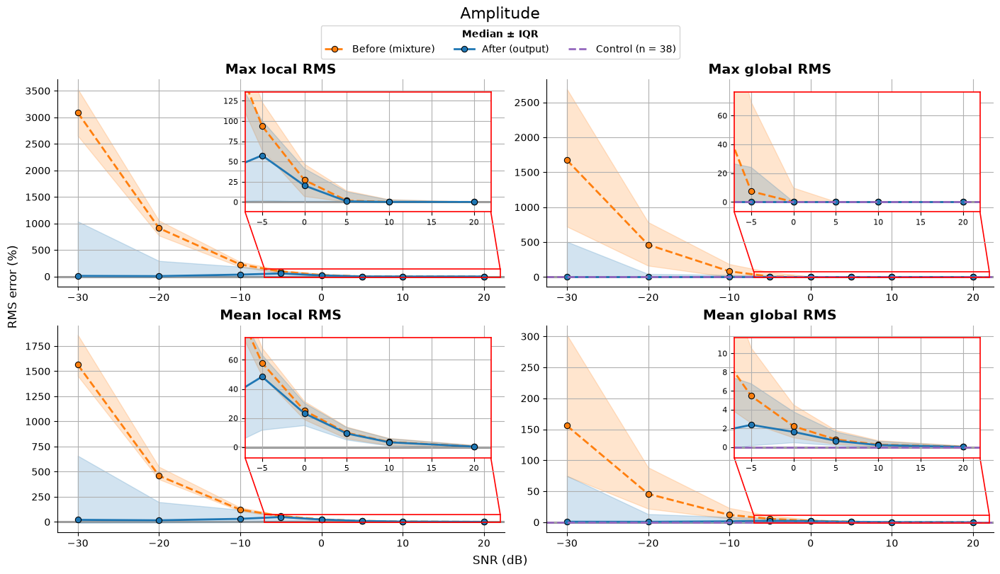

In [4]:
from matplotlib.patches import ConnectionPatch

def plot_amplitude(results_df):

    # ============================================================================ datos
    results_df = results_df.assign(snr_db=pd.to_numeric(results_df["snr_db"], errors="coerce"))   # copia: results_df no se modifica; numérico: el zoom se fija en dB

    mix_df = results_df[results_df["art_id"] != "Control"]
    ctrl_df = results_df[results_df["art_id"] == "Control"]

    ZOOM = (-7, 22)                                   # rango de SNR (dB) de las ampliaciones
    INSET_POS = [0.42, 0.36, 0.55, 0.58]               # posición de la ampliación en el panel (fracción del eje)

    # Panel -> (columna antes, columna después, ¿con control?)
    PANELS = {
        "max_loc":   ("err_rms_max_loc_mix", "err_rms_max_loc_out", False),
        "max_glob":  ("err_rms_max_glob_mix", "err_rms_max_glob_out", True),
        "mean_loc":  ("err_rms_mean_loc_mix", "err_rms_mean_loc_out", False),
        "mean_glob": ("err_rms_mean_glob_mix", "err_rms_mean_glob_out", True),
    }
    TITLES = {"max_loc": "Max local RMS", "max_glob": "Max global RMS",
            "mean_loc": "Mean local RMS", "mean_glob": "Mean global RMS"}


    def draw(ax, amp, ctrl=None, labels=True):
        """Antes / después (mediana ± IQR) y, si se da, el control (mediana y franja IQR)."""
        lab = (lambda s: s) if labels else (lambda s: "_nolegend_")
        sns.lineplot(data=amp, x="snr_db", y="before", color="tab:orange", ls="--", lw=2, marker="o", markeredgecolor="black",
                    estimator="median", errorbar=("pi", 50), label=lab("Before (mixture)"), legend=False, ax=ax)
        sns.lineplot(data=amp, x="snr_db", y="after", color="tab:blue", lw=2, marker="o", markeredgecolor="black",
                    estimator="median", errorbar=("pi", 50), label=lab("After (output)"), legend=False, ax=ax)
        if ctrl is not None:
            q25, med, q75 = ctrl.quantile([0.25, 0.5, 0.75])
            ax.axhline(med, color="tab:purple", ls="--", lw=2, label=lab(f"Control (n = {len(ctrl)})"))
            ax.axhspan(q25, q75, color="tab:purple", alpha=0.2, lw=0)
        ax.axhline(0, color="gray", lw=2, zorder=0)
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.grid()


    def iqr_limits(amp, ctrl=None, margin=0.1):
        """Límites del eje y que contienen las medianas y los IQR de antes y después (y la franja del control)."""
        q = amp.groupby("snr_db")[["before", "after"]].quantile([0.25, 0.75])
        lo, hi = q.min().min(), q.max().max()
        if ctrl is not None:
            lo, hi = min(lo, ctrl.quantile(0.25)), max(hi, ctrl.quantile(0.75))
        pad = margin * (hi - lo if hi > lo else 1)
        return lo - pad, hi + pad


    # ============================================================================ figura
    fig, axs = plt.subplots(2, 2, figsize=(14, 8), sharex=True, layout="constrained")
    ax_of = {"max_loc": axs[0, 0], "max_glob": axs[0, 1], "mean_loc": axs[1, 0], "mean_glob": axs[1, 1]}

    for key, (col_mix, col_out, with_ctrl) in PANELS.items():
        ax = ax_of[key]
        amp = mix_df.assign(before=mix_df[col_mix], after=mix_df[col_out])
        ctrl = ctrl_df[col_out] if with_ctrl else None

        # Panel completo
        draw(ax, amp, ctrl)
        ax.set_title(TITLES[key], fontsize=14, fontweight="bold")
        ax.tick_params(labelbottom=True)

        # Ampliación de ZOOM en la esquina superior derecha (zoom natural: todos los datos, solo cambian los límites)
        ins = ax.inset_axes(INSET_POS)
        draw(ins, amp, ctrl, labels=False)
        ins.set_xlim(*ZOOM)
        ins.set_ylim(*iqr_limits(amp[amp["snr_db"].between(*ZOOM)], ctrl))
        ins.tick_params(labelsize=8)
        ins.set_facecolor("white")
        for spine in ins.spines.values():                  # borde del recuadro en rojo
            spine.set_visible(True)
            spine.set_edgecolor("red")
            spine.set_linewidth(1.2)
        # Rectángulo de la zona ampliada (sin brazos automáticos)
        y0, y1 = ins.get_ylim()
        ax.indicate_inset((ZOOM[0], y0, ZOOM[1] - ZOOM[0], y1 - y0), edgecolor="red", alpha=1, linewidth=1.2)

        # Brazos: esquinas superiores del rectángulo -> esquinas inferiores del recuadro
        for x_data, x_axes in ((ZOOM[0], 0), (ZOOM[1], 1)):
            ax.add_artist(ConnectionPatch(xyA=(x_data, y1), coordsA=ax.transData,
                                        xyB=(x_axes, 0), coordsB=ins.transAxes,
                                        color="red", lw=1.2))

    fig.supxlabel("SNR (dB)", fontsize=12)
    fig.supylabel("RMS error (%)", fontsize=12)
    fig.suptitle("Amplitude", fontsize=16, y=0.995, va="top")

    handles, labels = ax_of["mean_glob"].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.97), ncol=len(labels), fontsize=10,
            title="Median ± IQR", title_fontproperties=dict(weight="bold"))
    fig.get_layout_engine().set(rect=(0, 0, 1, 0.9))

    sns.despine(fig)
    plt.show()

plot_amplitude(results_df)

In [5]:
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.colors import to_hex
from matplotlib.figure import Figure
from matplotlib.lines import Line2D

from src.summary_plots import FONT, MPL_TICKFORMAT, mpl_nticks, mpl_range, rgba, rounded_rect


def _amplitude_geometry(fig_w, fig_h, dpi, spec):
    """
    Geometría de la figura de plot_amplitude tal como la calcula matplotlib (layout="constrained" con
    rect=(0, 0, 1, 0.9)): crea la misma figura SIN datos (títulos, límites, ampliaciones, textos de la figura y
    leyenda) y devuelve las cajas (px desde la esquina superior izquierda de la imagen recortada como
    bbox_inches="tight") de los ejes, las ampliaciones, los textos y la leyenda.
    spec: {"panels": {clave: dict(title, ylim, inset_ylim)} (en el orden de axs.flat), "xlim", "zoom", "inset_pos",
    "legend", "legend_title", "suptitle", "supxlabel", "supylabel"}
    """
    fig = Figure(figsize=(fig_w, fig_h), dpi=dpi, layout="constrained")
    canvas = FigureCanvasAgg(fig)
    axs = dict(zip(spec["panels"], fig.subplots(2, 2, sharex=True).flat))

    insets = {}
    for k, ax in axs.items():
        s = spec["panels"][k]
        ax.set_title(s["title"], fontsize=14, fontweight="bold")
        ax.set_xlim(*spec["xlim"])
        ax.set_ylim(*s["ylim"])
        ax.tick_params(labelbottom=True)
        ax.spines[["top", "right"]].set_visible(False)                              # sns.despine
        ins = insets[k] = ax.inset_axes(spec["inset_pos"])
        ins.set_xlim(*spec["zoom"])
        ins.set_ylim(*s["inset_ylim"])
        ins.tick_params(labelsize=8)

    fig.supxlabel(spec["supxlabel"], fontsize=12)
    fig.supylabel(spec["supylabel"], fontsize=12)
    fig.suptitle(spec["suptitle"], fontsize=16, y=0.995, va="top")
    leg = fig.legend([Line2D([], [], marker="o") for _ in spec["legend"]], spec["legend"], loc="upper center",
                     bbox_to_anchor=(0.5, 0.97), ncol=len(spec["legend"]), fontsize=10, title=spec["legend_title"],
                     title_fontproperties=dict(weight="bold"))
    fig.get_layout_engine().set(rect=(0, 0, 1, 0.9))

    canvas.draw()
    r = canvas.get_renderer()
    tight = fig.get_tightbbox(r)
    pad = 0.1*dpi                                                                # pad_inches de bbox_inches="tight"
    x0, y_top = tight.x0*dpi - pad, tight.y1*dpi + pad

    def box(artist):
        bb = artist.get_window_extent(r)
        return dict(x0=bb.x0 - x0, x1=bb.x1 - x0, top=y_top - bb.y1, bottom=y_top - bb.y0)

    out = dict(size=(int(tight.width*dpi + 2*pad), int(tight.height*dpi + 2*pad)), suptitle=box(fig._suptitle),
               supxlabel=box(fig._supxlabel), supylabel=box(fig._supylabel), legend=box(leg),
               legend_texts=[box(t) for t in leg.get_texts()], legend_title=box(leg.get_title()))
    for k, ax in axs.items():
        out[k] = dict(ax=box(ax), title=box(ax.title), inset=box(insets[k]))
    return out


def plot_amplitude(results_df, width: int = None, dpi: float = 100) -> go.Figure:
    """
    Versión interactiva (plotly) de plot_amplitude (matplotlib/seaborn): mismo diseño (layout="constrained",
    figsize 14 x 8 in, leyenda común arriba), tamaños, fuentes, colores y posiciones. La figura se recorta como el
    backend inline (bbox_inches="tight"), así que su tamaño coincide con el de la imagen de matplotlib.
    - Cuatro paneles (RMS máximo / medio, local / global): error de RMS antes (mezcla) y después (salida) del
      algoritmo vs SNR, mediana ± IQR; en los globales, también el control (mediana y franja IQR)
    - En cada panel, una ampliación del rango de SNR ZOOM (recuadro rojo) unida con brazos a la zona ampliada
    Interactividad: hover con la mediana, el IQR y n de cada punto (en los paneles y en las ampliaciones); clic en la
    leyenda para ocultar/mostrar cada curva (línea, franja y ampliaciones a la vez; el control, línea y franja); zoom
    en cada panel (el eje x es común a los cuatro, como sharex) y en cada ampliación (independiente).
    - width: ancho de la figura (px). Solo cambia el ancho de los ejes (fuentes y márgenes no cambian). None -> como
      matplotlib
    - dpi: px por pulgada (matplotlib inline: 100). Todos los tamaños (fuentes, líneas, márgenes) escalan con él
    Las posiciones de los ejes, ampliaciones y textos se toman del constrained layout de matplotlib aplicado a la misma
    figura sin datos (_amplitude_geometry). Limitaciones: el rectángulo de la zona ampliada y los brazos siguen al zoom
    del panel, pero los brazos no siguen al de la ampliación (sus extremos en el recuadro son los iniciales); plotly
    no usa pasos de 2,5 en los ticks (0, 200, 400... en vez de 0, 250, 500...); las franjas IQR quedan encima de la
    rejilla (en matplotlib, debajo); los símbolos de la leyenda de plotly no son los de matplotlib (línea a 5-35 px).
    """

    # ============================================================================ constantes (como la versión matplotlib)
    ZOOM = (-7, 22)                                   # rango de SNR (dB) de las ampliaciones
    INSET_POS = [0.42, 0.36, 0.55, 0.58]               # posición de la ampliación en el panel (fracción del eje)

    # Panel -> (columna antes, columna después, ¿con control?)
    PANELS = {
        "max_loc":   ("err_rms_max_loc_mix", "err_rms_max_loc_out", False),
        "max_glob":  ("err_rms_max_glob_mix", "err_rms_max_glob_out", True),
        "mean_loc":  ("err_rms_mean_loc_mix", "err_rms_mean_loc_out", False),
        "mean_glob": ("err_rms_mean_glob_mix", "err_rms_mean_glob_out", True),
    }
    TITLES = {"max_loc": "Max local RMS", "max_glob": "Max global RMS",
              "mean_loc": "Mean local RMS", "mean_glob": "Mean global RMS"}

    # Curvas: (nombre, columna, color, ¿discontinua?)
    CURVES = [("Before (mixture)", "before", to_hex("tab:orange"), True),
              ("After (output)", "after", to_hex("tab:blue"), False)]
    C_CTRL, C_ZERO, C_ZOOM = to_hex("tab:purple"), to_hex("gray"), to_hex("red")


    # ============================================================================ datos
    results_df = results_df.assign(snr_db=pd.to_numeric(results_df["snr_db"], errors="coerce"))   # copia: results_df no se modifica; numérico: el zoom se fija en dB

    mix_df = results_df[results_df["art_id"] != "Control"]
    ctrl_df = results_df[results_df["art_id"] == "Control"]


    def iqr_limits(amp, ctrl=None, margin=0.1):
        """Límites del eje y que contienen las medianas y los IQR de antes y después (y la franja del control)."""
        q = amp.groupby("snr_db")[["before", "after"]].quantile([0.25, 0.75])
        lo, hi = q.min().min(), q.max().max()
        if ctrl is not None:
            lo, hi = min(lo, ctrl.quantile(0.25)), max(hi, ctrl.quantile(0.75))
        pad = margin * (hi - lo if hi > lo else 1)
        return lo - pad, hi + pad


    # Mediana, IQR y n por nivel de SNR de cada curva (como sns.lineplot con estimator="median", errorbar=("pi", 50));
    # control: cuartiles; límites de los paneles (datos + 5 %, incluida la línea en 0) y de las ampliaciones
    stats, ctrl_q, ctrl_n, y_ranges, inset_ranges = {}, {}, {}, {}, {}
    for key, (col_mix, col_out, with_ctrl) in PANELS.items():
        amp = mix_df.assign(before=mix_df[col_mix], after=mix_df[col_out])
        gb = amp.groupby("snr_db")
        stats[key] = {col: pd.DataFrame({"med": gb[col].median(), "q25": gb[col].quantile(0.25),
                                         "q75": gb[col].quantile(0.75), "n": gb[col].count()})
                      for _, col, _, _ in CURVES}
        ctrl = ctrl_df[col_out] if with_ctrl else None
        if with_ctrl:
            ctrl_q[key], ctrl_n[key] = ctrl.quantile([0.25, 0.5, 0.75]).to_numpy(), len(ctrl)
        y_ranges[key] = mpl_range(*[s.to_numpy()[:, :3] for s in stats[key].values()], [0], ctrl_q.get(key, [0]))
        inset_ranges[key] = list(iqr_limits(amp[amp["snr_db"].between(*ZOOM)], ctrl))
    lv = np.sort(mix_df["snr_db"].unique())                             # niveles de SNR
    x_range = mpl_range(lv)

    LBL_CTRL = f"Control (n = {ctrl_n['mean_glob']})"                  # leyenda de la versión matplotlib: la de mean_glob
    legend_labels = [c[0] for c in CURVES] + [LBL_CTRL]


    # ============================================================================ geometría (como matplotlib)
    PT = dpi / 72                                                                  # px por punto
    pt = lambda v: v * PT
    em = pt(10)                                                                    # fuente de ticks y leyendas (px)
    dash = lambda lw: f"{pt(3.7*lw):.1f}px,{pt(1.6*lw):.1f}px"                    # línea "--" de ancho lw (pt)

    spec = dict(panels={k: dict(title=TITLES[k], ylim=y_ranges[k], inset_ylim=inset_ranges[k]) for k in PANELS},
                xlim=x_range, zoom=ZOOM, inset_pos=INSET_POS, legend=legend_labels, legend_title="Median ± IQR",
                suptitle="Amplitude", supxlabel="SNR (dB)", supylabel="RMS error (%)")

    fig_w, fig_h = 14, 8
    geo = _amplitude_geometry(fig_w, fig_h, dpi, spec)
    for _ in range(6 if width else 0):                                             # ancho pedido: solo cambian los ejes
        if geo["size"][0] == width:
            break
        fig_w += (width - geo["size"][0]) / dpi
        geo = _amplitude_geometry(fig_w, fig_h, dpi, spec)
    W, H = geo["size"]
    X = lambda v: v / W                                                            # px -> papel
    Y = lambda v: 1 - v / H
    dom_x = lambda b: [X(b["x0"]), X(b["x1"])]
    dom_y = lambda b: [Y(b["bottom"]), Y(b["top"])]
    ax_len_pt = lambda b, k: (b["x1"] - b["x0"] if k == "x" else b["bottom"] - b["top"]) / PT

    def nticks(axis_range, b, k, fontsize=10):
        """
        nticks de plotly que da los ticks de matplotlib (mpl_nticks). plotly redondea rango/nticks al paso 1-2-5
        SIGUIENTE cuando cae justo en uno (30/6 = 5 -> 10), así que en ese caso se pide un tick más
        """
        n = mpl_nticks(axis_range, ax_len_pt(b, k), 3 if k == "x" else 2, fontsize)
        rough = (axis_range[1] - axis_range[0]) / n
        return n + 1 if np.isclose(rough / 10**np.floor(np.log10(rough)), [1, 2, 5]).any() else n

    axis_style = dict(showline=True, mirror=False, linecolor="black", linewidth=pt(0.8), ticks="outside",
                      ticklen=pt(3.5), tickwidth=pt(0.8), tickcolor="black", tickfont=dict(size=em),
                      showgrid=True, gridcolor="#b0b0b0", gridwidth=pt(0.8), zeroline=False, automargin=False,
                      tickformatstops=MPL_TICKFORMAT, exponentformat="none")      # sns.despine: sin ejes arriba/derecha
    inset_style = {**axis_style, "mirror": True, "linecolor": C_ZOOM, "linewidth": pt(1.2),
                   "tickfont": dict(size=pt(8))}                                   # recuadro rojo, ticks de 8 pt

    # Ejes: paneles 1-4 (en el orden de PANELS) y ampliaciones 5-8
    keys = list(PANELS)
    ax_id = {k: ("" if i == 0 else str(i + 1)) for i, k in enumerate(keys)}
    ins_id = {k: str(i + 5) for i, k in enumerate(keys)}
    layout = {}
    for k in keys:
        b, bi = geo[k]["ax"], geo[k]["inset"]
        a, i = ax_id[k], ins_id[k]
        layout[f"xaxis{a}"] = dict(domain=dom_x(b), anchor=f"y{a}", range=x_range, nticks=nticks(x_range, b, "x"),
                                   ticklabelstandoff=round(-2.2 * PT), **({"matches": "x"} if a else {}), **axis_style)
        layout[f"yaxis{a}"] = dict(domain=dom_y(b), anchor=f"x{a}", range=y_ranges[k],
                                   nticks=nticks(y_ranges[k], b, "y"), **axis_style)
        layout[f"xaxis{i}"] = dict(domain=dom_x(bi), anchor=f"y{i}", range=list(ZOOM),
                                   nticks=nticks(list(ZOOM), bi, "x", 8), ticklabelstandoff=round(-2.2 * 0.8 * PT),
                                   **inset_style)
        layout[f"yaxis{i}"] = dict(domain=dom_y(bi), anchor=f"x{i}", range=inset_ranges[k],
                                   nticks=nticks(inset_ranges[k], bi, "y", 8), **inset_style)

    # Leyenda: una leyenda de plotly por elemento, en la posición del texto de matplotlib (el texto de un elemento de
    # plotly empieza 40 px a la derecha de la x de la leyenda), un marco con esquinas redondeadas y el título en negrita
    legends, leg_id = {}, {}
    for n, (name, t) in enumerate(zip(legend_labels, geo["legend_texts"]), start=1):
        lid = leg_id[name] = "legend" if n == 1 else f"legend{n}"
        legends[lid] = dict(x=X(t["x0"] - 40), y=Y((t["top"] + t["bottom"]) / 2 - 0.1 * em), xanchor="left",
                            yanchor="middle", orientation="h", bgcolor="rgba(0, 0, 0, 0)", borderwidth=0,
                            font=dict(size=em), groupclick="togglegroup", itemwidth=30)
    b = geo["legend"]
    shapes = [dict(type="path", xref="paper", yref="paper", layer="above", fillcolor="rgba(255, 255, 255, 0.8)",
                   line=dict(color="#cccccc", width=pt(1)),
                   path=rounded_rect(X(b["x0"]), X(b["x1"]), Y(b["bottom"]), Y(b["top"]), 0.2 * em, W, H))]

    fig = go.Figure()

    def hline(y, axis, color, lw, dashed=False, layer="below", **kw):
        """Línea horizontal de todo el ancho del panel (axhline)"""
        return dict(type="line", xref=f"x{axis} domain", yref=f"y{axis}", x0=0, x1=1, y0=y, y1=y, layer=layer,
                    line=dict(color=color, width=pt(lw), dash=dash(lw) if dashed else None), **kw)

    def draw(key, axis, show_legend):
        """Antes / después (mediana ± IQR) y, si lo hay, el control (mediana y franja IQR), como draw de matplotlib"""
        shapes.append(hline(0, axis, C_ZERO, 2))                                   # zorder=0: debajo de todo
        common = lambda name, col: dict(legend=leg_id[name], legendgroup=col, xaxis=f"x{axis}", yaxis=f"y{axis}")
        for name, col, color, _ in CURVES:                                         # franjas (zorder 1): debajo de
            s = stats[key][col]                                                    # todas las líneas
            x = s.index.to_numpy(float)
            fig.add_trace(go.Scatter(x=np.r_[x, x[::-1]], y=np.r_[s["q75"], s["q25"][::-1]], mode="lines",
                                     fill="toself", fillcolor=rgba(color, 0.2), line=dict(width=0), hoverinfo="skip",
                                     showlegend=False, **common(name, col)))
        for name, col, color, dashed in CURVES:
            s = stats[key][col]
            x = s.index.to_numpy(float)
            fig.add_trace(go.Scatter(
                x=x, y=s["med"], mode="lines+markers", name=name,
                line=dict(color=color, width=pt(2), dash=dash(2) if dashed else None),
                marker=dict(size=pt(6), color=color, line=dict(color="#000000", width=pt(0.75))),
                customdata=s[["q25", "q75", "n"]].to_numpy(),
                hovertemplate=(f"{name}<br>SNR: %{{x:g}} dB<br>Median: %{{y:.2f}} %<br>"
                               "IQR: (%{customdata[0]:.2f}, %{customdata[1]:.2f}) %<br>"
                               f"n = %{{customdata[2]:.0f}} mixtures<extra>{TITLES[key]}</extra>"),
                showlegend=show_legend, **common(name, col)))
        if key in ctrl_q:
            q25, med, q75 = ctrl_q[key]
            ctrl_kw = dict(legend=leg_id[LBL_CTRL], legendgroup="control")
            shapes.append(dict(type="rect", xref=f"x{axis} domain", yref=f"y{axis}", x0=0, x1=1, y0=q25, y1=q75,
                               layer="below", fillcolor=rgba(C_CTRL, 0.2), line=dict(width=0), **ctrl_kw))
            shapes.append(hline(med, axis, C_CTRL, 2, dashed=True, layer="above", name=LBL_CTRL,
                                showlegend=show_legend, **ctrl_kw))                # encima de las curvas, como matplotlib

    for k in keys:
        a, i = ax_id[k], ins_id[k]
        draw(k, a, show_legend=(k == "max_glob"))                                 # panel completo
        draw(k, i, show_legend=False)                                              # ampliación (todos los datos)

        # Rectángulo de la zona ampliada (encima de las curvas) y brazos: esquinas superiores del rectángulo ->
        # esquinas inferiores del recuadro (en coordenadas de datos del panel, con sus límites iniciales)
        y0, y1 = inset_ranges[k]
        shapes.append(dict(type="rect", xref=f"x{a}", yref=f"y{a}", x0=ZOOM[0], x1=ZOOM[1], y0=y0, y1=y1,
                           layer="above", line=dict(color=C_ZOOM, width=pt(1.2))))
        b, bi = geo[k]["ax"], geo[k]["inset"]
        y_corner = y_ranges[k][0] + (b["bottom"] - bi["bottom"]) / (b["bottom"] - b["top"]) * np.diff(y_ranges[k])[0]
        for x_data, x_px in ((ZOOM[0], bi["x0"]), (ZOOM[1], bi["x1"])):
            x_corner = x_range[0] + (x_px - b["x0"]) / (b["x1"] - b["x0"]) * (x_range[1] - x_range[0])
            shapes.append(dict(type="line", xref=f"x{a}", yref=f"y{a}", x0=x_data, y0=y1, x1=x_corner, y1=y_corner,
                               layer="below", line=dict(color=C_ZOOM, width=pt(1.2))))

    # ---------------------------------------------------------------- títulos, etiquetas y leyenda
    def ann(s, b, size, rotate=False):
        """Texto centrado en la caja b de matplotlib (subido 0,1 em: Arial queda más baja que DejaVu Sans)"""
        cx, cy = (b["x0"] + b["x1"]) / 2, (b["top"] + b["bottom"]) / 2
        if rotate:
            cx -= 0.1 * pt(size)
        else:
            cy -= 0.1 * pt(size)
        return dict(text=s, x=X(cx), y=Y(cy), xref="paper", yref="paper", xanchor="center", yanchor="middle",
                    showarrow=False, font=dict(size=pt(size)), textangle=-90 if rotate else 0)

    annotations = [ann(spec["suptitle"], geo["suptitle"], 16), ann(spec["supxlabel"], geo["supxlabel"], 12),
                   ann(spec["supylabel"], geo["supylabel"], 12, rotate=True),
                   ann(f"<b>{spec['legend_title']}</b>", geo["legend_title"], 10)]
    annotations += [ann(f"<b>{TITLES[k]}</b>", geo[k]["title"], 14) for k in keys]

    fig.update_layout(
        **layout, **legends, width=W, height=H, margin=dict(l=0, r=0, t=0, b=0, autoexpand=False),
        annotations=annotations, shapes=shapes, font=dict(family=FONT, size=em, color="black"),
        paper_bgcolor="white", plot_bgcolor="white", hovermode="closest", template="none"
    )
    return fig

plot_amplitude(results_df).show()

#### 5.4.5. Factor analysis

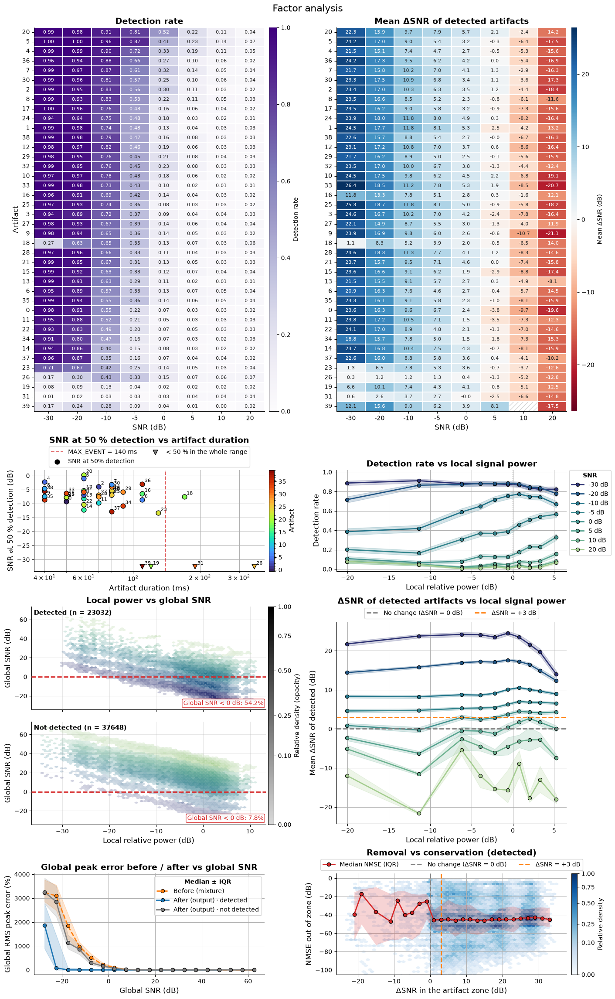

In [150]:
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap, ListedColormap, Normalize, PowerNorm, to_rgba

def plot_factor_analysis(results_df):

    # ============================================================================ constantes
    N_BINS = 10                                     # D y F: grupos de potencia local relativa (deciles)
    GRID = (60, 30)                                 # E: número de hexágonos (x, y)
    GAMMA = 0.5                                     # E y H: densidad en escala de potencia (1 = lineal; < 1 realza lo poco denso)
    DENSITY_TICKS = [0, 0.1, 0.25, 0.5, 0.75, 1]    # E y H: ticks de las barras de densidad
    BIN_W = 5                                       # G: dB, anchura de los intervalos de SNR global
    DS_BIN = 2                                      # H: dB, anchura de los intervalos de ΔSNR
    MIN_N = 30                                      # G y H: mínimo de mezclas por intervalo
    NMSE_FLOOR = -100                               # H: dB, por debajo = sin cambios fuera de la zona
    LINE_KW = dict(marker="o", markeredgecolor="black", lw=2)              # estilo común de las curvas


    # ============================================================================ funciones auxiliares
    def snr_at_50(rate, levels):
        """SNR al que la tasa cruza 0,5 (interpolación lineal). +inf / -inf: por encima / por debajo del rango."""
        above = rate >= 0.5
        if not above.any():
            return -np.inf
        i = np.where(above)[0].max()
        if i == len(rate) - 1:
            return np.inf
        r0, r1 = rate[i], rate[i + 1]
        return levels[i] + (0.5 - r0) * (levels[i + 1] - levels[i]) / (r1 - r0)


    def opacity_cmap(color, low=0.15):
        """Del color semitransparente (densidad baja) al color opaco (densidad alta)."""
        return LinearSegmentedColormap.from_list("", [to_rgba(color, low), to_rgba(color, 1.0)])


    # ============================================================================ datos
    results_df = results_df.assign(                                          # copia: results_df no se modifica
        snr_db=pd.to_numeric(results_df["snr_db"], errors="coerce"),
        detected=(results_df["detected"].astype(str).str.strip().str.lower()
                  .map({"true": 1.0, "false": 0.0, "1": 1.0, "0": 0.0, "1.0": 1.0, "0.0": 0.0})))   # controles -> NaN

    mix_df = results_df[results_df["art_id"] != "Control"]
    det_df = mix_df[mix_df["detected"] == 1]                                 # mezclas detectadas (B, E, F, G, H)

    # ---------------------------------------------------------------- A: tasa de detección (artefacto × SNR)
    det_rate = mix_df.pivot_table(index="art_id", columns="snr_db", values="detected", aggfunc="mean")
    lv = det_rate.columns.to_numpy()                                         # niveles de SNR

    # Orden de las filas: SNR al 50 % de mayor a menor (más sensible arriba); se reutiliza en B
    snr50 = pd.Series([snr_at_50(r, lv) for r in det_rate.to_numpy()], index=det_rate.index)
    art_rows = snr50.replace({np.inf: 1e9, -np.inf: -1e9}).sort_values(ascending=False).index

    # ---------------------------------------------------------------- B: ΔSNR medio de los detectados (artefacto × SNR)
    ds_mean = (det_df.pivot_table(index="art_id", columns="snr_db", values="dsnr_db", aggfunc="mean")
               .reindex(index=art_rows, columns=lv))                         # mismo orden que A; sin detecciones -> NaN
    ds_lim = np.nanmax(np.abs(ds_mean.to_numpy()))                          # escala simétrica alrededor de 0

    # ---------------------------------------------------------------- C: SNR al 50 % vs duración del artefacto
    dur = mix_df.groupby("art_id")["art_duration_ms"].first().reindex(snr50.index)   # duración de cada artefacto
    art_order = sorted(snr50.index, key=int)                                         # 0, 1, 2, …
    art_colors = dict(zip(art_order, sns.color_palette("turbo", len(art_order))))   # mismos colores que en Detection

    # Fuera de rango: medio paso por encima (▲, >= 50 % en todo el rango) o por debajo (▼, < 50 % en todo el rango)
    step = np.min(np.diff(lv))
    y_lo, y_hi = lv.min() - 0.5 * step, lv.max() + 0.5 * step
    dur_pts = [(art, dur[art], *((y_hi, "^") if np.isposinf(s50) else (y_lo, "v") if np.isneginf(s50) else (s50, "o")))
               for art, s50 in snr50.items()]                                # (artefacto, x, y, marcador)

    # ---------------------------------------------------------------- D y F: grupos de potencia local relativa
    mix_p = mix_df.dropna(subset=["p_local_rel_db"]).copy()
    mix_p["p_bin"] = pd.qcut(mix_p["p_local_rel_db"], N_BINS)                   # deciles: mismo nº de mezclas
    centers = mix_p.groupby("p_bin", observed=True)["p_local_rel_db"].median()
    mix_p["p_center"] = mix_p["p_bin"].map(centers).astype(float)                # cada punto en la mediana de su grupo
    det_p = mix_p[mix_p["detected"] == 1]                                        # F: mismos grupos que en D

    # ---------------------------------------------------------------- E: potencia local vs SNR global (detectados / no)
    sc = mix_df.dropna(subset=["p_local_rel_db", "snr_global_db"])
    sub_pts = {"Detected": sc[sc["detected"] == 1], "Not detected": sc[sc["detected"] != 1]}
    extent = (sc["p_local_rel_db"].min(), sc["p_local_rel_db"].max(),
              sc["snr_global_db"].min(), sc["snr_global_db"].max())              # rejilla común
    snr_cmap = sns.color_palette("crest_r", as_cmap=True)                        # color = SNR (como en D)
    snr_norm = Normalize(lv.min(), lv.max())

    # ---------------------------------------------------------------- G: error del pico global antes / después vs SNR global
    pk = mix_df.dropna(subset=["snr_global_db"]).assign(
        det_lbl=lambda d: np.where(d["detected"] == 1, "Detected", "Not detected"))
    edges_g = np.arange(np.floor(pk["snr_global_db"].min() / BIN_W) * BIN_W, pk["snr_global_db"].max() + BIN_W, BIN_W)
    pk["g_center"] = pd.cut(pk["snr_global_db"], edges_g).apply(lambda b: b.mid).astype(float)
    pk = pk[pk.groupby(["g_center", "det_lbl"])["snr_global_db"].transform("size") >= MIN_N]   # fuera intervalos casi vacíos

    # ---------------------------------------------------------------- H: ΔSNR vs NMSE fuera de la zona (detectados)
    tr = det_df.dropna(subset=["dsnr_db", "nmse_out_zone_db"])

    # Mediana e IQR del NMSE por intervalos de ΔSNR: ¿más eliminación implica más cambio fuera de la zona?
    edges_h = np.arange(np.floor(tr["dsnr_db"].min() / DS_BIN) * DS_BIN, tr["dsnr_db"].max() + DS_BIN, DS_BIN)
    g = tr.groupby(pd.cut(tr["dsnr_db"], edges_h), observed=True)["nmse_out_zone_db"]
    tr_stats = g.quantile([0.25, 0.5, 0.75]).unstack()                       # columnas: 0.25, 0.5, 0.75
    tr_stats = tr_stats[g.size() >= MIN_N]                                   # fuera intervalos casi vacíos
    x_mid = [b.mid for b in tr_stats.index]


    # ============================================================================ figura
    n_art = len(art_order)
    fig = plt.figure(figsize=(14, 18 + 0.12 * n_art), layout="constrained")
    gs = fig.add_gridspec(4, 2, height_ratios=[0.7 * n_art / 10 + 1, 1, 2, 1])
    fig.suptitle("Factor analysis", fontsize=16)

    ax_hdet = fig.add_subplot(gs[0, 0])                                   # A: detección (artefacto × SNR)
    ax_hds  = fig.add_subplot(gs[0, 1], sharey=ax_hdet)                   # B: ΔSNR de los detectados (artefacto × SNR)
    ax_dur  = fig.add_subplot(gs[1, 0])                                   # C: SNR al 50 % vs duración
    ax_pdet = fig.add_subplot(gs[1, 1])                                   # D: detección vs potencia local
    sub_glob = gs[2, 0].subgridspec(2, 1)                                 # E: dos subpaneles en la misma celda
    ax_gd = fig.add_subplot(sub_glob[0])                                  # detectados
    ax_gn = fig.add_subplot(sub_glob[1], sharex=ax_gd, sharey=ax_gd)      # no detectados
    ax_pds  = fig.add_subplot(gs[2, 1], sharex=ax_pdet)                   # F: ΔSNR vs potencia local
    ax_peak = fig.add_subplot(gs[3, 0])                                   # G: reducción del pico global vs SNR global
    ax_tr   = fig.add_subplot(gs[3, 1])                                   # H: ΔSNR vs NMSE fuera de la zona

    # ---------------------------------------------------------------- A: tasa de detección (artefacto × SNR)
    sns.heatmap(det_rate.loc[art_rows], cmap="Purples", vmin=0, vmax=1, linewidths=0.3, linecolor="white",
                annot=True, fmt=".2f", annot_kws={"fontsize": 8},
                cbar_kws={"label": "Detection rate", "aspect": 50, "pad": 0.02}, ax=ax_hdet)

    ax_hdet.set_xticklabels([f"{v:g}" for v in lv], rotation=0)
    ax_hdet.tick_params(axis="y", rotation=0)
    ax_hdet.set_xlabel("SNR (dB)", fontsize=12)
    ax_hdet.set_ylabel("Artifact", fontsize=12)
    ax_hdet.set_title("Detection rate", fontsize=14, fontweight="bold")

    # ---------------------------------------------------------------- B: ΔSNR medio de los detectados (artefacto × SNR)
    cax_hds = ax_hds.inset_axes([1.02, 0, 0.025, 1])                     # pegado a la derecha del mapa, a toda su altura
    sns.heatmap(ds_mean, cmap="RdBu", center=0, vmin=-ds_lim, vmax=ds_lim, linewidths=0.3, linecolor="white",
                annot=True, fmt=".1f", annot_kws={"fontsize": 8},
                cbar_ax=cax_hds, cbar_kws={"label": "Mean ΔSNR (dB)"}, ax=ax_hds)

    # Celdas sin ninguna detección: tramado de fondo (las NaN quedan transparentes)
    ax_hds.patch.set_hatch("///")
    ax_hds.patch.set_edgecolor("lightgray")
    ax_hds.patch.set_facecolor("white")

    ax_hds.set_xticklabels([f"{v:g}" for v in lv], rotation=0)
    ax_hds.tick_params(axis="y", rotation=0)
    ax_hds.set_xlabel("SNR (dB)", fontsize=12)
    ax_hds.set_ylabel("")
    ax_hds.set_title("Mean ΔSNR of detected artifacts", fontsize=14, fontweight="bold")

    # ---------------------------------------------------------------- C: SNR al 50 % vs duración del artefacto
    for art, x, y, mk in dur_pts:
        ax_dur.scatter(x, y, marker=mk, s=60, color=art_colors[art], edgecolor="black", lw=1, zorder=3)
        ax_dur.annotate(str(art), (x, y), xytext=(4, 3), textcoords="offset points", fontsize=8)

    ax_dur.axvline(MAX_EVENT * 1000, color="tab:red", ls="--", lw=1.5, alpha=0.7,
                   label=f"MAX_EVENT = {MAX_EVENT*1000:g} ms")

    # Entradas de leyenda (en negro / gris, independientes del color de cada artefacto)
    ax_dur.scatter([], [], marker="o", s=60, color="black", edgecolor="black", label="SNR at 50% detection")
    if np.isneginf(snr50).any():
        ax_dur.scatter([], [], marker="v", s=60, color="gray", edgecolor="black", label="< 50 % in the whole range")
    if np.isposinf(snr50).any():
        ax_dur.scatter([], [], marker="^", s=60, color="gray", edgecolor="black", label="≥ 50 % in the whole range")

    # Barra de colores de los artefactos
    cmap_art = ListedColormap([art_colors[a] for a in art_order])
    norm_art = BoundaryNorm(np.arange(-0.5, n_art), n_art)
    cb = fig.colorbar(plt.cm.ScalarMappable(cmap=cmap_art, norm=norm_art), ax=ax_dur, location="right",
                      aspect=20, pad=0.02)
    tick_idx = np.arange(0, n_art, 5)
    cb.set_ticks(tick_idx, labels=[art_order[i] for i in tick_idx])
    cb.set_label("Artifact", fontsize=11)

    ax_dur.set_xscale("log")
    ax_dur.set_xlabel("Artifact duration (ms)", fontsize=12)
    ax_dur.set_ylabel("SNR at 50 % detection (dB)", fontsize=12)
    ax_dur.set_title("SNR at 50 % detection vs artifact duration", fontsize=14, fontweight="bold", pad=45)
    ax_dur.legend(fontsize=10, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
    ax_dur.grid(which="both")

    # ---------------------------------------------------------------- D: tasa de detección vs potencia local relativa
    sns.lineplot(data=mix_p, x="p_center", y="detected", hue="snr_db", palette="crest_r", legend="full",
                 errorbar=("ci", 95), **LINE_KW, ax=ax_pdet)

    ax_pdet.axvline(0, color="gray", ls=":", lw=1.2)                             # nivel medio de la señal
    ax_pdet.set_ylim(-0.02, 1.02)
    ax_pdet.set_xlabel("Local relative power (dB)", fontsize=12)
    ax_pdet.set_ylabel("Detection rate", fontsize=12)
    ax_pdet.set_title("Detection rate vs local signal power", fontsize=14, fontweight="bold")
    handles, labels = ax_pdet.get_legend_handles_labels()
    ax_pdet.legend(handles, [f"{float(l):g} dB" for l in labels], title="SNR", fontsize=10, loc="upper left",
                   bbox_to_anchor=(1.01, 1), borderaxespad=0, title_fontproperties=dict(weight="bold"))
    ax_pdet.grid()

    # ---------------------------------------------------------------- E: potencia local vs SNR global (detectados / no)
    # Color = SNR (como en D) · opacidad = densidad relativa (proporción del subpanel / máximo; escala de potencia)
    hbs = []
    for ax, d in zip((ax_gd, ax_gn), sub_pts.values()):
        n_total = len(d)                                                         # total del subpanel (todos los SNR)
        # SNR altos primero y bajos al final: las bandas de artefactos fuertes quedan encima donde se solapan
        for lvl in sorted(d["snr_db"].unique(), reverse=True):
            dl = d[d["snr_db"] == lvl]
            h = ax.hexbin(dl["p_local_rel_db"], dl["snr_global_db"], gridsize=GRID, extent=extent, mincnt=1,
                          cmap=opacity_cmap(snr_cmap(snr_norm(lvl))), linewidths=0, zorder=2)
            h.set_array(h.get_array() / n_total)                                 # nº de mezclas -> proporción del subpanel
            hbs.append(h)
        ax.axhline(0, color="tab:red", ls="--", lw=2, zorder=3)
        ax.grid(alpha=0.3)

        # Fracción de mezclas que dominan el fragmento completo (SNR global < 0 dB)
        frac = (d["snr_global_db"] < 0).mean()
        ax.text(0.99, 0.03, f"Global SNR < 0 dB: {frac:.1%}", transform=ax.transAxes, ha="right", va="bottom",
                fontsize=10, color="tab:red", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="tab:red", alpha=0.9),
                zorder=4)

    # Densidad relativa: proporción / máxima proporción (de 0 a 1, común a los dos subpaneles)
    pmax = max(h.get_array().max() for h in hbs)
    for h in hbs:
        h.set_array(h.get_array() / pmax)
        h.set_norm(PowerNorm(gamma=GAMMA, vmin=0, vmax=1))

    # Barra de referencia (opacidad, en gris)
    cb = fig.colorbar(plt.cm.ScalarMappable(cmap=opacity_cmap("black"), norm=PowerNorm(gamma=GAMMA, vmin=0, vmax=1)),
                      ax=[ax_gd, ax_gn], location="right", aspect=40, pad=0.01)
    cb.set_label("Relative density (opacity)", fontsize=11)
    cb.set_ticks(DENSITY_TICKS)

    ax_gd.set_title("Local power vs global SNR", fontsize=14, fontweight="bold")
    for ax, (name, d) in zip((ax_gd, ax_gn), sub_pts.items()):
        ax.text(0.01, 0.97, f"{name} (n = {len(d)})", transform=ax.transAxes, ha="left", va="top", fontsize=11,
                fontweight="bold")
        ax.set_ylabel("Global SNR (dB)", fontsize=12)
    ax_gd.tick_params(labelbottom=False)                                         # el eje x solo abajo
    ax_gd.set_xlabel("")
    ax_gn.set_xlabel("Local relative power (dB)", fontsize=12)

    # ---------------------------------------------------------------- F: ΔSNR de los detectados vs potencia local relativa
    sns.lineplot(data=det_p, x="p_center", y="dsnr_db", hue="snr_db", palette="crest_r", legend=False,
                 errorbar=("ci", 95), **LINE_KW, ax=ax_pds)

    ax_pds.axhline(0, color="gray", ls="--", lw=2, label="No change (ΔSNR = 0 dB)")
    ax_pds.axhline(ATEN_DB, color="tab:orange", ls="--", lw=2, label=f"ΔSNR = +{ATEN_DB} dB")

    ax_pds.tick_params(labelbottom=True)
    ax_pds.set_xlabel("Local relative power (dB)", fontsize=12)
    ax_pds.set_ylabel("Mean ΔSNR of detected (dB)", fontsize=12)
    ax_pds.set_title("ΔSNR of detected artifacts vs local signal power", fontsize=14, fontweight="bold", pad=30)
    ax_pds.legend(fontsize=10, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
    ax_pds.grid()

    # ---------------------------------------------------------------- G: error del pico global antes / después vs SNR global
    line_kw = dict(x="g_center", estimator="median", errorbar=("pi", 50), **LINE_KW, ax=ax_peak)
    sns.lineplot(data=pk, y="err_rms_max_glob_mix", color="tab:orange", ls="--",
                 label="Before (mixture)", **line_kw)
    sns.lineplot(data=pk[pk["det_lbl"] == "Detected"], y="err_rms_max_glob_out", color="tab:blue",
                 label="After (output) · detected", **line_kw)
    sns.lineplot(data=pk[pk["det_lbl"] == "Not detected"], y="err_rms_max_glob_out", color="gray",
                 label="After (output) · not detected", **line_kw)

    ax_peak.set_xlabel("Global SNR (dB)", fontsize=12)
    ax_peak.set_ylabel("Global RMS peak error (%)", fontsize=12)
    ax_peak.set_title("Global peak error before / after vs global SNR", fontsize=14, fontweight="bold")
    ax_peak.legend(fontsize=10, title="Median ± IQR", title_fontproperties=dict(weight="bold"))
    ax_peak.grid()

    # ---------------------------------------------------------------- H: ΔSNR vs NMSE fuera de la zona (detectados)
    # Densidad relativa de mezclas (hexágono más poblado = 1)
    hb = ax_tr.hexbin(tr["dsnr_db"], tr["nmse_out_zone_db"], gridsize=(50, 30), mincnt=1, cmap="Blues",
                      linewidths=0, zorder=1)
    counts = hb.get_array()
    hb.set_array(counts / counts.max())
    hb.set_norm(PowerNorm(gamma=GAMMA, vmin=0, vmax=1))                       # misma escala que en el panel E

    cax_tr = ax_tr.inset_axes([1.02, 0, 0.025, 1])                           # barra pegada a la derecha del panel
    cb = fig.colorbar(hb, cax=cax_tr)
    cb.set_label("Relative density", fontsize=11)
    cb.set_ticks(DENSITY_TICKS)

    ax_tr.fill_between(x_mid, tr_stats[0.25], tr_stats[0.75], color="tab:red", alpha=0.2, lw=0, zorder=2)
    ax_tr.plot(x_mid, tr_stats[0.5], color="tab:red", **LINE_KW, zorder=3, label="Median NMSE (IQR)")

    # Referencias
    ax_tr.axvline(0, color="gray", ls="--", lw=2, label="No change (ΔSNR = 0 dB)")
    ax_tr.axvline(ATEN_DB, color="tab:orange", ls="--", lw=2, label=f"ΔSNR = +{ATEN_DB} dB")

    ax_tr.set_ylim(NMSE_FLOOR - 5, max(0, tr["nmse_out_zone_db"].max()) + 5)
    ax_tr.set_xlabel("ΔSNR in the artifact zone (dB)", fontsize=12)
    ax_tr.set_ylabel("NMSE out of zone (dB)", fontsize=12)
    ax_tr.set_title("Removal vs conservation (detected)", fontsize=14, fontweight="bold", pad=30)
    ax_tr.legend(fontsize=10, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3, borderaxespad=0.2)
    ax_tr.grid()

    sns.despine(fig)
    plt.show()

plot_factor_analysis(results_df)

In [152]:
import re

from matplotlib import colormaps
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.cm import ScalarMappable
from matplotlib.colors import (BoundaryNorm, LinearSegmentedColormap, ListedColormap, Normalize, PowerNorm, to_hex,
                               to_rgba)
from matplotlib.figure import Figure
from matplotlib.lines import Line2D
from seaborn.utils import relative_luminance

from src.summary_plots import (DASH_PATTERNS, FONT, MPL_TICKFORMAT, mpl_colorscale, mpl_dashes, mpl_nticks, mpl_range,
                           rgba, rounded_rect)


def _factor_geometry(fig_w, fig_h, dpi, spec):
    """
    Geometría de la figura de plot_factor_analysis tal como la calcula matplotlib (layout="constrained"): crea la
    misma figura SIN datos (mapas vacíos, títulos, etiquetas, límites, leyendas y barras de colores) y devuelve las
    cajas (px desde la esquina superior izquierda de la imagen recortada como bbox_inches="tight") de los ejes, textos,
    leyendas y barras de colores, los ticks de las barras y los del eje logarítmico de C.
    spec: dict(art_rows, lv, ds_lim, art_order, max_event_ms, lims={panel: (xlim, ylim)}, legends={panel: [etiquetas]},
    c_markers=[(marcador, color, etiqueta)], g_loc, density_ticks, gamma)
    """
    fig = Figure(figsize=(fig_w, fig_h), dpi=dpi, layout="constrained")
    canvas = FigureCanvasAgg(fig)
    n_art = len(spec["art_rows"])
    gs = fig.add_gridspec(4, 2, height_ratios=[0.7 * n_art / 10 + 1, 1, 2, 1])
    fig.suptitle("Factor analysis", fontsize=16)

    ax = {"A": fig.add_subplot(gs[0, 0])}
    ax["B"] = fig.add_subplot(gs[0, 1], sharey=ax["A"])
    ax["C"] = fig.add_subplot(gs[1, 0])
    ax["D"] = fig.add_subplot(gs[1, 1])
    sub_glob = gs[2, 0].subgridspec(2, 1)
    ax["Ed"] = fig.add_subplot(sub_glob[0])
    ax["En"] = fig.add_subplot(sub_glob[1], sharex=ax["Ed"], sharey=ax["Ed"])
    ax["F"] = fig.add_subplot(gs[2, 1], sharex=ax["D"])
    ax["G"] = fig.add_subplot(gs[3, 0])
    ax["H"] = fig.add_subplot(gs[3, 1])
    cbs = {}
    leg_lines = lambda labels, **kw: [Line2D([], [], **kw) for _ in labels]
    curve_kw = dict(marker="o", markeredgecolor="black", lw=2)

    # A y B: mapas vacíos (las anotaciones quedan dentro de los ejes y no cambian la disposición)
    zeros = pd.DataFrame(0.0, index=spec["art_rows"], columns=spec["lv"])
    sns.heatmap(zeros, cmap="Purples", vmin=0, vmax=1, cbar_kws={"label": "Detection rate", "aspect": 50, "pad": 0.02},
                ax=ax["A"])
    cax_b = ax["B"].inset_axes([1.02, 0, 0.025, 1])
    sns.heatmap(zeros, cmap="RdBu", center=0, vmin=-spec["ds_lim"], vmax=spec["ds_lim"], cbar_ax=cax_b,
                cbar_kws={"label": "Mean ΔSNR (dB)"}, ax=ax["B"])
    for k, title in (("A", "Detection rate"), ("B", "Mean ΔSNR of detected artifacts")):
        cbs[k] = ax[k].collections[0].colorbar
        ax[k].set_xticklabels([f"{v:g}" for v in spec["lv"]], rotation=0)
        ax[k].tick_params(axis="y", rotation=0)
        ax[k].set_xlabel("SNR (dB)", fontsize=12)
        ax[k].set_title(title, fontsize=14, fontweight="bold")
    ax["A"].set_ylabel("Artifact", fontsize=12)
    ax["B"].set_ylabel("")

    # C: leyenda con los mismos elementos (línea y marcadores de 60 pt²), barra de colores discreta y eje log
    a = ax["C"]
    a.axvline(spec["max_event_ms"], color="tab:red", ls="--", lw=1.5, alpha=0.7, label=spec["legends"]["C"][0])
    for mk, color, label in spec["c_markers"]:
        a.scatter([], [], marker=mk, s=60, color=color, edgecolor="black", label=label)
    n = len(spec["art_order"])
    cbs["C"] = fig.colorbar(ScalarMappable(cmap=ListedColormap(["k"] * n), norm=BoundaryNorm(np.arange(-0.5, n), n)),
                            ax=a, location="right", aspect=20, pad=0.02)
    tick_idx = np.arange(0, n, 5)
    cbs["C"].set_ticks(tick_idx, labels=[spec["art_order"][i] for i in tick_idx])
    cbs["C"].set_label("Artifact", fontsize=11)
    a.set_xscale("log")
    a.set_xlabel("Artifact duration (ms)", fontsize=12)
    a.set_ylabel("SNR at 50 % detection (dB)", fontsize=12)
    a.set_title("SNR at 50 % detection vs artifact duration", fontsize=14, fontweight="bold", pad=45)
    a.legend(fontsize=10, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)

    # D
    a = ax["D"]
    a.legend(leg_lines(spec["legends"]["D"], **curve_kw), spec["legends"]["D"], title="SNR", fontsize=10,
             loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0, title_fontproperties=dict(weight="bold"))
    a.set_xlabel("Local relative power (dB)", fontsize=12)
    a.set_ylabel("Detection rate", fontsize=12)
    a.set_title("Detection rate vs local signal power", fontsize=14, fontweight="bold")

    # E
    norm = PowerNorm(gamma=spec["gamma"], vmin=0, vmax=1)
    cbs["E"] = fig.colorbar(ScalarMappable(cmap="Greys", norm=norm), ax=[ax["Ed"], ax["En"]], location="right",
                            aspect=40, pad=0.01)
    cbs["E"].set_label("Relative density (opacity)", fontsize=11)
    cbs["E"].set_ticks(spec["density_ticks"])
    ax["Ed"].set_title("Local power vs global SNR", fontsize=14, fontweight="bold")
    for k in ("Ed", "En"):
        ax[k].set_ylabel("Global SNR (dB)", fontsize=12)
    ax["Ed"].tick_params(labelbottom=False)
    ax["En"].set_xlabel("Local relative power (dB)", fontsize=12)

    # F
    a = ax["F"]
    a.legend(leg_lines(spec["legends"]["F"], ls="--", lw=2), spec["legends"]["F"], fontsize=10, loc="lower center",
             bbox_to_anchor=(0.5, 1.0), ncol=2)
    a.tick_params(labelbottom=True)
    a.set_xlabel("Local relative power (dB)", fontsize=12)
    a.set_ylabel("Mean ΔSNR of detected (dB)", fontsize=12)
    a.set_title("ΔSNR of detected artifacts vs local signal power", fontsize=14, fontweight="bold", pad=30)

    # G (loc="best" resuelto con los datos)
    a = ax["G"]
    a.legend(leg_lines(spec["legends"]["G"], **curve_kw), spec["legends"]["G"], fontsize=10, loc=spec["g_loc"],
             title="Median ± IQR", title_fontproperties=dict(weight="bold"))
    a.set_xlabel("Global SNR (dB)", fontsize=12)
    a.set_ylabel("Global RMS peak error (%)", fontsize=12)
    a.set_title("Global peak error before / after vs global SNR", fontsize=14, fontweight="bold")

    # H
    a = ax["H"]
    cbs["H"] = fig.colorbar(ScalarMappable(cmap="Blues", norm=norm), cax=a.inset_axes([1.02, 0, 0.025, 1]))
    cbs["H"].set_label("Relative density", fontsize=11)
    cbs["H"].set_ticks(spec["density_ticks"])
    a.legend([Line2D([], [], **curve_kw)] + leg_lines(spec["legends"]["H"][1:], ls="--", lw=2), spec["legends"]["H"],
             fontsize=10, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3, borderaxespad=0.2)
    a.set_xlabel("ΔSNR in the artifact zone (dB)", fontsize=12)
    a.set_ylabel("NMSE out of zone (dB)", fontsize=12)
    a.set_title("Removal vs conservation (detected)", fontsize=14, fontweight="bold", pad=30)

    for k, (xlim, ylim) in spec["lims"].items():
        ax[k].set_xlim(*xlim)
        ax[k].set_ylim(*ylim)

    canvas.draw()
    r = canvas.get_renderer()
    tight = fig.get_tightbbox(r)
    pad = 0.1*dpi                                                                # pad_inches de bbox_inches="tight"
    x0, y_top = tight.x0*dpi - pad, tight.y1*dpi + pad

    def box(artist):
        bb = artist.get_window_extent(r)
        return dict(x0=bb.x0 - x0, x1=bb.x1 - x0, top=y_top - bb.y1, bottom=y_top - bb.y0)

    def ticks(axis):
        """Posiciones y textos de los ticks con texto que caen dentro de los límites (mayores y menores)"""
        lo, hi = sorted(axis.get_view_interval())
        out = [(t.get_loc(), t.label1.get_text()) for t in axis.get_major_ticks() + axis.get_minor_ticks()]
        return [(v, s) for v, s in out if s and lo - 1e-9 <= v <= hi + 1e-9]

    out = dict(size=(int(tight.width*dpi + 2*pad), int(tight.height*dpi + 2*pad)), suptitle=box(fig._suptitle),
               c_ticks=ticks(ax["C"].xaxis), c_minor=list(ax["C"].xaxis.get_minorticklocs()))
    for k, a in ax.items():
        out[k] = dict(ax=box(a), **{name: box(t) for name, t in (("title", a.title), ("xlabel", a.xaxis.label),
                                                                  ("ylabel", a.yaxis.label)) if t.get_text()})
        if leg := a.get_legend():
            out[k].update(legend=box(leg), legend_texts=[box(t) for t in leg.get_texts()],
                          legend_title=box(leg.get_title()))
    for k, cb in cbs.items():
        out["cb" + k] = dict(ax=box(cb.ax), label=box(cb.ax.yaxis.label), ticks=ticks(cb.ax.yaxis))
    return out


def plot_factor_analysis(results_df, width: int = None, dpi: float = 100) -> go.Figure:
    """
    Versión interactiva (plotly) de plot_factor_analysis (matplotlib/seaborn): mismo diseño (layout="constrained",
    figsize 14 x (18 + 0,12·n_art) in), tamaños, fuentes, colores y posiciones. La figura se recorta como el backend
    inline (bbox_inches="tight"), así que su tamaño coincide con el de la imagen de matplotlib.
    - A: tasa de detección por artefacto y SNR (filas ordenadas por SNR al 50 %)
    - B: ΔSNR medio de los detectados por artefacto y SNR (tramado: sin detecciones)
    - C: SNR al 50 % de detección vs duración del artefacto (▲ / ▼: fuera del rango de SNR)
    - D: tasa de detección vs potencia local relativa (deciles), media ± IC 95 % por SNR
    - E: potencia local vs SNR global de detectados y no detectados (hexágonos: color = SNR, opacidad = densidad)
    - F: ΔSNR de los detectados vs potencia local relativa, media ± IC 95 % por SNR
    - G: error del pico global antes / después vs SNR global (mediana ± IQR)
    - H: ΔSNR vs NMSE fuera de la zona de los detectados (densidad y mediana ± IQR)
    Interactividad: hover con los valores de cada celda, punto y hexágono (en E, nº de mezclas de cada SNR); clic en
    la leyenda de D para ocultar/mostrar un SNR en D, E y F a la vez, y en las demás leyendas para cada curva o
    referencia; zoom en cada panel (A y B comparten el eje y; D y F, el eje x; los dos subpaneles de E, ambos ejes).
    - width: ancho de la figura (px). Solo cambia el ancho de los ejes (fuentes y márgenes no cambian). None -> como
      matplotlib
    - dpi: px por pulgada (matplotlib inline: 100). Todos los tamaños (fuentes, líneas, márgenes) escalan con él
    Las posiciones de los ejes, textos, leyendas y barras de colores se toman del constrained layout de matplotlib
    aplicado a la misma figura sin datos (_factor_geometry). Limitaciones: la opacidad de los hexágonos de E se agrupa
    en 32 niveles (matplotlib: 256; diferencia inapreciable); en H la rejilla queda debajo de los hexágonos (en
    matplotlib, encima); los ticks del eje logarítmico de C son los iniciales (no cambian al hacer zoom) y todos tienen
    la longitud de los mayores; las cajas de texto de E no tienen las esquinas redondeadas; los símbolos de la
    leyenda de plotly no son los de matplotlib; los IC por bootstrap de D y F usan una semilla fija (seaborn no), así
    que pueden diferir ligeramente de la versión matplotlib.
    """

    # ============================================================================ constantes (como la versión matplotlib)
    N_BINS = 10                                     # D y F: grupos de potencia local relativa (deciles)
    GRID = (60, 30)                                 # E: número de hexágonos (x, y)
    GAMMA = 0.5                                     # E y H: densidad en escala de potencia (1 = lineal; < 1 realza lo poco denso)
    DENSITY_TICKS = [0, 0.1, 0.25, 0.5, 0.75, 1]    # E y H: ticks de las barras de densidad
    BIN_W = 5                                       # G: dB, anchura de los intervalos de SNR global
    DS_BIN = 2                                      # H: dB, anchura de los intervalos de ΔSNR
    MIN_N = 30                                      # G y H: mínimo de mezclas por intervalo
    NMSE_FLOOR = -100                               # H: dB, por debajo = sin cambios fuera de la zona
    N_BOOT = 1000                                   # D y F: remuestreos del IC 95 % (como seaborn)
    E_LEVELS = 32                                   # E: niveles de opacidad de los hexágonos (trazas por SNR)
    C_RED, C_ORANGE, C_BLUE, C_GRAY = (to_hex(c) for c in ("tab:red", "tab:orange", "tab:blue", "gray"))
    C_LIGHTGRAY = to_hex("lightgray")


    # ============================================================================ funciones auxiliares
    def snr_at_50(rate, levels):
        """SNR al que la tasa cruza 0,5 (interpolación lineal). +inf / -inf: por encima / por debajo del rango."""
        above = rate >= 0.5
        if not above.any():
            return -np.inf
        i = np.where(above)[0].max()
        if i == len(rate) - 1:
            return np.inf
        r0, r1 = rate[i], rate[i + 1]
        return levels[i] + (0.5 - r0) * (levels[i + 1] - levels[i]) / (r1 - r0)

    rng_ci = np.random.default_rng(0)

    def mean_ci(v):
        """Media e IC 95 % por bootstrap (errorbar=("ci", 95), n_boot=1000 de seaborn; sin IC con una observación)"""
        v = np.asarray(v, float)
        v = v[~np.isnan(v)]
        if len(v) < 2:
            return (v.mean() if len(v) else np.nan, np.nan, np.nan, len(v))
        boots = v[rng_ci.integers(0, len(v), (N_BOOT, len(v)))].mean(1)
        return (v.mean(), *np.percentile(boots, [2.5, 97.5]), len(v))

    def median_iqr(v):
        """Mediana y percentiles 25 y 75 (estimator="median", errorbar=("pi", 50) de seaborn)"""
        v = np.asarray(v, float)
        return (np.nanmedian(v), *np.nanpercentile(v, [25, 75]), np.isfinite(v).sum())

    def curve_table(d, by, col, func):
        """Estimación, límites inferior y superior y n de col por grupo (índice: by, ordenado)"""
        rows = {key: func(gr[col]) for key, gr in d.groupby(by)}
        return pd.DataFrame(rows.values(), index=pd.Index(list(rows)), columns=["est", "lo", "hi", "n"])

    def hexbin(x, y, gridsize, extent=None):
        """
        Hexágonos no vacíos de Axes.hexbin(mincnt=1): centros, nº de mezclas, vértices del hexágono (relativos al
        centro) y límites de los datos que hexbin añade al autoscale
        """
        ax = Figure().subplots()
        h = ax.hexbin(x, y, gridsize=gridsize, extent=extent, mincnt=1)
        return h.get_offsets(), h.get_array().astype(float), h.get_paths()[0].vertices[:6], ax.dataLim

    def hex_polygons(centers, hexagon):
        """Polígonos de los hexágonos (x, y con None entre hexágonos) para una traza con fill="toself" """
        ring = np.r_[hexagon, hexagon[:1]]
        pts = centers[:, None, :] + ring[None]                                     # (hexágono, vértice, xy)
        pts = np.concatenate([pts, np.full((len(pts), 1, 2), np.nan)], axis=1).reshape(-1, 2)
        return [None if np.isnan(v) else v for v in pts[:, 0]], [None if np.isnan(v) else v for v in pts[:, 1]]


    # ============================================================================ datos (como la versión matplotlib)
    results_df = results_df.assign(                                          # copia: results_df no se modifica
        snr_db=pd.to_numeric(results_df["snr_db"], errors="coerce"),
        detected=(results_df["detected"].astype(str).str.strip().str.lower()
                  .map({"true": 1.0, "false": 0.0, "1": 1.0, "0": 0.0, "1.0": 1.0, "0.0": 0.0})))   # controles -> NaN

    mix_df = results_df[results_df["art_id"] != "Control"]
    det_df = mix_df[mix_df["detected"] == 1]                                 # mezclas detectadas (B, E, F, G, H)

    # A: tasa de detección por artefacto y SNR; filas ordenadas por SNR al 50 % (más sensible arriba)
    det_rate = mix_df.pivot_table(index="art_id", columns="snr_db", values="detected", aggfunc="mean")
    lv = det_rate.columns.to_numpy()                                         # niveles de SNR
    snr50 = pd.Series([snr_at_50(r, lv) for r in det_rate.to_numpy()], index=det_rate.index)
    art_rows = snr50.replace({np.inf: 1e9, -np.inf: -1e9}).sort_values(ascending=False).index
    det_rate = det_rate.loc[art_rows]

    # B: ΔSNR medio de los detectados (mismo orden que A; sin detecciones -> NaN)
    ds_mean = (det_df.pivot_table(index="art_id", columns="snr_db", values="dsnr_db", aggfunc="mean")
               .reindex(index=art_rows, columns=lv))
    ds_lim = np.nanmax(np.abs(ds_mean.to_numpy()))                          # escala simétrica alrededor de 0

    # C: SNR al 50 % vs duración (fuera de rango: medio paso por encima ▲ o por debajo ▼)
    dur = mix_df.groupby("art_id")["art_duration_ms"].first().reindex(snr50.index)
    art_order = sorted(snr50.index, key=int)
    art_colors = {a: to_hex(c) for a, c in zip(art_order, sns.color_palette("turbo", len(art_order)))}
    step = np.min(np.diff(lv))
    y_lo, y_hi = lv.min() - 0.5 * step, lv.max() + 0.5 * step
    dur_pts = pd.DataFrame([(art, dur[art], *((y_hi, "^") if np.isposinf(s50) else (y_lo, "v") if np.isneginf(s50)
                                             else (s50, "o")), s50) for art, s50 in snr50.items()],
                           columns=["art", "x", "y", "mk", "snr50"])

    # D y F: grupos de potencia local relativa
    mix_p = mix_df.dropna(subset=["p_local_rel_db"]).copy()
    mix_p["p_bin"] = pd.qcut(mix_p["p_local_rel_db"], N_BINS)                   # deciles: mismo nº de mezclas
    centers = mix_p.groupby("p_bin", observed=True)["p_local_rel_db"].median()
    mix_p["p_center"] = mix_p["p_bin"].map(centers).astype(float)                # cada punto en la mediana de su grupo
    det_p = mix_p[mix_p["detected"] == 1]

    # E: potencia local vs SNR global
    sc = mix_df.dropna(subset=["p_local_rel_db", "snr_global_db"])
    sub_pts = {"Detected": sc[sc["detected"] == 1], "Not detected": sc[sc["detected"] != 1]}
    extent = (sc["p_local_rel_db"].min(), sc["p_local_rel_db"].max(),
              sc["snr_global_db"].min(), sc["snr_global_db"].max())
    snr_cmap = sns.color_palette("crest_r", as_cmap=True)                        # color = SNR (como en D)
    snr_norm = Normalize(lv.min(), lv.max())

    # G: error del pico global vs SNR global
    pk = mix_df.dropna(subset=["snr_global_db"]).assign(
        det_lbl=lambda d: np.where(d["detected"] == 1, "Detected", "Not detected"))
    edges_g = np.arange(np.floor(pk["snr_global_db"].min() / BIN_W) * BIN_W, pk["snr_global_db"].max() + BIN_W, BIN_W)
    pk["g_center"] = pd.cut(pk["snr_global_db"], edges_g).apply(lambda b: b.mid).astype(float)
    pk = pk[pk.groupby(["g_center", "det_lbl"])["snr_global_db"].transform("size") >= MIN_N]

    # H: ΔSNR vs NMSE fuera de la zona; mediana e IQR por intervalos de ΔSNR
    tr = det_df.dropna(subset=["dsnr_db", "nmse_out_zone_db"])
    edges_h = np.arange(np.floor(tr["dsnr_db"].min() / DS_BIN) * DS_BIN, tr["dsnr_db"].max() + DS_BIN, DS_BIN)
    g = tr.groupby(pd.cut(tr["dsnr_db"], edges_h), observed=True)["nmse_out_zone_db"]
    tr_stats = g.quantile([0.25, 0.5, 0.75]).unstack()
    tr_stats = tr_stats[g.size() >= MIN_N]
    x_mid = np.array([b.mid for b in tr_stats.index], float)


    # ============================================================================ estadísticos de las curvas y hexágonos
    snr_color = {lvl: to_hex(snr_cmap(snr_norm(lvl))) for lvl in lv}
    curves_d = curve_table(mix_p, ["snr_db", "p_center"], "detected", mean_ci)   # D: media ± IC 95 %
    curves_f = curve_table(det_p, ["snr_db", "p_center"], "dsnr_db", mean_ci)    # F
    G_CURVES = [("Before (mixture)", pk, "err_rms_max_glob_mix", C_ORANGE, True),
                ("After (output) · detected", pk[pk["det_lbl"] == "Detected"], "err_rms_max_glob_out", C_BLUE, False),
                ("After (output) · not detected", pk[pk["det_lbl"] == "Not detected"], "err_rms_max_glob_out", C_GRAY,
                 False)]
    curves_g = {name: curve_table(d, "g_center", col, median_iqr) for name, d, col, _, _ in G_CURVES}

    # E: hexágonos por subpanel y SNR (SNR altos primero: los bajos quedan encima donde se solapan); densidad
    # relativa = proporción del subpanel / máxima proporción (común a los dos subpaneles)
    hex_e, e_lim = {}, None
    for name, d in sub_pts.items():
        for lvl in sorted(d["snr_db"].unique(), reverse=True):
            dl = d[d["snr_db"] == lvl]
            off, cnt, hexagon_e, dlim = hexbin(dl["p_local_rel_db"], dl["snr_global_db"], GRID, extent)
            hex_e[name, lvl] = dict(off=off, n=cnt, prop=cnt / len(d))
            e_lim = dlim if e_lim is None else e_lim.union([e_lim, dlim])
    pmax = max(h["prop"].max() for h in hex_e.values())
    for h in hex_e.values():
        h["dens"] = h["prop"] / pmax
        idx = np.clip(np.floor(PowerNorm(GAMMA, 0, 1)(h["dens"]) * 256), 0, 255)   # índice de la paleta (256)
        h["level"] = (idx // (256 // E_LEVELS)).astype(int)

    # H: hexágonos de los detectados (color = Blues de la densidad relativa, en escala de potencia)
    off_h, cnt_h, hexagon_h, h_lim = hexbin(tr["dsnr_db"], tr["nmse_out_zone_db"], (50, 30))
    dens_h = cnt_h / cnt_h.max()
    idx_h = np.clip(np.floor(PowerNorm(GAMMA, 0, 1)(dens_h) * 256), 0, 255).astype(int)


    # ============================================================================ límites (autoscale de matplotlib)
    with_lim = lambda *a: mpl_range(*[np.asarray(v, float) for v in a])
    log_x_c = mpl_range(np.log10(np.r_[dur_pts["x"], MAX_EVENT * 1000]))                # eje log: márgenes en log
    ranges = dict(
        A=([0, len(lv)], [len(art_rows), 0]), B=([0, len(lv)], [len(art_rows), 0]),
        C=(list(10 ** np.array(log_x_c)), with_lim(dur_pts["y"])),
        D=(with_lim(centers), [-0.02, 1.02]),
        Ed=(with_lim([e_lim.x0, e_lim.x1]), with_lim([e_lim.y0, e_lim.y1], [0])),
        F=(with_lim(centers), with_lim(curves_f[["est", "lo", "hi"]], [0, ATEN_DB])),
        G=(with_lim(pk["g_center"]), with_lim(*[c[["est", "lo", "hi"]] for c in curves_g.values()])),
        H=(with_lim([h_lim.x0, h_lim.x1], x_mid, [0, ATEN_DB]),
           [NMSE_FLOOR - 5, max(0, tr["nmse_out_zone_db"].max()) + 5]),
    )
    ranges["En"] = ranges["Ed"]

    lbl_max_event = f"MAX_EVENT = {MAX_EVENT*1000:g} ms"
    c_markers = [("o", "black", "SNR at 50% detection")]
    if np.isneginf(snr50).any():
        c_markers.append(("v", "gray", "< 50 % in the whole range"))
    if np.isposinf(snr50).any():
        c_markers.append(("^", "gray", "≥ 50 % in the whole range"))
    snr_labels = [f"{v:g} dB" for v in lv]
    legend_labels = dict(C=[lbl_max_event] + [m[2] for m in c_markers], D=snr_labels,
                         F=["No change (ΔSNR = 0 dB)", f"ΔSNR = +{ATEN_DB} dB"], G=[c[0] for c in G_CURVES],
                         H=["Median NMSE (IQR)", "No change (ΔSNR = 0 dB)", f"ΔSNR = +{ATEN_DB} dB"])


    # ============================================================================ geometría (como matplotlib)
    PT = dpi / 72                                                                  # px por punto
    pt = lambda v: v * PT
    em = pt(10)                                                                    # fuente de ticks y leyendas (px)
    dash = lambda lw: mpl_dashes(DASH_PATTERNS["--"], lw, PT)
    dot = lambda lw: mpl_dashes(DASH_PATTERNS[":"], lw, PT)

    spec = dict(art_rows=list(art_rows), lv=list(lv), ds_lim=ds_lim, art_order=art_order,
                max_event_ms=MAX_EVENT * 1000, lims={k: v for k, v in ranges.items() if k not in ("A", "B", "En")},
                legends=legend_labels, c_markers=c_markers, g_loc="upper right", density_ticks=DENSITY_TICKS,
                gamma=GAMMA)
    fig_w, fig_h = 14, 18 + 0.12 * len(art_order)
    geo = _factor_geometry(fig_w, fig_h, dpi, spec)
    for _ in range(6 if width else 0):                                             # ancho pedido: solo cambian los ejes
        if geo["size"][0] == width:
            break
        fig_w += (width - geo["size"][0]) / dpi
        geo = _factor_geometry(fig_w, fig_h, dpi, spec)
    W, H = geo["size"]
    X = lambda v: v / W                                                            # px -> papel
    Y = lambda v: 1 - v / H
    dom_x = lambda b: [X(b["x0"]), X(b["x1"])]
    dom_y = lambda b: [Y(b["bottom"]), Y(b["top"])]

    def nticks(axis_range, b, k):
        """
        nticks de plotly que da los ticks de matplotlib (mpl_nticks). plotly redondea rango/nticks al paso 1-2-5
        SIGUIENTE cuando cae justo en uno (30/6 = 5 -> 10), así que en ese caso se pide un tick más
        """
        length_pt = (b["x1"] - b["x0"] if k == "x" else b["bottom"] - b["top"]) / PT
        n = mpl_nticks(axis_range, length_pt, 3 if k == "x" else 2)
        rough = (axis_range[1] - axis_range[0]) / n
        return n + 1 if np.isclose(rough / 10**np.floor(np.log10(rough)), [1, 2, 5]).any() else n

    axis_style = dict(showline=True, mirror=False, linecolor="black", linewidth=pt(0.8), ticks="outside",
                      ticklen=pt(3.5), tickwidth=pt(0.8), tickcolor="black", tickfont=dict(size=em),
                      showgrid=True, gridcolor="#b0b0b0", gridwidth=pt(0.8), zeroline=False, automargin=False,
                      tickformatstops=MPL_TICKFORMAT, exponentformat="none")      # sns.despine: sin ejes arriba/derecha
    x_shift = dict(ticklabelstandoff=round(-2.2 * PT))                            # etiquetas de x más cerca del eje
    y_shift = dict(ticklabelstandoff=round(1.4 * PT))                             # y de y, más lejos (como matplotlib)
    heat_style = {**axis_style, "showline": False, "showgrid": False}             # mapas de seaborn: sin ejes ni rejilla

    # Ejes: paneles 1-9 y barras de colores 10-14
    ID = dict(A="", B="2", C="3", D="4", Ed="5", En="6", F="7", G="8", H="9",
              cbA="10", cbB="11", cbC="12", cbE="13", cbH="14")
    layout = {}

    def add_axes(k, xaxis, yaxis):
        i = ID[k]
        layout[f"xaxis{i}"] = dict(domain=dom_x(geo[k]["ax"]), anchor=f"y{i}", **xaxis)
        layout[f"yaxis{i}"] = dict(domain=dom_y(geo[k]["ax"]), anchor=f"x{i}", **yaxis)

    def linear_axes(k, grid_alpha=1, x_extra=None, y_extra=None):
        style = {**axis_style, "gridcolor": rgba("#b0b0b0", grid_alpha)}
        (xr, yr), b = ranges[k], geo[k]["ax"]
        add_axes(k, dict(range=xr, nticks=nticks(xr, b, "x"), **x_shift, **style, **(x_extra or {})),
                 dict(range=yr, nticks=nticks(yr, b, "y"), **y_shift, **style, **(y_extra or {})))

    centers_x = np.arange(len(lv)) + 0.5
    centers_y = np.arange(len(art_rows)) + 0.5
    for k in "AB":
        add_axes(k, dict(range=[0, len(lv)], tickvals=centers_x, ticktext=[f"{v:g}" for v in lv], **x_shift,
                         **heat_style),
                 dict(range=[len(art_rows), 0], tickvals=centers_y, ticktext=list(art_rows), **y_shift, **heat_style,
                      **({"matches": "y"} if k == "B" else {})))

    def mathtext(s):
        """Texto de un tick de matplotlib ($\\mathdefault{4\\times10^{1}}$) -> HTML de plotly (4×10<sup>1</sup>)"""
        s = re.sub(r"\$\\mathdefault\{(.*)\}\$", r"\1", s).replace(r"\times", "×")
        return re.sub(r"\^\{([^}]*)\}", r"<sup>\1</sup>", s).replace("-", "−")

    c_ticks = [(v, mathtext(s)) for v, s in geo["c_ticks"]]                        # ticks con texto (mayores y menores)
    c_minor = [v for v in geo["c_minor"] if v not in [t[0] for t in c_ticks]
               and log_x_c[0] <= np.log10(v) <= log_x_c[1]]
    add_axes("C", dict(type="log", range=log_x_c, tickvals=[t[0] for t in c_ticks], ticktext=[t[1] for t in c_ticks],
                       minor=dict(tickvals=c_minor, ticklen=pt(2), tickwidth=pt(0.6), tickcolor="black", ticks="outside",
                                  showgrid=True, gridcolor="#b0b0b0", gridwidth=pt(0.8)), **x_shift,
                       **{**axis_style, "tickformatstops": None}),
             dict(range=ranges["C"][1], nticks=nticks(ranges["C"][1], geo["C"]["ax"], "y"), **y_shift, **axis_style))
    linear_axes("D")
    linear_axes("Ed", grid_alpha=0.3, x_extra=dict(showticklabels=False))
    linear_axes("En", grid_alpha=0.3, x_extra=dict(matches="x5"), y_extra=dict(matches="y5"))
    linear_axes("F", x_extra=dict(matches="x4"))
    linear_axes("G")
    linear_axes("H")

    # Barras de colores: ejes propios con un mapa de una columna (ticks a la derecha; sin borde las de seaborn)
    def colorbar(k, yrange, z, colorscale, outline, zmin=None, zmax=None, tickpos=None):
        ticks = geo["cb" + k]["ticks"]
        frame = dict(showline=outline, mirror=True, linecolor="black", linewidth=pt(0.8), fixedrange=True)
        add_axes("cb" + k, dict(range=[0, 1], showticklabels=False, ticks="", showgrid=False, zeroline=False, **frame),
                 dict(range=yrange, side="right", tickvals=[tickpos(v) if tickpos else v for v, _ in ticks],
                      ticktext=[s for _, s in ticks], **{**heat_style, **frame}))
        y_edges = np.linspace(*yrange, len(z) + 1)
        fig.add_trace(go.Heatmap(z=np.asarray(z)[:, None], x=[0, 1], y=y_edges, colorscale=colorscale, zmin=zmin,
                                 zmax=zmax, showscale=False, hoverinfo="skip", xaxis=f"x{ID['cb' + k]}",
                                 yaxis=f"y{ID['cb' + k]}"))

    fig = go.Figure()
    shapes, annotations = [], []
    lin256 = (np.arange(256) + 0.5) / 256

    # ---------------------------------------------------------------- leyendas
    # Una leyenda de plotly por elemento, en la posición del texto de matplotlib (el texto de un elemento de plotly
    # empieza 40 px a la derecha de la x de la leyenda), un marco con esquinas redondeadas y el título en negrita
    legends, n_leg = {}, 0

    def legend_items(key, title=None):
        nonlocal n_leg
        ids = {}
        for name, t in zip(legend_labels[key], geo[key]["legend_texts"]):
            n_leg += 1
            lid = "legend" if n_leg == 1 else f"legend{n_leg}"
            legends[lid] = dict(x=X(t["x0"] - 40), y=Y((t["top"] + t["bottom"]) / 2 - 0.1 * em), xanchor="left",
                                yanchor="middle", orientation="h", bgcolor="rgba(0, 0, 0, 0)", borderwidth=0,
                                font=dict(size=em), groupclick="togglegroup", itemwidth=30)
            ids[name] = lid
        if title:
            annotations.append(ann(f"<b>{title}</b>", geo[key]["legend_title"], 10))
        b = geo[key]["legend"]
        shapes.append(dict(type="path", xref="paper", yref="paper", layer="above", fillcolor="rgba(255, 255, 255, 0.8)",
                           line=dict(color="#cccccc", width=pt(1)),
                           path=rounded_rect(X(b["x0"]), X(b["x1"]), Y(b["bottom"]), Y(b["top"]), 0.2 * em, W, H)))
        return ids

    def ann(s, b, size, rotate=False):
        """Texto centrado en la caja b de matplotlib (subido 0,1 em: Arial queda más baja que DejaVu Sans)"""
        cx, cy = (b["x0"] + b["x1"]) / 2, (b["top"] + b["bottom"]) / 2
        if rotate:
            cx -= 0.1 * pt(size)
        else:
            cy -= 0.1 * pt(size)
        return dict(text=s, x=X(cx), y=Y(cy), xref="paper", yref="paper", xanchor="center", yanchor="middle",
                    showarrow=False, font=dict(size=pt(size)), textangle=-90 if rotate else 0)

    leg = {k: legend_items(k, title) for k, title in (("C", None), ("D", "SNR"), ("F", None), ("G", "Median ± IQR"),
                                                      ("H", None))}
    snr_group = {lvl: f"snr_{lvl:g}" for lvl in lv}                                 # D, E y F: un grupo por SNR
    snr_legend = {lvl: leg["D"][name] for lvl, name in zip(lv, snr_labels)}

    def ref_line(axis, value, vertical, color, lw, pattern, name=None, legend=None, opacity=1):
        """Línea de referencia de todo el panel (axhline / axvline), encima de las curvas; con nombre, en la leyenda"""
        i = ID[axis]
        kw = dict(name=name, showlegend=True, legend=legend, legendgroup=name) if name else {}
        pos = dict(x0=value, x1=value, y0=0, y1=1, xref=f"x{i}", yref=f"y{i} domain") if vertical else \
              dict(x0=0, x1=1, y0=value, y1=value, xref=f"x{i} domain", yref=f"y{i}")
        shapes.append(dict(type="line", layer="above", opacity=opacity,
                           line=dict(color=color, width=pt(lw), dash=pattern(lw) if pattern else None), **pos, **kw))

    def band_and_line(axis, tab, color, name, group, legend, show, dashed=False, hover=""):
        """Franja (zorder 1) y curva con marcadores (zorder 2) de una tabla est / lo / hi / n; devuelve las dos trazas"""
        i = ID[axis]
        x = tab.index.to_numpy(float)
        ok = np.isfinite(tab["lo"]).to_numpy()
        common = dict(legend=legend, legendgroup=group, xaxis=f"x{i}", yaxis=f"y{i}")
        band = go.Scatter(x=np.r_[x[ok], x[ok][::-1]], y=np.r_[tab["hi"][ok], tab["lo"][ok][::-1]], mode="lines",
                          fill="toself", fillcolor=rgba(color, 0.2), line=dict(width=0), hoverinfo="skip",
                          showlegend=False, **common)
        line = go.Scatter(x=x, y=tab["est"], mode="lines+markers", name=name,
                          line=dict(color=color, width=pt(2), dash=dash(2) if dashed else None),
                          marker=dict(size=pt(6), color=color, line=dict(color="#000000", width=pt(0.75))),
                          customdata=tab[["lo", "hi", "n"]].to_numpy(), hovertemplate=hover, showlegend=show, **common)
        return band, line

    # ---------------------------------------------------------------- A y B: mapas artefacto × SNR
    def heatmap(k, values, colorscale, zmin, zmax, fmt, cmap, hover):
        i = ID[k]
        z = values.to_numpy(float)
        art_snr = np.dstack(np.meshgrid([f"{v:g}" for v in lv], list(art_rows))[::-1])   # (fila, columna, [art, snr])
        fig.add_trace(go.Heatmap(z=z, x=centers_x, y=centers_y, colorscale=colorscale, zmin=zmin, zmax=zmax,
                                 showscale=False, customdata=art_snr, hoverongaps=False, hovertemplate=hover,
                                 xaxis=f"x{i}", yaxis=f"y{i}"))
        # Bordes blancos de las celdas (linewidths=0.3, linecolor="white": matplotlib los dibuja de 2 px)
        n_c, n_r = len(lv), len(art_rows)
        xs = sum(([v, v, None] for v in range(n_c + 1)), []) + sum(([0, n_c, None] for _ in range(n_r + 1)), [])
        ys = sum(([0, n_r, None] for _ in range(n_c + 1)), []) + sum(([v, v, None] for v in range(n_r + 1)), [])
        fig.add_trace(go.Scatter(x=xs, y=ys, mode="lines", line=dict(color="#ffffff", width=dpi / 50),
                                 hoverinfo="skip", showlegend=False, xaxis=f"x{i}", yaxis=f"y{i}"))
        # Valores de las celdas, en gris oscuro o blanco según la luminancia de la celda (como seaborn)
        rows, cols = np.nonzero(np.isfinite(z))
        colors = ["#262626" if relative_luminance(cmap(Normalize(zmin, zmax)(z[r, c]))) > 0.408 else "#ffffff"
                  for r, c in zip(rows, cols)]
        fig.add_trace(go.Scatter(x=centers_x[cols], y=centers_y[rows], mode="text",
                                 text=[format(z[r, c], fmt) for r, c in zip(rows, cols)],
                                 textfont=dict(size=pt(8), color=colors), hoverinfo="skip", showlegend=False,
                                 xaxis=f"x{i}", yaxis=f"y{i}"))

    heatmap("A", det_rate, mpl_colorscale("Purples"), 0, 1, ".2f", colormaps["Purples"],
            "Artifact %{customdata[0]}<br>SNR: %{customdata[1]} dB<br>Detection rate: %{z:.2f}<extra></extra>")

    # B: celdas sin detecciones, tramadas (el tramado de matplotlib es el fondo de los ejes: 18 líneas por pulgada)
    nan_r, nan_c = np.nonzero(np.isnan(ds_mean.to_numpy(float)))
    if len(nan_r):
        hx = sum(([c, c + 1, c + 1, c, c, None] for c in nan_c), [])
        hy = sum(([r, r, r + 1, r + 1, r, None] for r in nan_r), [])
        fig.add_trace(go.Scatter(x=hx, y=hy, mode="lines", fill="toself", line=dict(width=0), hoverinfo="skip",
                                 fillpattern=dict(shape="/", fgcolor=C_LIGHTGRAY, bgcolor="#ffffff", size=dpi / 18,
                                                  solidity=0.25),
                                 showlegend=False, xaxis="x2", yaxis="y2"))
    heatmap("B", ds_mean, mpl_colorscale("RdBu"), -ds_lim, ds_lim, ".1f", colormaps["RdBu"],
            "Artifact %{customdata[0]}<br>SNR: %{customdata[1]} dB<br>Mean ΔSNR: %{z:.1f} dB<extra></extra>")

    colorbar("A", [0, 1], lin256, mpl_colorscale("Purples"), outline=False, zmin=0, zmax=1)
    colorbar("B", [-ds_lim, ds_lim], -ds_lim + 2 * ds_lim * lin256, mpl_colorscale("RdBu"), outline=False,
             zmin=-ds_lim, zmax=ds_lim)

    # ---------------------------------------------------------------- C: SNR al 50 % vs duración
    # En ejes log, las formas usan el valor del dato y las anotaciones su log10
    ref_line("C", MAX_EVENT * 1000, True, C_RED, 1.5, dash, name=lbl_max_event, legend=leg["C"][lbl_max_event],
             opacity=0.7)
    MK = {"o": ("circle", 1), "v": ("triangle-down", 1.075), "^": ("triangle-up", 1.075)}   # mismo área que matplotlib
    for mk, legend_color, name in c_markers:
        d = dur_pts[dur_pts["mk"] == mk]
        symbol, scale = MK[mk]
        snr_txt = [f"{v:.1f} dB" if np.isfinite(v) else ("≥ 50 % in the whole range" if v > 0 else
                                                         "< 50 % in the whole range") for v in d["snr50"]]
        fig.add_trace(go.Scatter(
            x=d["x"], y=d["y"], mode="markers", name=name, xaxis="x3", yaxis="y3",
            marker=dict(symbol=symbol, size=pt(np.sqrt(60)) * scale, color=[art_colors[a] for a in d["art"]],
                        line=dict(color="#000000", width=pt(1))),
            customdata=np.c_[d["art"], snr_txt],
            hovertemplate="Artifact %{customdata[0]}<br>Duration: %{x:.0f} ms<br>SNR at 50%: %{customdata[1]}<extra></extra>",
            showlegend=False, legend=leg["C"][name], legendgroup=f"C_{mk}"))
        fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", name=name, xaxis="x3", yaxis="y3",
                                 marker=dict(symbol=symbol, size=pt(np.sqrt(60)) * scale, color=to_hex(legend_color),
                                             line=dict(color="#000000", width=pt(1))),
                                 legend=leg["C"][name], legendgroup=f"C_{mk}"))
    for _, p in dur_pts.iterrows():                                               # número del artefacto (+4, +3 pt)
        annotations.append(dict(text=str(p["art"]), x=np.log10(p["x"]), y=p["y"], xref="x3", yref="y3",
                                xanchor="left", yanchor="bottom", xshift=pt(4), yshift=pt(3) - 0.2 * pt(8),
                                showarrow=False, font=dict(size=pt(8)), borderpad=0))
    n_art = len(art_order)
    colorbar("C", [-0.5, n_art - 0.5], np.arange(n_art),
             sum(([[i / n_art, art_colors[a]], [(i + 1) / n_art, art_colors[a]]] for i, a in enumerate(art_order)), []),
             outline=True, zmin=-0.5, zmax=n_art - 0.5)

    # ---------------------------------------------------------------- D y F: curvas por SNR (franjas debajo de todas)
    for axis, curves, what in (("D", curves_d, "Detection rate: %{y:.3f}"), ("F", curves_f, "Mean ΔSNR: %{y:.2f} dB")):
        pairs = [band_and_line(axis, curves.loc[lvl], snr_color[lvl], name, snr_group[lvl], snr_legend[lvl],
                               show=(axis == "D"),
                               hover=(f"SNR {name}<br>Local relative power: %{{x:.2f}} dB<br>{what}<br>"
                                      "CI 95%: (%{customdata[0]:.3f}, %{customdata[1]:.3f})<br>"
                                      "n = %{customdata[2]:.0f} mixtures<extra></extra>"))
                 for lvl, name in zip(lv, snr_labels) if lvl in curves.index.get_level_values(0)]
        fig.add_traces([b for b, _ in pairs] + [l for _, l in pairs])
    ref_line("D", 0, True, C_GRAY, 1.2, dot)                                       # nivel medio de la señal
    ref_line("F", 0, False, C_GRAY, 2, dash, name=legend_labels["F"][0], legend=leg["F"][legend_labels["F"][0]])
    ref_line("F", ATEN_DB, False, C_ORANGE, 2, dash, name=legend_labels["F"][1],
             legend=leg["F"][legend_labels["F"][1]])

    # ---------------------------------------------------------------- E: hexágonos (color = SNR, opacidad = densidad)
    for name, axis in (("Detected", "Ed"), ("Not detected", "En")):
        i = ID[axis]
        hover = {}                                                                  # hexágono -> nº de mezclas por SNR
        for lvl in sorted(sub_pts[name]["snr_db"].unique(), reverse=True):
            h = hex_e[name, lvl]
            for level in np.unique(h["level"]):
                m = h["level"] == level
                alpha = 0.15 + 0.85 * (level * (256 // E_LEVELS) + (256 // E_LEVELS - 1) / 2) / 255
                hx, hy = hex_polygons(h["off"][m], hexagon_e)
                fig.add_trace(go.Scatter(x=hx, y=hy, mode="lines", fill="toself", fillcolor=rgba(snr_color[lvl], alpha),
                                         line=dict(width=0), hoverinfo="skip", showlegend=False,
                                         legend=snr_legend[lvl], legendgroup=snr_group[lvl], xaxis=f"x{i}",
                                         yaxis=f"y{i}"))
            for (cx, cy), n, dens in zip(h["off"], h["n"], h["dens"]):
                hover.setdefault((cx, cy), []).append(f"SNR {lvl:g} dB: {n:.0f} ({dens:.2f})")
        pts = np.array(list(hover))
        fig.add_trace(go.Scatter(
            x=pts[:, 0], y=pts[:, 1], mode="markers", marker=dict(size=pt(6), opacity=0), showlegend=False,
            text=["<br>".join(v[::-1]) for v in hover.values()], xaxis=f"x{i}", yaxis=f"y{i}",
            hovertemplate=(f"{name}<br>Local relative power: %{{x:.1f}} dB<br>Global SNR: %{{y:.1f}} dB<br>"
                           "Mixtures (relative density):<br>%{text}<extra></extra>")))

        ref_line(axis, 0, False, C_RED, 2, dash)
        d = sub_pts[name]
        annotations += [
            dict(text=f"<b>{name} (n = {len(d)})</b>", x=0.01, y=0.97, xref=f"x{i} domain", yref=f"y{i} domain",
                 xanchor="left", yanchor="top", yshift=pt(2), showarrow=False, font=dict(size=pt(11)), borderpad=0),
            dict(text=f"Global SNR < 0 dB: {(d['snr_global_db'] < 0).mean():.1%}", x=0.99, y=0.03,
                 xref=f"x{i} domain", yref=f"y{i} domain", xanchor="right", yanchor="bottom", showarrow=False,
                 font=dict(size=em, color=C_RED), bgcolor="rgba(255, 255, 255, 0.9)", bordercolor=rgba(C_RED, 0.9),
                 borderwidth=pt(1), borderpad=pt(2), xshift=pt(2) + pt(1), yshift=-pt(2) - pt(1))]
    colorbar("E", [0, 1], lin256, [[v, f"rgba(0, 0, 0, {0.15 + 0.85 * v:.4f})"] for v in np.linspace(0, 1, 256)],
             outline=True, zmin=0, zmax=1, tickpos=lambda v: v ** GAMMA)

    # ---------------------------------------------------------------- G: error del pico global vs SNR global
    pairs = [band_and_line("G", curves_g[name], color, name, f"G_{n}", leg["G"][name], show=True, dashed=dashed,
                           hover=(f"{name}<br>Global SNR: %{{x:g}} dB<br>Median: %{{y:.1f}} %<br>"
                                  "IQR: (%{customdata[0]:.1f}, %{customdata[1]:.1f}) %<br>"
                                  "n = %{customdata[2]:.0f} mixtures<extra></extra>"))
             for n, (name, _, _, color, dashed) in enumerate(G_CURVES)]
    fig.add_traces([b for b, _ in pairs] + [l for _, l in pairs])

    # ---------------------------------------------------------------- H: ΔSNR vs NMSE fuera de la zona
    blues = colormaps["Blues"]
    for idx in np.unique(idx_h):
        hx, hy = hex_polygons(off_h[idx_h == idx], hexagon_h)
        fig.add_trace(go.Scatter(x=hx, y=hy, mode="lines", fill="toself", fillcolor=to_hex(blues(int(idx))),
                                 line=dict(width=0), hoverinfo="skip", showlegend=False, xaxis="x9", yaxis="y9"))
    fig.add_trace(go.Scatter(x=off_h[:, 0], y=off_h[:, 1], mode="markers", marker=dict(size=pt(6), opacity=0),
                             customdata=np.c_[cnt_h, dens_h], showlegend=False, xaxis="x9", yaxis="y9",
                             hovertemplate=("ΔSNR: %{x:.1f} dB<br>NMSE out of zone: %{y:.1f} dB<br>"
                                            "Mixtures: %{customdata[0]:.0f}<br>Relative density: %{customdata[1]:.3f}"
                                            "<extra></extra>")))
    lbl_h = legend_labels["H"][0]
    tab_h = pd.DataFrame({"est": tr_stats[0.5].to_numpy(), "lo": tr_stats[0.25].to_numpy(),
                          "hi": tr_stats[0.75].to_numpy(), "n": g.size()[tr_stats.index].to_numpy()}, index=x_mid)
    fig.add_traces(band_and_line("H", tab_h, C_RED, lbl_h, "H_median", leg["H"][lbl_h], show=True,
                                 hover=("ΔSNR: %{x:g} dB (bin center)<br>Median NMSE: %{y:.1f} dB<br>"
                                        "IQR: (%{customdata[0]:.1f}, %{customdata[1]:.1f}) dB<br>"
                                        "n = %{customdata[2]:.0f} mixtures<extra></extra>")))
    for value, color, name in ((0, C_GRAY, legend_labels["H"][1]), (ATEN_DB, C_ORANGE, legend_labels["H"][2])):
        ref_line("H", value, True, color, 2, dash, name=name, legend=leg["H"][name])
    colorbar("H", [0, 1], lin256, mpl_colorscale("Blues"), outline=True, zmin=0, zmax=1, tickpos=lambda v: v ** GAMMA)

    # ---------------------------------------------------------------- títulos y etiquetas
    TEXTS = {   # panel: (título, etiqueta x, etiqueta y); "" = sin texto
        "A": ("Detection rate", "SNR (dB)", "Artifact"),
        "B": ("Mean ΔSNR of detected artifacts", "SNR (dB)", ""),
        "C": ("SNR at 50 % detection vs artifact duration", "Artifact duration (ms)", "SNR at 50 % detection (dB)"),
        "D": ("Detection rate vs local signal power", "Local relative power (dB)", "Detection rate"),
        "Ed": ("Local power vs global SNR", "", "Global SNR (dB)"),
        "En": ("", "Local relative power (dB)", "Global SNR (dB)"),
        "F": ("ΔSNR of detected artifacts vs local signal power", "Local relative power (dB)",
              "Mean ΔSNR of detected (dB)"),
        "G": ("Global peak error before / after vs global SNR", "Global SNR (dB)", "Global RMS peak error (%)"),
        "H": ("Removal vs conservation (detected)", "ΔSNR in the artifact zone (dB)", "NMSE out of zone (dB)"),
    }
    CB_LABELS = dict(A=("Detection rate", 10), B=("Mean ΔSNR (dB)", 10), C=("Artifact", 11),
                     E=("Relative density (opacity)", 11), H=("Relative density", 11))

    annotations.append(ann("Factor analysis", geo["suptitle"], 16))
    for k, (title, xlabel, ylabel) in TEXTS.items():
        for name, s, size, rotate in (("title", f"<b>{title}</b>", 14, False), ("xlabel", xlabel, 12, False),
                                      ("ylabel", ylabel, 12, True)):
            if name in geo[k]:
                annotations.append(ann(s, geo[k][name], size, rotate))
    for k, (label, size) in CB_LABELS.items():
        annotations.append(ann(label, geo["cb" + k]["label"], size, rotate=True))

    fig.update_layout(
        **layout, **legends, width=W, height=H, margin=dict(l=0, r=0, t=0, b=0, autoexpand=False),
        annotations=annotations, shapes=shapes, font=dict(family=FONT, size=em, color="black"),
        paper_bgcolor="white", plot_bgcolor="white", hovermode="closest", template="none"
    )
    return fig

plot_factor_analysis(results_df).show()

## 6. Experiment 2: Insertion of several artifacts

### 6.1. Generation of mixtures
- **Groups:** for each clean signal, `N_GROUPS` triplets of distinct artifacts are drawn at random. For each triplet and each gap of `GAP_LIST`, the three artifacts are placed in random order, one after another, separated by the same edge-to-edge gap; the position of the whole layout in the signal is random. A layout that does not fit (artifacts + gaps + `2·EDGE_DIST` longer than the signal) is skipped.
- **Paired subsets:** from each layout, all non-empty subsets of its artifacts are mixed **at the same positions**: the three single artifacts, the three pairs and the full triplet (7 mixtures). All share a `group_id`, so each artifact can be compared alone and accompanied, with everything else equal.
- **SNR conditions** (local SNR of each artifact, as in experiment 1):
  - **Equal:** all the artifacts of the mixture at the same SNR, for each SNR of `SNR_LIST`.
  - **Unequal (masking):** one artifact of the layout, chosen at random, is strong (`SNR_STRONG`) and the others are weak, for each SNR of `SNR_WEAK_LIST`.
- **Duplicates:** the same mixture can appear twice (e.g. a single artifact at the same position for different gaps); duplicates are removed, keeping the first `group_id`.
- **Control:** each clean signal is also processed without any artifact (`n_art` = 0, `art_ids` and `snr_db` = `"Control"`).
- **Idempotence:** every mixture and every control is processed twice (`f(f(x))`), keeping both outputs.

In [7]:
GAP_LIST = [0.025, 0.05, 0.1, 0.3, 0.5]        # Edge-to-edge gaps between artifacts (s)
SNR_LIST = [-20, -10, -5, 0, 5, 10, 20]        # Equal condition: SNR of every artifact (local, dB)
SNR_STRONG = -20                               # Unequal condition: SNR of the strong artifact (dB)
SNR_WEAK_LIST = [-10, -5, 0]                   # Unequal condition: SNR of the weak artifacts (dB)
N_GROUPS = 20                                  # Artifact triplets per clean signal
EDGE_DIST = int(0.1 * FS)                      # Minimum distance of the layout to the edges (samples)
SEED = 42                                      # Random seed for reproducibility

In [8]:
def get_mixes():
    random.seed(SEED)
 
    art_ids = list(artifact_dict)
    triplets = list(combinations(art_ids, 3))           # all possible artifact triplets
 
    mixes_info = []
    count, group = 0, 0
    for i, clean in clean_dict.items():
        clean_signal = clean["signal"]
 
        for triplet in random.sample(triplets, N_GROUPS):
            for gap in GAP_LIST:
                gap_n = int(round(gap * FS))
 
                # Layout: random order, same gap between consecutive artifacts, random position
                order = random.sample(triplet, 3)
                lens = [len(artifact_dict[a]) for a in order]
                fit_margin = len(clean_signal) - sum(lens) - 2 * gap_n - 2 * EDGE_DIST
                if fit_margin <= 0:
                    continue
                start = EDGE_DIST + random.randint(0, fit_margin)
                k0s = [start,
                       start + lens[0] + gap_n,
                       start + lens[0] + lens[1] + 2 * gap_n]
                strong = random.randrange(3)            # strong artifact of the unequal condition
 
                # SNR conditions: (condition, reference SNR, SNR of each layout position)
                conds = ([("equal", s, [s] * 3) for s in SNR_LIST] +
                         [("unequal", w, [SNR_STRONG if p == strong else w for p in range(3)])
                          for w in SNR_WEAK_LIST])
 
                for cond, snr_ref, snrs_layout in conds:
                    # Paired subsets: singles, pairs and the triplet, at the same positions
                    for r in (1, 2, 3):
                        for subset in combinations(range(3), r):
                            arts = [order[p] for p in subset]
                            k0_sub = [k0s[p] for p in subset]
                            snr_sub = [snrs_layout[p] for p in subset]
                            _, infos = insert_artifacts(clean_signal, [artifact_dict[a] for a in arts],
                                                        k0_sub, snr_sub)
                            mixes_info.append({
                                "id": count,
                                "group_id": group,
                                "clean_id": i,
                                "clean_file": clean["id"],
                                "label": clean["label"],
                                "gap_s": gap,
                                "condition": cond,
                                "snr_db": snr_ref,                              # equal: SNR · unequal: weak SNR
                                "n_art": r,
                                "subset": "s" + "".join(map(str, subset)),      # layout positions present
                                "art_ids": tuple(arts),
                                "snrs_db": tuple(snr_sub),
                                "is_strong": tuple(cond == "unequal" and p == strong for p in subset),
                                # Per-artifact info from insert_artifact (k0, k1, ...), as tuples
                                **{key: tuple(info[key] for info in infos) for key in infos[0]},
                            })
                            count += 1
                group += 1
 
    # Control: each clean signal without any artifact
    for i, clean in clean_dict.items():
        mixes_info.append({
            "id": count,
            "clean_id": i,
            "clean_file": clean["id"],
            "label": clean["label"],
            "condition": "Control",
            "n_art": 0,
            "art_ids": "Control",
            "snr_db": "Control",
        })
        count += 1
 
    exp_df = pd.DataFrame(mixes_info)
    exp_df = exp_df.astype({"group_id": "Int64", "n_art": "Int64"})               # NaN in the control rows
    # Same artifacts at the same positions and SNRs -> same mixture (e.g. a single artifact of the
    # unequal condition is identical to the one of the equal condition)
    exp_df = exp_df.drop_duplicates(["clean_id", "art_ids", "k0", "snrs_db"])
 
    return exp_df

exp_df = get_mixes()
exp_df

,id,group_id,clean_id,clean_file,label,gap_s,condition,snr_db,n_art,subset,art_ids,snrs_db,is_strong,k0,k1,t0_s,art_duration_ms,g,p_local_rel_db,snr_global_db
0,0,0,0,19,Normal,0.025,equal,-20,1,s0,"(2,)","(-20,)","(False,)","(4079,)","(4359,)","(1.01975,)","(70.0,)","(3.5162715825106368,)","(-4.66840624219012,)","(0.00549147458871942,)"
1,1,0,0,19,Normal,0.025,equal,-20,1,s1,"(15,)","(-20,)","(False,)","(4459,)","(4659,)","(1.11475,)","(50.0,)","(0.9278010126456682,)","(-1.4062631025376915,)","(-1.7953713082813305,)"
2,2,0,0,19,Normal,0.025,equal,-20,1,s2,"(30,)","(-20,)","(False,)","(4759,)","(5079,)","(1.18975,)","(80.0,)","(0.5032942216018145,)","(-4.4153291245477675,)","(-0.8275051128304995,)"
3,3,0,0,19,Normal,0.025,equal,-20,2,s01,"(2, 15)","(-20, -20)","(False, False)","(4079, 4459)","(4359, 4659)","(1.01975, 1.11475)","(70.0, 50.0)","(3.5162715825106368, 0.9278010126456682)","(-4.66840624219012, -1.4062631025376915)","(0.00549147458871942, -1.7953713082813305)"
4,4,0,0,19,Normal,0.025,equal,-20,2,s02,"(2, 30)","(-20, -20)","(False, False)","(4079, 4759)","(4359, 5079)","(1.01975, 1.18975)","(70.0, 80.0)","(3.5162715825106368, 0.5032942216018145)","(-4.66840624219012, -4.4153291245477675)","(0.00549147458871942, -0.8275051128304995)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200863,200863,<NA>,33,14033,Stridor,NaN,Control,Control,0,NaN,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
200864,200864,<NA>,34,14505,Stridor,NaN,Control,Control,0,NaN,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
200865,200865,<NA>,35,17812,Stridor,NaN,Control,Control,0,NaN,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
200866,200866,<NA>,36,23218,Stridor,NaN,Control,Control,0,NaN,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 6.2. Processing & Metrics

In [9]:
f = exp_df[(exp_df.condition == "equal") & (exp_df.snr_db == -10) & (exp_df.n_art == 3) & (exp_df.gap_s == 0.1)] \
    .sample(1, random_state=SEED + 8).iloc[0]                       # un trío cualquiera a -5 dB, separados 100 ms

clean = np.asarray(clean_dict[f["clean_id"]]["signal"], dtype=float)
arts_raw = [artifact_dict[a] for a in f["art_ids"]]
k0s = [int(k) for k in f["k0"]]
k1s = [k0 + len(a) for k0, a in zip(k0s, arts_raw)]

# Reconstruir la mezcla y la contribución de cada artefacto (> 15 Hz)
ref = hp15(clean)                                                   # limpia > 15 Hz
mixed, arts = clean.copy(), []
for a, k0, snr in zip(arts_raw, k0s, f["snrs_db"]):
    mixed_i, _ = insert_artifact(clean, a, k0, snr)
    mixed += mixed_i - clean
    arts.append(hp15(mixed_i) - ref)
mix = hp15(mixed)                                                   # mezcla > 15 Hz

# Primera y segunda pasada
out, det = remove_noise(mixed, FS, return_details=True)
out2, det2 = remove_noise(out, FS, return_details=True)

m = metrics_multi(ref, mix, out, arts, k0s, k1s, det["click_span"])
union = m.pop("_union")
m["n_clicks_pass2"] = ndi.label(det2["click_span"])[1]
m["idem_nmse_db"] = 10*np.log10(np.mean((out2 - out)**2) / np.mean(out**2))
print(pd.Series(m))

t = np.arange(len(ref)) / FS
z = slice(None)   # señal completa

fig = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.05, row_heights=[0.45, 0.35, 0.2])

# Subplot 1: señales
for y, name, color in [
    (mix[z], "Mezcla", "darkorange"),
    (out[z], "Salida", "royalblue"),
    (ref[z], "Limpia", "black"),
]:
    fig.add_trace(go.Scatter(x=t[z], y=y, mode="lines", name=name, line=dict(color=color, width=1)),
                  row=1, col=1)

# Subplot 2: RMS
rms = lambda x: np.sqrt(uniform_filter1d(x**2, RMS_WIN))

for y, name, color in [
    (rms(mix)[z], "RMS mezcla", "darkorange"),
    (rms(out)[z], "RMS salida", "royalblue"),
    (rms(ref)[z], "RMS limpia", "black"),
]:
    fig.add_trace(go.Scatter(x=t[z], y=y, mode="lines", name=name, line=dict(color=color, width=1)),
                  row=2, col=1)

# Subplot 3: idempotencia (lo que cambia la segunda pasada)
fig.add_trace(go.Scatter(x=t[z], y=(out2 - out)[z], mode="lines", name="2ª pasada - 1ª",
                         line=dict(color="crimson", width=1)), row=3, col=1)

# Zonas de los artefactos (con su posición en la disposición y si se detectó)
zones = artifact_zones(len(ref), k0s, k1s)
for i, (zn, a_id) in enumerate(zip(zones, f["art_ids"])):
    idx = np.flatnonzero(zn)
    for row in (1, 2, 3):
        fig.add_vrect(x0=k0s[i] / FS, x1=k1s[i] / FS, fillcolor="gray", opacity=0.2, line_width=0,
                      layer="below", row=row, col=1)
        fig.add_vrect(x0=idx[0] / FS, x1=(idx[-1] + 1) / FS, fillcolor="gray", opacity=0.07, line_width=0,
                      layer="below", row=row, col=1)                # zona con tolerancia

# Título y ejes
fig.update_layout(
    title=(
        f"{f['label']} {f['clean_file']} + artefactos {', '.join(map(str, f['art_ids']))}<br>"
        f"a {f['snr_db']} dB, separación {f['gap_s']*1000:g} ms<br>"
        f"<sup>Detectados {m['n_detected']}/{len(k0s)} · "
        f"NMSE fuera = {m['nmse_out_zone_db']:.1f} dB · "
        f"2ª pasada: {m['n_clicks_pass2']} clicks, {m['idem_nmse_db']:.1f} dB</sup>"
    ),
    margin=dict(t=140),
    template="plotly_white",
    height=800,
    width=1200,
    hovermode="x unified",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
)

fig.update_yaxes(title_text="Amplitud (U.A.)", row=1, col=1)
fig.update_yaxes(title_text="RMS (U.A.)", row=2, col=1)
fig.update_yaxes(title_text="Δ 2ª pasada", row=3, col=1)
fig.update_xaxes(title_text="Tiempo (s)", row=3, col=1)

fig.show()
summary_plots(mixed, FS, det, PARAMS)

detected                                              (False, False, True)
merged                                               (False, False, False)
snr_in_db                (-9.999908777714657, -9.999971557569493, -9.99...
snr_out_db               (-9.999908796685887, -9.99997117834226, 2.2825...
dsnr_db                  (-1.8971229920339283e-08, 3.792272327274304e-0...
attenuated                                            (False, False, True)
err_rms_max_loc_mix      (316.30802545663505, 148.20317069437144, 210.3...
err_rms_max_loc_out      (316.3080254566349, 148.2031706943715, -30.333...
err_rms_mean_loc_mix     (139.78959466075565, 119.55555837676468, 107.6...
err_rms_mean_loc_out     (139.7895946607555, 119.55555837676475, -18.62...
n_detected                                                               1
all_detected                                                         False
n_false                                                                  0
nmse_out_zone_db         

### 6.3. Execution of the experiment

In [ ]:
results_df = run_experiment(exp_df, "experiment_2.csv", clean_dict, artifact_dict, worker=process_mixture_multi)

### 6.4. Results

In [ ]:
results_df = read_results("experiment_2.csv")
results_df